# DHd Blog Analysis

This notebook loads the scraped DHd Blog dataset, prepares the data, and reproduces the descriptive analyses and figures used in the project.


In [32]:
# ============================================================
# SECTION 1: ENVIRONMENT SETUP AND DATA LOADING
# ============================================================
# Purpose:
# - Import libraries required for the analysis.
# - Locate the DHd Blog dataset automatically.
# - Load the complete dataset from CSV.
# - Configure the directory for saving figures.
# ============================================================


# ------------------------------------------------------------
# 1.1 IMPORT LIBRARIES
# ------------------------------------------------------------

# Standard library
from pathlib import Path
from collections import Counter
from itertools import combinations
import re

# Third-party libraries
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D

import nltk
import numpy as np
import pandas as pd

from IPython.display import display
from nltk.corpus import stopwords
from scipy.stats import gaussian_kde, kruskal, spearmanr
from wordcloud import WordCloud

# ------------------------------------------------------------
# 1.2 CONFIGURE PROJECT PATHS
# ------------------------------------------------------------
# Support notebooks executed from the repository root,
# notebooks folder, or a directory containing the dataset.

CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "notebooks"
    else CURRENT_DIR
)

DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "dhd_blog_dataset.csv",
    CURRENT_DIR / "dhd_blog_dataset.csv",
    CURRENT_DIR.parent / "data" / "dhd_blog_dataset.csv",
]

DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.exists()),
    None
)

if DATA_PATH is None:
    checked_paths = "\n".join(
        f"  - {path.resolve()}" for path in DATA_CANDIDATES
    )

    raise FileNotFoundError(
        "The DHd Blog CSV dataset could not be found. Checked:\n"
        f"{checked_paths}\n\n"
        "Place dhd_blog_dataset.csv in the data folder "
        "or beside this notebook."
    )


# ------------------------------------------------------------
# 1.3 CONFIGURE FIGURE OUTPUT DIRECTORY
# ------------------------------------------------------------
# Store generated visualizations in the figures folder.

FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1.4 LOAD DATASET
# ------------------------------------------------------------
# CSV preserves complete article text, including long posts.
# Keep post IDs as strings to preserve their identifiers.

df = pd.read_csv(
    DATA_PATH,
    dtype={"post_id": str},
    low_memory=False
)


# ------------------------------------------------------------
# 1.5 CONFIRM DATASET LOADING
# ------------------------------------------------------------

print("SECTION 1 COMPLETED")
print(f"Dataset: {DATA_PATH.resolve()}")
print(f"Dataset shape: {df.shape}")
print(f"Figure directory: {FIGURE_DIR.resolve()}")

print("\nSample records:")
display(df.head())


SECTION 1 COMPLETED
Dataset: C:\Users\jiwani\Documents\dhd-blog-analysis\data\dhd_blog_dataset.csv
Dataset shape: (2779, 18)
Figure directory: C:\Users\jiwani\Documents\dhd-blog-analysis\figures

Sample records:


,post_id,url,archive_month,archive_page,archive_page_url,title,publication_date,year,month,author,categories,category_count,tags,tag_count,comments,word_count,text,text_starts_with_title
0,23968,https://dhd-blog.org/index1c86.html?p=23968,Juli 2026,1,https://dhd-blog.org/?m=202607,Aufeinander zugehen: Die Dokumentation des GND...,2026-07-27,2026,7,Anja Gerber,Allgemein | Forschungsdaten | Forschungsinfras...,4,Dokumentation | Fishbowl-Diskussion | GND | NF...,10,0,177,Wie kann die Gemeinsame Normdatei (GND) die Zu...,False
1,23987,https://dhd-blog.org/indexde30.html?p=23987,Juli 2026,1,https://dhd-blog.org/?m=202607,30. AWK: Data Ethics for Archival Science and ...,2026-07-28,2026,7,Robert Meier,Allgemein,1,Datenethik,1,0,205,Im Ausland ist Datenethik bereits ein großes T...,False
2,23978,https://dhd-blog.org/index540f.html?p=23978,Juli 2026,1,https://dhd-blog.org/?m=202607,Professur für Bibliotheks- und Informationsmar...,2026-07-27,2026,7,Mirjam Blümm,Stellenanzeigen,1,Bibliotheks- und Informationswissenschaft | TH...,2,0,179,an der TH Köln ist eine Professur für „Bibliot...,False
3,23972,https://dhd-blog.org/index94a0.html?p=23972,Juli 2026,1,https://dhd-blog.org/?m=202607,Call for proposals: NFDI4Culture Art History A...,2026-07-27,2026,7,Anja Gerber,Allgemein | Call,2,Arbeitskreis Digitale Kunstgeschichte | Datenp...,7,0,482,Der NFDI4Culture Art History Award zeichnet Da...,False
4,23954,https://dhd-blog.org/index69a5.html?p=23954,Juli 2026,1,https://dhd-blog.org/?m=202607,Bewerben bis 31.07.: Wiss. Mitarbeiter*in im P...,2026-07-16,2026,7,Christian Wachter,Stellenanzeigen,1,digital philosophy | Digitale Edition | Digita...,5,0,439,Am Philosophischen Seminar im Fachbereich 08 d...,False


In [33]:

# ============================================================
# SECTION 2: DATA PREPARATION AND VALIDATION
# ============================================================
# Purpose:
# - Prepare a clean copy of the scraped dataset.
# - Standardize dates, numeric fields, and text columns.
# - Remove duplicate records using unique post IDs.
# - Validate the dataset before performing analysis.
# ============================================================


# ------------------------------------------------------------
# 2.1 CREATE ANALYSIS DATAFRAME
# ------------------------------------------------------------

# Preserve the original dataset.
analysis_df = df.copy()


# ------------------------------------------------------------
# 2.2 STANDARDIZE DATE COLUMNS
# ------------------------------------------------------------

analysis_df["publication_date"] = pd.to_datetime(
    analysis_df["publication_date"],
    errors="coerce"
)

analysis_df["year"] = analysis_df["publication_date"].dt.year
analysis_df["month"] = analysis_df["publication_date"].dt.month
analysis_df["month_name"] = analysis_df["publication_date"].dt.month_name()


# ------------------------------------------------------------
# 2.3 STANDARDIZE NUMERIC COLUMNS
# ------------------------------------------------------------

analysis_df["word_count"] = pd.to_numeric(
    analysis_df["word_count"],
    errors="coerce"
).fillna(0)

analysis_df["comments"] = pd.to_numeric(
    analysis_df["comments"],
    errors="coerce"
).fillna(0)


# ------------------------------------------------------------
# 2.4 HANDLE MISSING TEXT VALUES
# ------------------------------------------------------------

for column in ["categories", "tags", "text"]:
    analysis_df[column] = analysis_df[column].fillna("")

analysis_df["author"] = (
    analysis_df["author"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)


# ------------------------------------------------------------
# 2.5 REMOVE DUPLICATE POST IDS
# ------------------------------------------------------------
# Preserve distinct posts even if their titles or texts match.

analysis_df["post_id"] = analysis_df["post_id"].astype(str)

analysis_df = (
    analysis_df
    .drop_duplicates(subset=["post_id"], keep="first")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2.6 VALIDATE PREPARED DATASET
# ------------------------------------------------------------

print("\n========== DATA PREPARATION SUMMARY ==========")

print("Total posts:", len(analysis_df))
print("Unique post IDs:", analysis_df["post_id"].nunique())
print("Duplicate post IDs:", analysis_df["post_id"].duplicated().sum())

print(
    "Date range:",
    analysis_df["publication_date"].min(),
    "to",
    analysis_df["publication_date"].max()
)

print("Unique authors:", analysis_df["author"].nunique())

print(
    "Posts with categories:",
    analysis_df["categories"].str.strip().ne("").sum()
)

print(
    "Posts with tags:",
    analysis_df["tags"].str.strip().ne("").sum()
)

print("\nSECTION 2 COMPLETED")
print("Analysis dataset is ready.")



========== DATA PREPARATION SUMMARY ==========
Total posts: 2779
Unique post IDs: 2779
Duplicate post IDs: 0
Date range: 2011-12-01 00:00:00 to 2026-10-13 00:00:00
Unique authors: 386
Posts with categories: 2777
Posts with tags: 2061

SECTION 2 COMPLETED
Analysis dataset is ready.


## 2. Posts per year

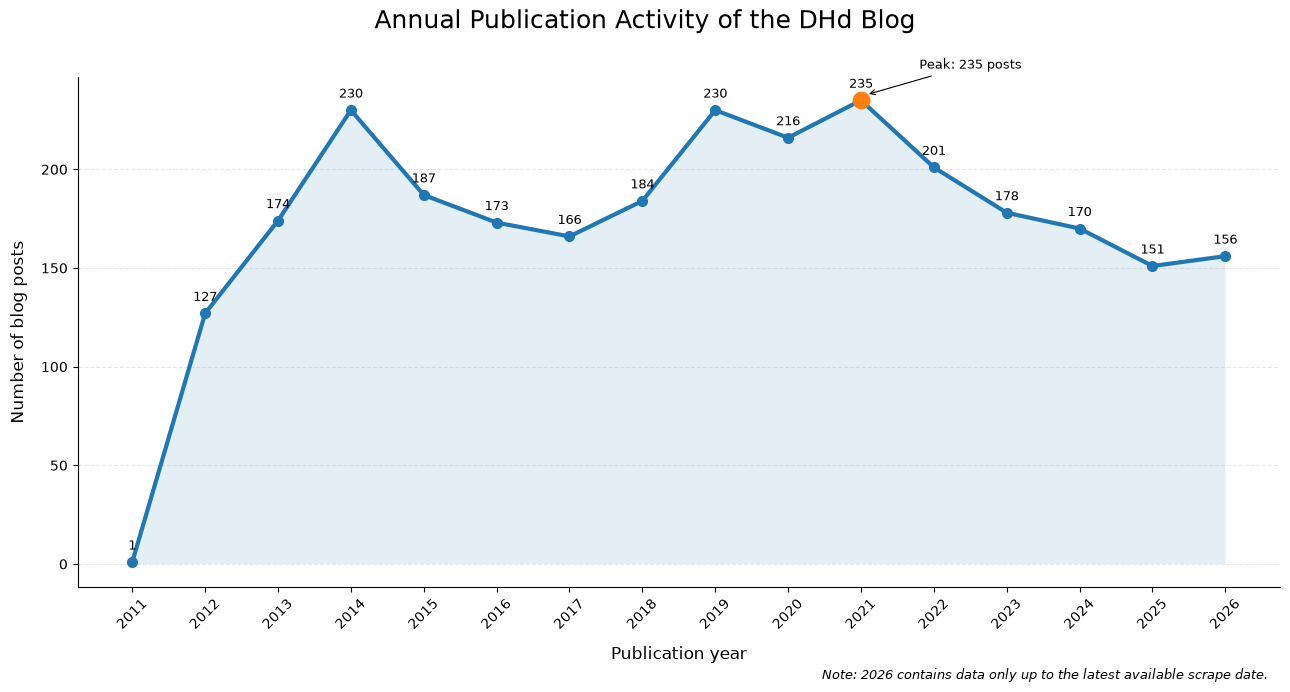

In [34]:
# Prepare data
posts_per_year = (
    analysis_df
    .groupby("year")
    .size()
    .reset_index(name="posts")
    .dropna()
)

posts_per_year["year"] = posts_per_year["year"].astype(int)

# Identify peak year
peak_row = posts_per_year.loc[
    posts_per_year["posts"].idxmax()
]

peak_year = int(peak_row["year"])
peak_posts = int(peak_row["posts"])

# Create chart
fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    posts_per_year["year"],
    posts_per_year["posts"],
    linewidth=3,
    marker="o",
    markersize=7
)

ax.fill_between(
    posts_per_year["year"],
    posts_per_year["posts"],
    alpha=0.12
)

# Add value labels
for _, row in posts_per_year.iterrows():
    ax.annotate(
        f"{int(row['posts'])}",
        (row["year"], row["posts"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9
    )

# Highlight the peak
ax.scatter(
    peak_year,
    peak_posts,
    s=140,
    zorder=5
)

ax.annotate(
    f"Peak: {peak_posts} posts",
    xy=(peak_year, peak_posts + 2),
    xytext=(peak_year + 0.8, peak_posts + 16),   # Closer
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8,
        shrinkA=4,
        shrinkB=6
    ),
    zorder=10,
    fontsize=9,
    fontweight="medium",
    fontfamily="DejaVu Sans",
)

# Title and subtitle
fig.suptitle(
    "Annual Publication Activity of the DHd Blog",
    fontsize=18,
    fontweight="medium",
    fontfamily="DejaVu Sans",
    y=0.99
)

plt.subplots_adjust(top=0.88)   # more space between title and chart


# Axis labels
ax.set_xlabel(
    "Publication year",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of blog posts",
    fontsize=12,
    labelpad=10
)

# Ticks
ax.set_xticks(posts_per_year["year"])
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="both", labelsize=10)

# Grid and styling
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Note for incomplete year
if 2026 in posts_per_year["year"].values:
    ax.text(
        0.99,
        -0.18,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic"
    )

plt.tight_layout()

# Save high-quality image
plt.savefig(
    FIGURE_DIR / "fig01_dhd_posts_per_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3. Posts per month

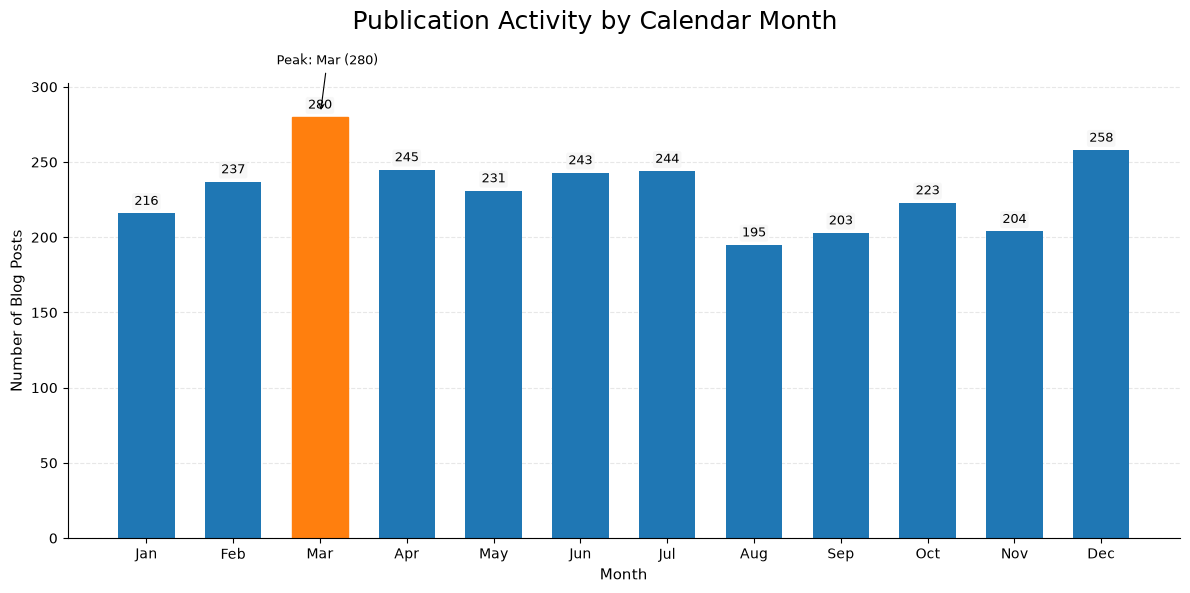

In [35]:
# Prepare data
posts_by_month = (
    analysis_df
    .groupby("month")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Highest month
peak_month = posts_by_month.idxmax()
peak_posts = posts_by_month.max()

# Create chart
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    month_labels,
    posts_by_month.values,
    width=0.65
)

# Highlight busiest month
bars[peak_month - 1].set_color("tab:orange")

# Add value labels
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f7f7f7",
            edgecolor="none",
            alpha=0.9
        )
    )

# Annotate busiest month
ax.annotate(
    f"Peak: {month_labels[peak_month-1]} ({peak_posts})",
    xy=(peak_month-1, peak_posts),
    xytext=(peak_month-1.5, peak_posts+35),
    fontsize=9,
    fontweight="medium",
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8,
        shrinkA=4,
        shrinkB=5
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=0.3
    )
)

# Title
fig.suptitle(
    "Publication Activity by Calendar Month",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

plt.subplots_adjust(top=0.88)

# Axis labels
ax.set_xlabel(
    "Month",
    fontsize=11
)

ax.set_ylabel(
    "Number of Blog Posts",
    fontsize=11
)

# Styling
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)

ax.margins(y=0.08)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig02_posts_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 4. Top Categories

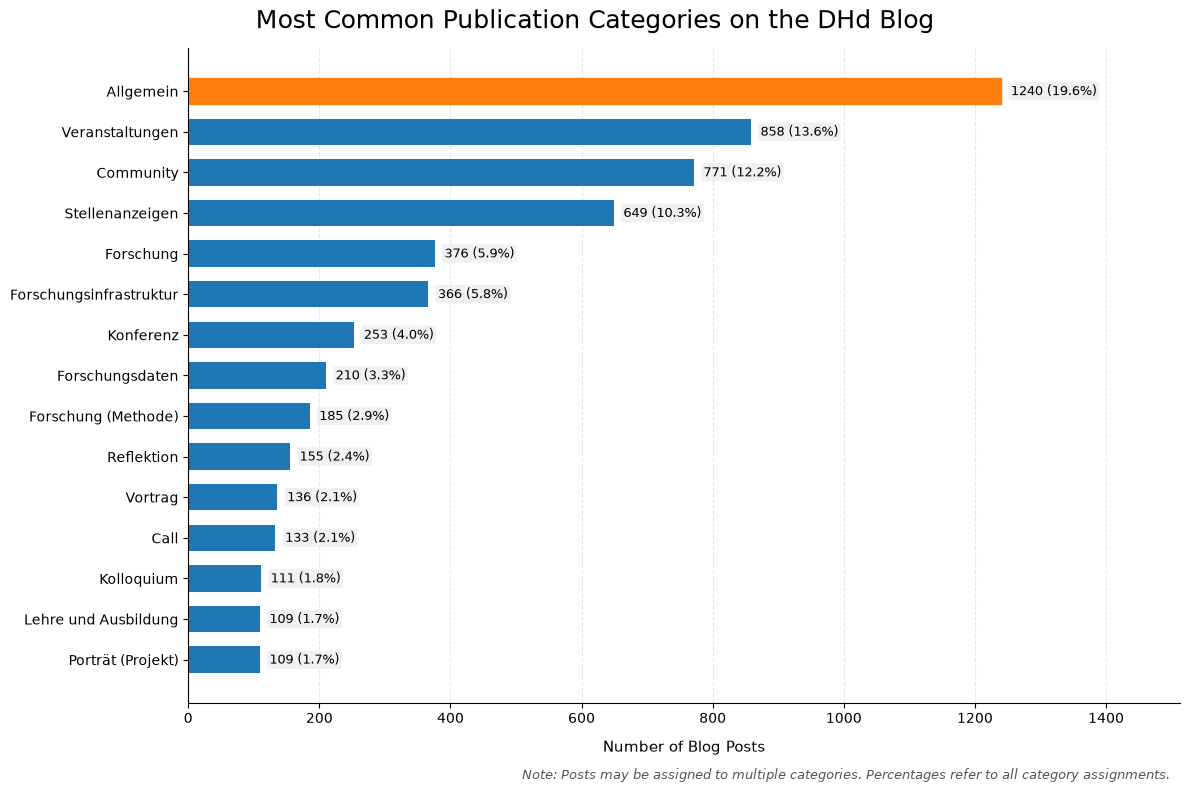

,category,posts,percentage
14,Allgemein,1240,19.598546
13,Veranstaltungen,858,13.560929
12,Community,771,12.185870
11,Stellenanzeigen,649,10.257626
10,Forschung,376,5.942785
9,Forschungsinfrastruktur,366,5.784732
8,Konferenz,253,3.998736
7,Forschungsdaten,210,3.319109
6,Forschung (Methode),185,2.923977
5,Reflektion,155,2.449818


In [36]:
# ------------------------------------------------------------
# Prepare category data
# ------------------------------------------------------------

category_df = (
    analysis_df[
        ["post_id", "year", "publication_date", "categories"]
    ]
    .assign(
        category=lambda x: (
            x["categories"]
            .fillna("")
            .str.split(r"\s*\|\s*")
        )
    )
    .explode("category")
)

category_df["category"] = (
    category_df["category"]
    .fillna("")
    .str.strip()
)

category_df = category_df[
    category_df["category"] != ""
].copy()

# Count categories
category_counts = (
    category_df["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="posts")
)

# Total category assignments
# A post may have more than one category.
total_category_assignments = category_counts["posts"].sum()

# Select top 15 categories
top_categories = (
    category_counts
    .head(15)
    .copy()
)

# Percentage is based on all category assignments
top_categories["percentage"] = (
    top_categories["posts"]
    / total_category_assignments
    * 100
)

# Sort ascending so the largest category appears at the top
top_categories = top_categories.sort_values(
    "posts",
    ascending=True
).reset_index(drop=True)

# ------------------------------------------------------------
# Create chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    top_categories["category"],
    top_categories["posts"],
    height=0.65
)

# Highlight the largest category
bars[-1].set_color("tab:orange")

# Add count and percentage labels
for bar, posts, percentage in zip(
    bars,
    top_categories["posts"],
    top_categories["percentage"]
):
    ax.annotate(
        f"{int(posts)} ({percentage:.1f}%)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        ha="left",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# ------------------------------------------------------------
# Title and labels
# ------------------------------------------------------------

fig.suptitle(
    "Most Common Publication Categories on the DHd Blog",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Number of Blog Posts",
    fontsize=11,
    labelpad=10
)

# The category names already explain the y-axis
ax.set_ylabel("")

# ------------------------------------------------------------
# Grid and styling
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

# Give labels enough room to the right
maximum_posts = top_categories["posts"].max()

ax.set_xlim(
    0,
    maximum_posts * 1.22
)

# Methodological note
ax.text(
    0.99,
    -0.10,
    (
        "Note: Posts may be assigned to multiple categories. "
        "Percentages refer to all category assignments."
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality image
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "fig03_top_dhd_blog_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Optional: display the underlying values
display(
    top_categories[
        ["category", "posts", "percentage"]
    ].sort_values(
        "posts",
        ascending=False
    )
)


## 5. Word Count Distribution

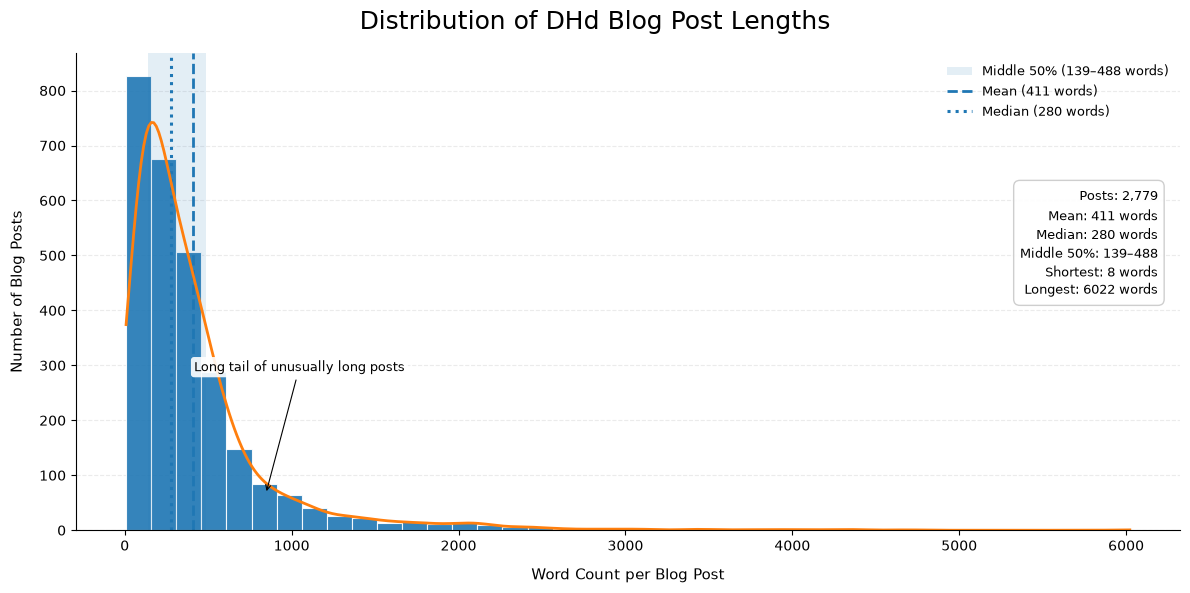

In [37]:
# ------------------------------------------------------------
# Prepare word-count data
# ------------------------------------------------------------

word_counts = (
    analysis_df["word_count"]
    .dropna()
    .astype(float)
)

mean_words = word_counts.mean()
median_words = word_counts.median()
q1 = word_counts.quantile(0.25)
q3 = word_counts.quantile(0.75)
min_words = word_counts.min()
max_words = word_counts.max()

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

# Histogram
counts, bins, patches = ax.hist(
    word_counts,
    bins=40,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Shade the middle 50% of posts
ax.axvspan(
    q1,
    q3,
    alpha=0.12,
    label=f"Middle 50% ({q1:.0f}–{q3:.0f} words)"
)

# Mean and median lines
ax.axvline(
    mean_words,
    linestyle="--",
    linewidth=2,
    label=f"Mean ({mean_words:.0f} words)"
)

ax.axvline(
    median_words,
    linestyle=":",
    linewidth=2.2,
    label=f"Median ({median_words:.0f} words)"
)

# Smooth density curve scaled to histogram counts
density = gaussian_kde(word_counts)

x_values = np.linspace(
    word_counts.min(),
    word_counts.max(),
    400
)

bin_width = bins[1] - bins[0]

density_values = (
    density(x_values)
    * len(word_counts)
    * bin_width
)

ax.plot(
    x_values,
    density_values,
    linewidth=2
)

# ------------------------------------------------------------
# Summary statistics box
# ------------------------------------------------------------

summary_text = (
    f"Posts: {len(word_counts):,}\n"
    f"Mean: {mean_words:.0f} words\n"
    f"Median: {median_words:.0f} words\n"
    f"Middle 50%: {q1:.0f}–{q3:.0f}\n"
    f"Shortest: {min_words:.0f} words\n"
    f"Longest: {max_words:.0f} words"
)

ax.text(
    0.98,
    0.72,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#cccccc",
        alpha=0.95
    )
)

# ------------------------------------------------------------
# Long-tail annotation
# ------------------------------------------------------------

tail_x = word_counts.quantile(0.90)

ax.annotate(
    "Long tail of unusually long posts",
    xy=(tail_x, max(counts) * 0.08),
    xytext=(word_counts.quantile(0.67), max(counts) * 0.35),
    fontsize=9,
    arrowprops=dict(
        arrowstyle="->",
        linewidth=0.8
    ),
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        edgecolor="none",
        alpha=0.9
    )
)

# ------------------------------------------------------------
# Title and labels
# ------------------------------------------------------------

fig.suptitle(
    "Distribution of DHd Blog Post Lengths",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Word Count per Blog Post",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Number of Blog Posts",
    fontsize=11,
    labelpad=10
)

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality figure
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "fig05_word_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Average Word Count by Year

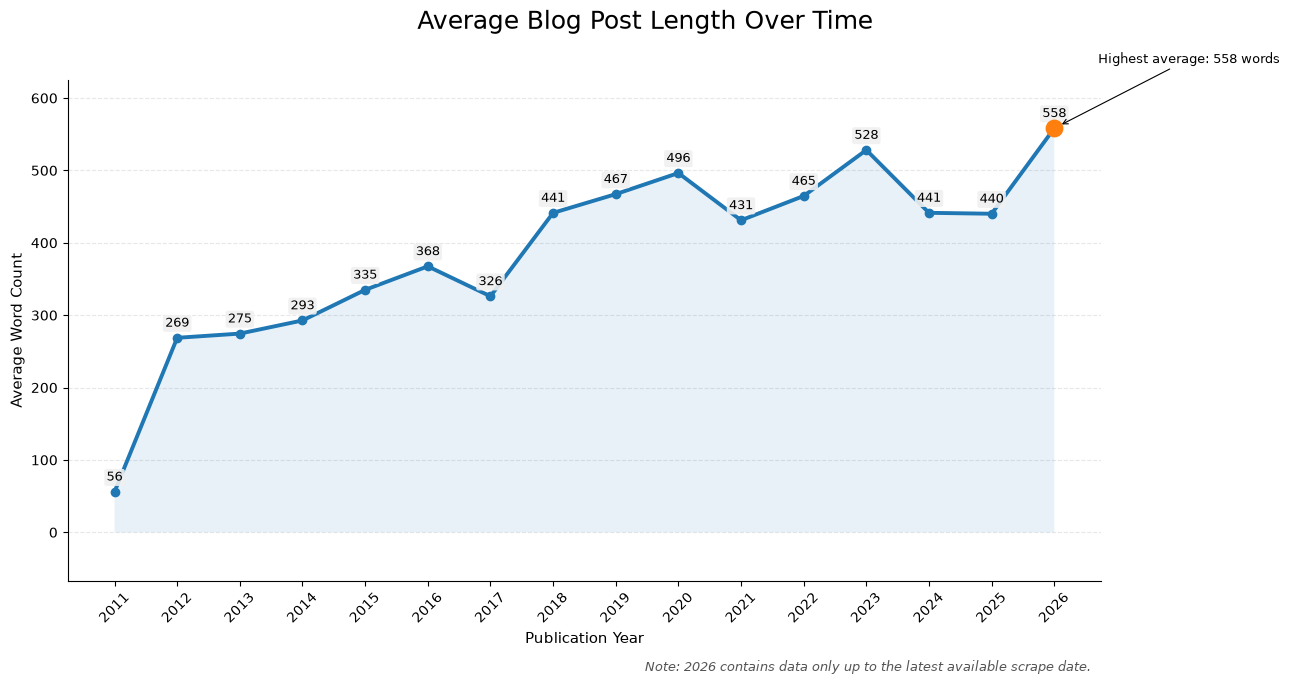

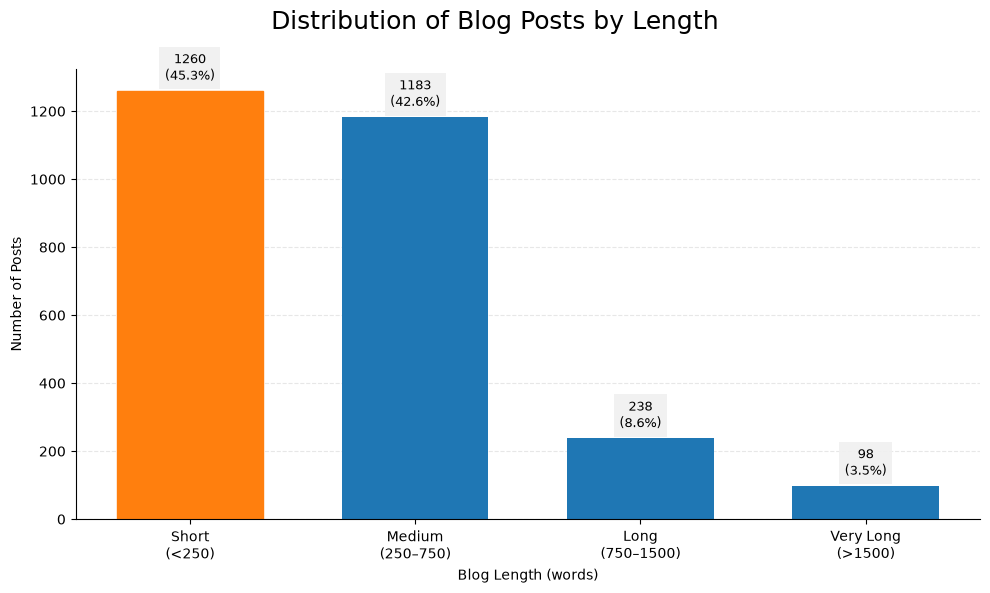

In [38]:
# ------------------------------------------------------------
# Average word count by year
# ------------------------------------------------------------

yearly_words = (
    analysis_df
    .groupby("year")["word_count"]
    .mean()
    .reset_index(name="avg_words")
)

yearly_words["year"] = yearly_words["year"].astype(int)

# Highest average
peak_row = yearly_words.loc[
    yearly_words["avg_words"].idxmax()
]

peak_year = int(peak_row["year"])
peak_words = peak_row["avg_words"]

# ------------------------------------------------------------
# Create chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    yearly_words["year"],
    yearly_words["avg_words"],
    linewidth=2.8,
    marker="o",
    markersize=6
)

ax.fill_between(
    yearly_words["year"],
    yearly_words["avg_words"],
    alpha=0.10
)

# ------------------------------------------------------------
# Add labels
# ------------------------------------------------------------

for _, row in yearly_words.iterrows():

    ax.annotate(
        f"{row['avg_words']:.0f}",
        xy=(row["year"], row["avg_words"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# ------------------------------------------------------------
# Highlight highest year
# ------------------------------------------------------------

ax.scatter(
    peak_year,
    peak_words,
    s=140,
    zorder=5
)

ax.annotate(
    f"Highest average: {peak_words:.0f} words",
    xy=(peak_year, peak_words),
    xytext=(peak_year + 0.7, peak_words + 90),
    fontsize=9,
    fontweight="medium",
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8,
        shrinkA=4,
        shrinkB=6
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=0.3
    )
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

fig.suptitle(
    "Average Blog Post Length Over Time",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

plt.subplots_adjust(top=0.88)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Publication Year",
    fontsize=11
)

ax.set_ylabel(
    "Average Word Count",
    fontsize=11
)

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

ax.set_xticks(yearly_words["year"])

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(y=0.12)

# ------------------------------------------------------------
# Note
# ------------------------------------------------------------

if 2026 in yearly_words["year"].values:
    ax.text(
        0.99,
        -0.18,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic",
        color="#555555"
    )

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "fig06_average_blog_post_length_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




# ============================================================
# Categorize blog lengths
# ============================================================

length_df = analysis_df.copy()

bins = [0, 250, 750, 1500, float("inf")]

labels = [
    "Short\n(<250)",
    "Medium\n(250–750)",
    "Long\n(750–1500)",
    "Very Long\n(>1500)"
]

length_df["length_category"] = pd.cut(
    length_df["word_count"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

length_counts = (
    length_df["length_category"]
    .value_counts(sort=False)
    .reset_index()
)

length_counts.columns = ["Category", "Posts"]

length_counts["Percentage"] = (
    length_counts["Posts"]
    / length_counts["Posts"].sum()
    * 100
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    length_counts["Category"],
    length_counts["Posts"],
    width=0.65
)

# Highlight largest group
bars[length_counts["Posts"].idxmax()].set_color("tab:orange")

for bar, pct in zip(bars, length_counts["Percentage"]):

    ax.annotate(
        f"{int(bar.get_height())}\n({pct:.1f}%)",
        xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
        xytext=(0,8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Distribution of Blog Posts by Length",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel("Blog Length (words)")
ax.set_ylabel("Number of Posts")

ax.grid(axis="y", linestyle="--", alpha=0.30)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig_length_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Most Active Author Contribution

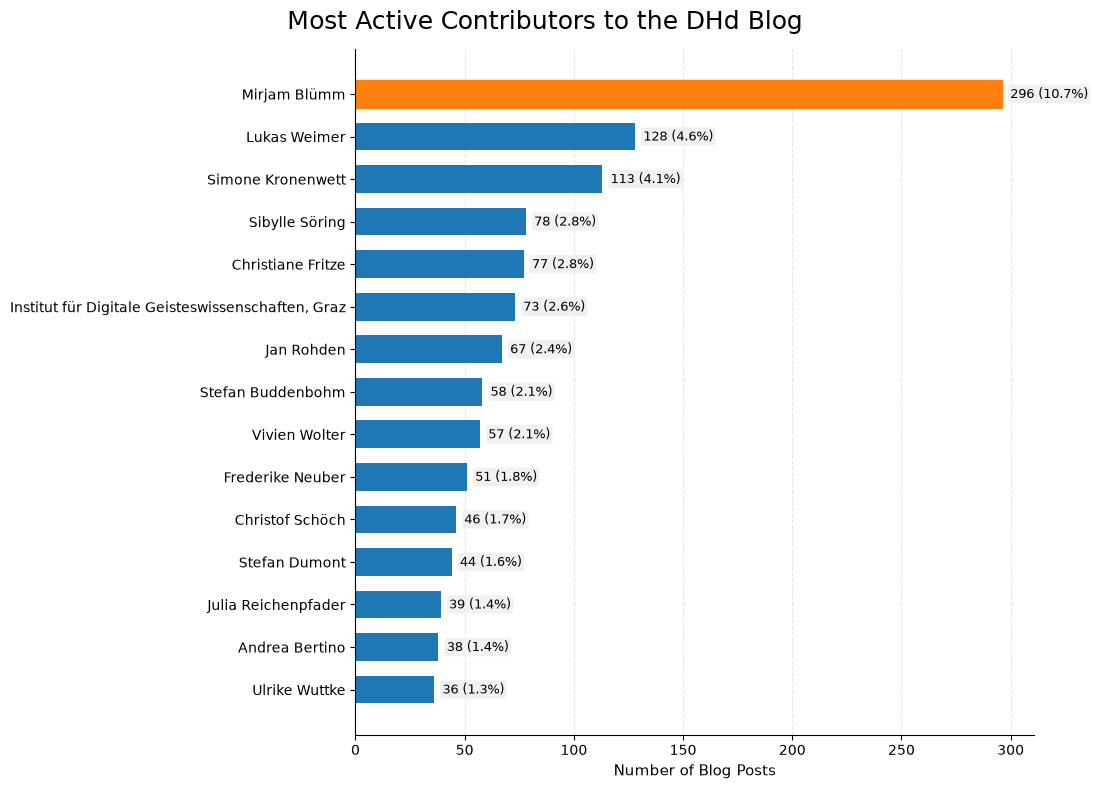

In [39]:
# ------------------------------------------------------------
# Top authors
# ------------------------------------------------------------

author_counts = (
    analysis_df["author"]
    .dropna()
    .value_counts()
    .reset_index()
)

author_counts.columns = ["author", "posts"]

top_authors = (
    author_counts
    .head(15)
    .sort_values("posts")
    .copy()
)

top_authors["percentage"] = (
    top_authors["posts"]
    / analysis_df.shape[0]
    * 100
)

# ------------------------------------------------------------
# Create chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    top_authors["author"],
    top_authors["posts"],
    height=0.65
)

# Highlight top contributor
bars[-1].set_color("tab:orange")

# Labels
for bar, posts, pct in zip(
    bars,
    top_authors["posts"],
    top_authors["percentage"]
):

    ax.annotate(
        f"{posts} ({pct:.1f}%)",
        xy=(bar.get_width(), bar.get_y()+bar.get_height()/2),
        xytext=(6,0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Active Contributors to the DHd Blog",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel("Number of Blog Posts", fontsize=11)
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.30)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig07_top_authors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 8. New Authors Joining the DHd Blog

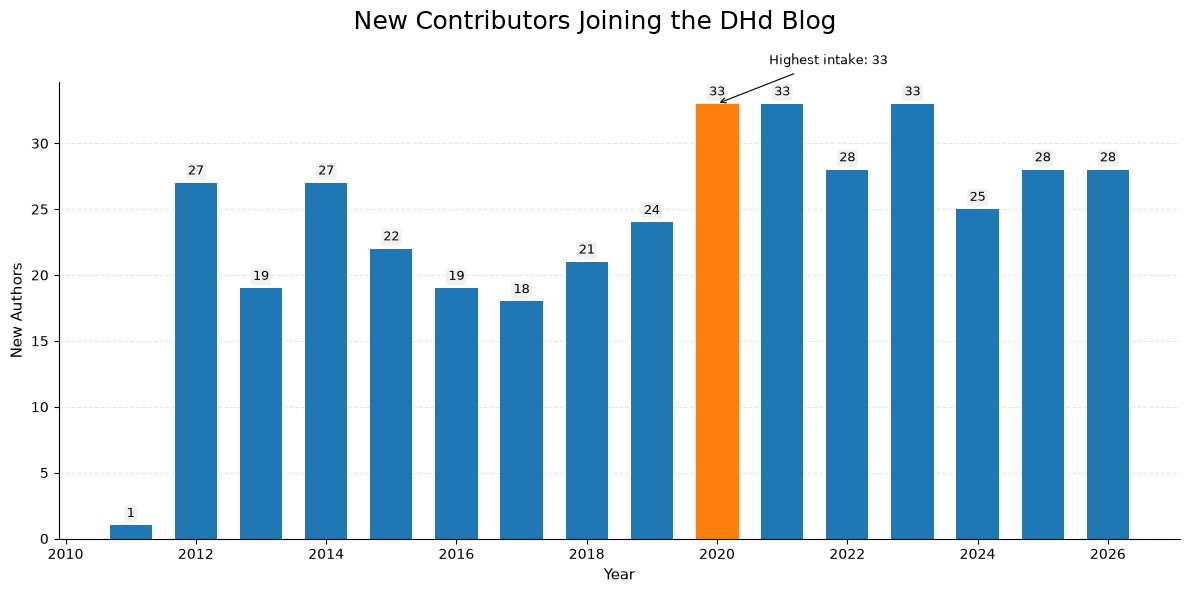

In [40]:
# ------------------------------------------------------------
# First appearance of every author
# ------------------------------------------------------------

first_author_year = (
    analysis_df
    .dropna(subset=["author"])
    .groupby("author")["year"]
    .min()
    .reset_index()
)

new_authors = (
    first_author_year
    .groupby("year")
    .size()
    .reset_index(name="new_authors")
)

# Highest year
peak = new_authors.loc[
    new_authors["new_authors"].idxmax()
]

peak_year = int(peak["year"])
peak_value = int(peak["new_authors"])

# ------------------------------------------------------------
# Chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12,6))

bars = ax.bar(
    new_authors["year"],
    new_authors["new_authors"],
    width=0.65
)

bars[
    new_authors["new_authors"].idxmax()
].set_color("tab:orange")

# Labels
for bar in bars:

    value = int(bar.get_height())

    ax.annotate(
        f"{value}",
        xy=(bar.get_x()+bar.get_width()/2, value),
        xytext=(0,6),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# Peak annotation
ax.annotate(
    f"Highest intake: {peak_value}",
    xy=(peak_year, peak_value),
    xytext=(peak_year+0.8, peak_value+3),
    fontsize=9,
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9
    )
)

fig.suptitle(
    "New Contributors Joining the DHd Blog",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("New Authors", fontsize=11)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig08_new_authors_per_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Top 20 Tags and Tags Co-occurence Heatmap

Unique tags: 1774
Posts with at least one tag: 2061


,tag,posts,percentage
0,Stellenausschreibung,256,12.421155
1,Digital Humanities,246,11.935953
2,Berlin,220,10.674430
3,Digitale Edition,179,8.685104
4,DARIAH-DE,163,7.908782
5,Forschungsdaten,146,7.083940
6,Workshop,142,6.889859
7,TELOTA,120,5.822416
8,Text+,97,4.706453
9,TextGrid,84,4.075691


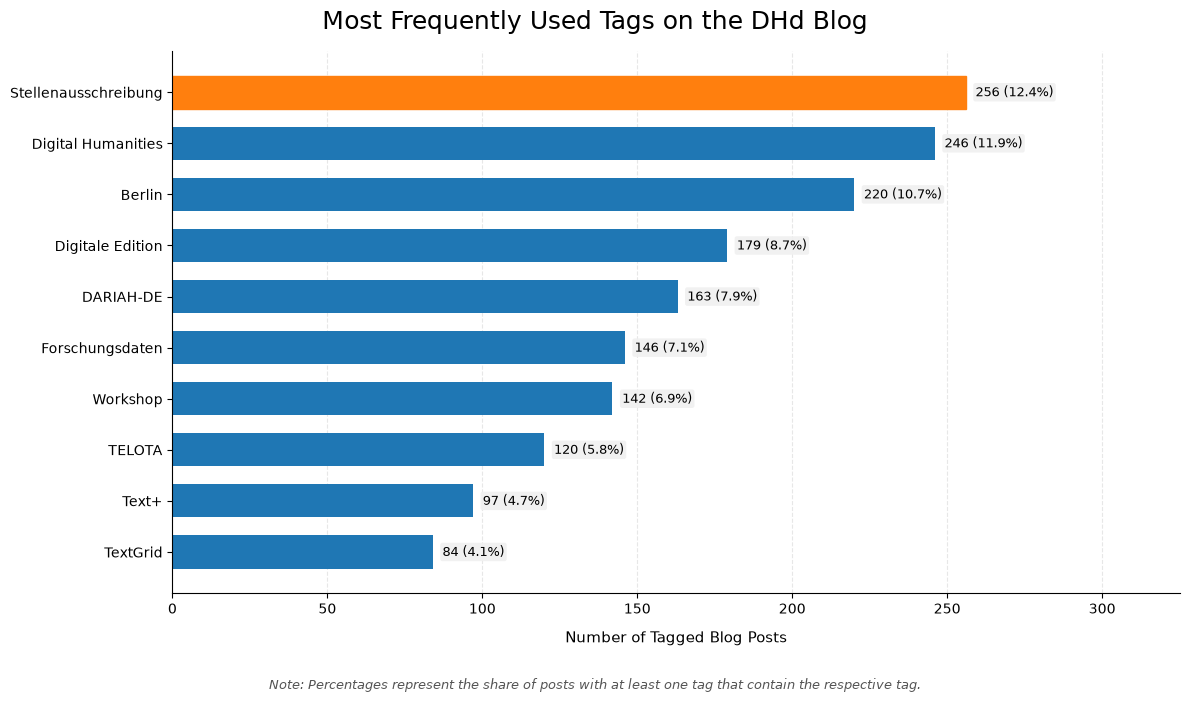

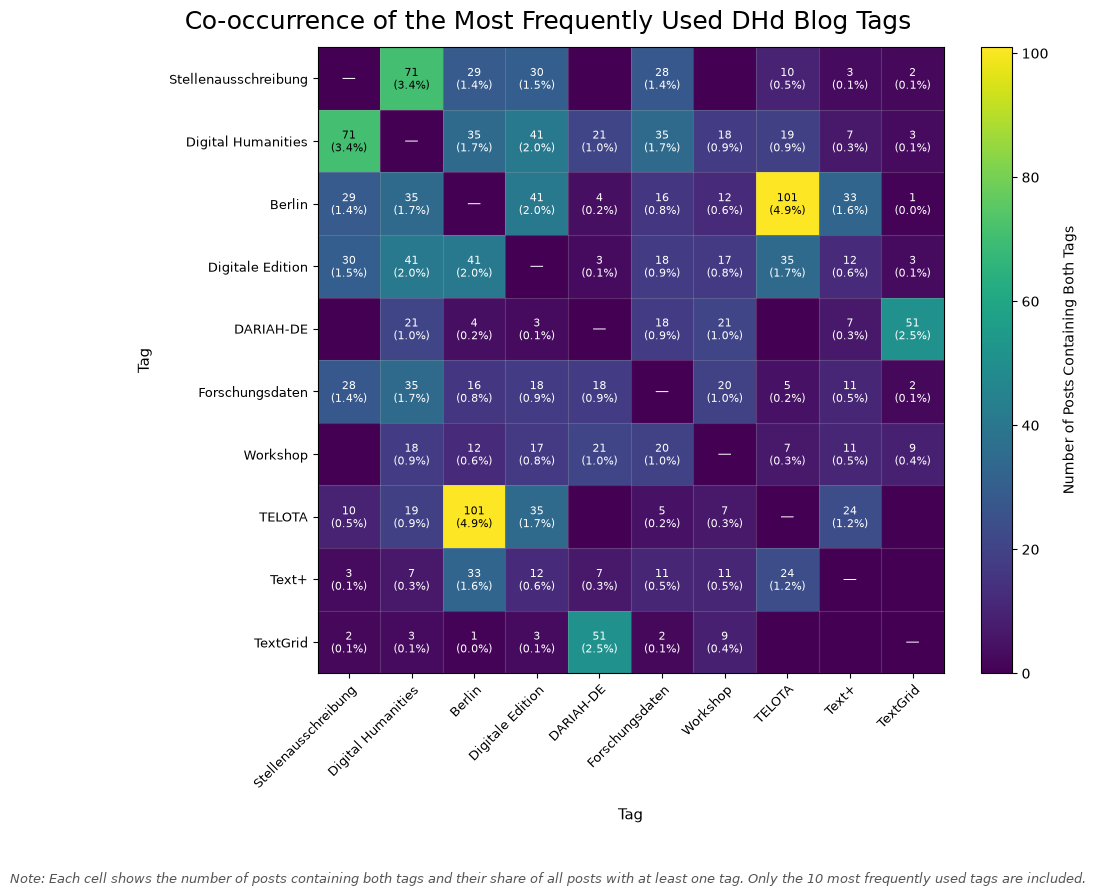

Top 10 strongest tag relationships:


,tag_1,tag_2,cooccurring_posts,percentage_of_tagged_posts
0,Berlin,TELOTA,101,4.9
1,Digital Humanities,Stellenausschreibung,71,3.4
2,DARIAH-DE,TextGrid,51,2.5
3,Berlin,Digitale Edition,41,2.0
4,Digital Humanities,Digitale Edition,41,2.0
5,Berlin,Digital Humanities,35,1.7
6,Digitale Edition,TELOTA,35,1.7
7,Digital Humanities,Forschungsdaten,35,1.7
8,Berlin,Text+,33,1.6
9,Digitale Edition,Stellenausschreibung,30,1.5


,Stellenausschreibung,Digital Humanities,Berlin,Digitale Edition,DARIAH-DE,Forschungsdaten,Workshop,TELOTA,Text+,TextGrid
Stellenausschreibung,NaN,27.7,11.3,11.7,0.0,10.9,0.0,3.9,1.2,0.8
Digital Humanities,28.9,NaN,14.2,16.7,8.5,14.2,7.3,7.7,2.8,1.2
Berlin,13.2,15.9,NaN,18.6,1.8,7.3,5.5,45.9,15.0,0.5
Digitale Edition,16.8,22.9,22.9,NaN,1.7,10.1,9.5,19.6,6.7,1.7
DARIAH-DE,0.0,12.9,2.5,1.8,NaN,11.0,12.9,0.0,4.3,31.3
Forschungsdaten,19.2,24.0,11.0,12.3,12.3,NaN,13.7,3.4,7.5,1.4
Workshop,0.0,12.7,8.5,12.0,14.8,14.1,NaN,4.9,7.7,6.3
TELOTA,8.3,15.8,84.2,29.2,0.0,4.2,5.8,NaN,20.0,0.0
Text+,3.1,7.2,34.0,12.4,7.2,11.3,11.3,24.7,NaN,0.0
TextGrid,2.4,3.6,1.2,3.6,60.7,2.4,10.7,0.0,0.0,NaN


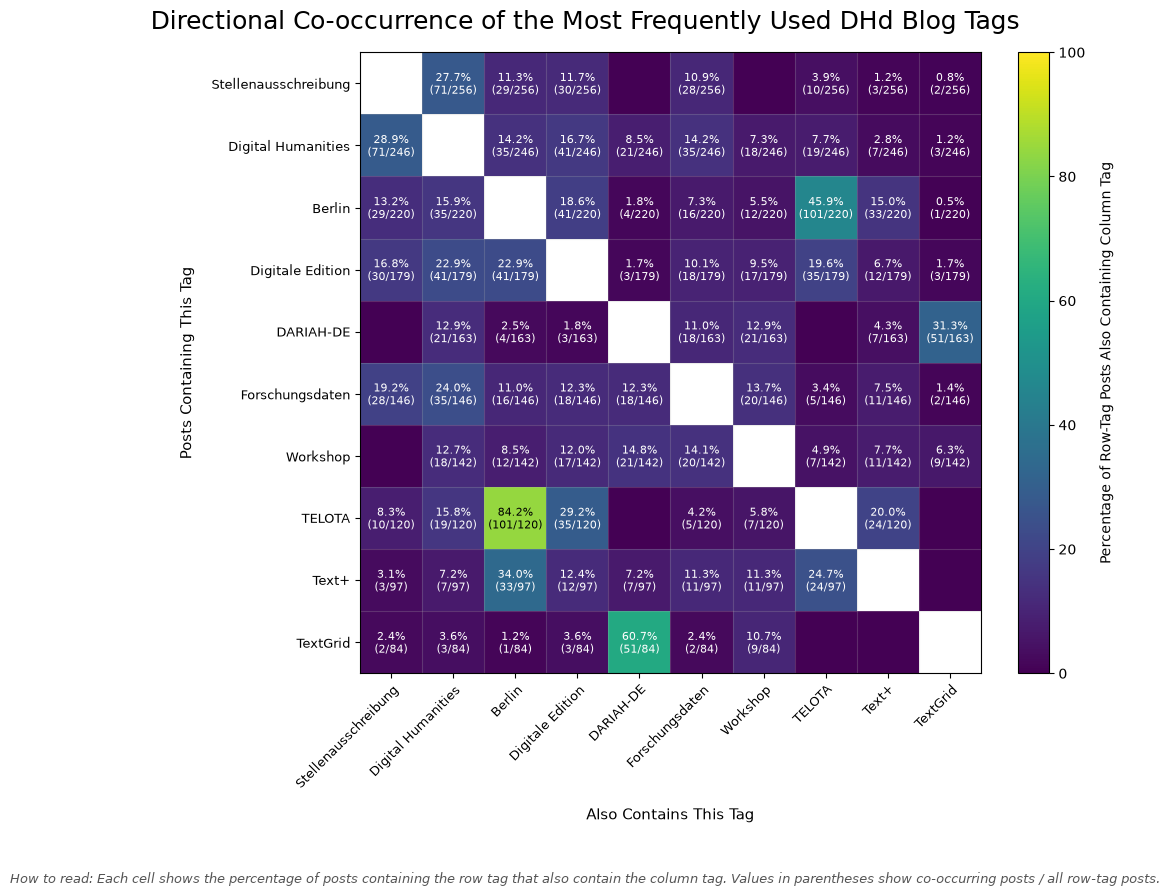

101 posts contain both 'TELOTA' and 'Berlin'.
TELOTA → Berlin: 84.2% of posts tagged 'TELOTA' are also tagged 'Berlin' (101/120).
Berlin → TELOTA: 45.9% of posts tagged 'Berlin' are also tagged 'TELOTA' (101/220).


In [41]:
# ============================================================
# 1. PREPARE CLEAN TAG DATA
# ============================================================

tag_source = analysis_df[
    ["post_id", "year", "tags"]
].copy()

tag_source["tags"] = (
    tag_source["tags"]
    .fillna("")
    .astype(str)
)

tag_df = (
    tag_source
    .assign(
        tag=lambda data:
        data["tags"].str.split(r"\s*\|\s*")
    )
    .explode("tag")
)

tag_df["tag"] = (
    tag_df["tag"]
    .fillna("")
    .str.strip()
)

# Remove empty tags
tag_df = tag_df[
    tag_df["tag"].ne("")
].copy()

# Count every post only once per tag
tag_df = tag_df.drop_duplicates(
    subset=["post_id", "tag"]
)

tag_counts = (
    tag_df
    .groupby("tag")["post_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("posts")
    .reset_index()
)

# Posts containing at least one tag
posts_with_tags = tag_df["post_id"].nunique()

tag_counts["percentage"] = (
    tag_counts["posts"]
    .div(posts_with_tags)
    .mul(100)
)

print("Unique tags:", tag_counts["tag"].nunique())
print("Posts with at least one tag:", posts_with_tags)

# Display only the top 10 tags
display(
    tag_counts
    .head(10)
    .reset_index(drop=True)
)


# ============================================================
# 2. FIGURE: TOP 10 TAGS
# ============================================================

top_10_tags = (
    tag_counts
    .head(10)
    .sort_values("posts")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_10_tags["tag"],
    top_10_tags["posts"],
    height=0.65
)

# Highlight the most frequent tag
bars[-1].set_color("tab:orange")

# Add count and percentage labels
for bar, posts, percentage in zip(
    bars,
    top_10_tags["posts"],
    top_10_tags["percentage"]
):
    ax.annotate(
        f"{int(posts)} ({percentage:.1f}%)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Frequently Used Tags on the DHd Blog",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Number of Tagged Blog Posts",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.set_xlim(
    0,
    top_10_tags["posts"].max() * 1.27
)

fig.text(
    0.5,
    0.01,
    (
        "Note: Percentages represent the share of posts with at least "
        "one tag that contain the respective tag."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "fig09_top_10_dhd_blog_tags.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. BUILD CO-OCCURRENCES FOR TOP 10 TAGS
# ============================================================

heatmap_tags = (
    tag_counts
    .head(10)["tag"]
    .tolist()
)

heatmap_tag_set = set(heatmap_tags)

tag_pairs = Counter()

for tags_text in tag_source["tags"]:

    tags = {
        tag.strip()
        for tag in str(tags_text).split("|")
        if tag.strip()
    }

    # Keep only the selected top 10 tags
    selected_tags = sorted(
        tags.intersection(heatmap_tag_set)
    )

    for tag_1, tag_2 in combinations(
        selected_tags,
        2
    ):
        tag_pairs[(tag_1, tag_2)] += 1


# ============================================================
# 4. CREATE COUNT AND PERCENTAGE MATRICES
# ============================================================

cooccurrence_matrix = pd.DataFrame(
    0,
    index=heatmap_tags,
    columns=heatmap_tags,
    dtype=int
)

for (tag_1, tag_2), count in tag_pairs.items():

    cooccurrence_matrix.loc[
        tag_1,
        tag_2
    ] = count

    cooccurrence_matrix.loc[
        tag_2,
        tag_1
    ] = count

# Keep diagonal at zero because a tag cannot co-occur with itself
for tag in heatmap_tags:
    cooccurrence_matrix.loc[tag, tag] = 0

# Percentage of all tagged posts containing both tags
cooccurrence_percentage = (
    cooccurrence_matrix
    .div(posts_with_tags)
    .mul(100)
)


# ============================================================
# 5. FIGURE: TOP 10 TAG CO-OCCURRENCE HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    cooccurrence_matrix.to_numpy(),
    aspect="equal",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(heatmap_tags))
)

ax.set_xticklabels(
    heatmap_tags,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(heatmap_tags))
)

ax.set_yticklabels(
    heatmap_tags,
    fontsize=9
)

# ------------------------------------------------------------
# Add count and percentage to every non-zero cell
#
# Text colour is determined from the actual background colour:
# - dark cell  -> white text
# - light cell -> black text
# ------------------------------------------------------------

for row_index in range(len(heatmap_tags)):
    for column_index in range(len(heatmap_tags)):

        count = cooccurrence_matrix.iloc[
            row_index,
            column_index
        ]

        percentage = cooccurrence_percentage.iloc[
            row_index,
            column_index
        ]

        if count > 0:

            # Get the actual RGBA background colour of the cell
            red, green, blue, alpha = image.cmap(
                image.norm(count)
            )

            # Calculate perceived brightness
            luminance = (
                0.299 * red +
                0.587 * green +
                0.114 * blue
            )

            # White text on dark cells, black text on light cells
            text_color = (
                "black"
                if luminance > 0.55
                else "white"
            )

            ax.text(
                column_index,
                row_index,
                f"{count}\n({percentage:.1f}%)",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="normal",
                color=text_color,
                linespacing=1.15
            )

# Put a dash on the diagonal
for index in range(len(heatmap_tags)):

    diagonal_red, diagonal_green, diagonal_blue, _ = (
        image.cmap(
            image.norm(0)
        )
    )

    diagonal_luminance = (
        0.299 * diagonal_red +
        0.587 * diagonal_green +
        0.114 * diagonal_blue
    )

    diagonal_text_color = (
        "black"
        if diagonal_luminance > 0.55
        else "white"
    )

    ax.text(
        index,
        index,
        "—",
        ha="center",
        va="center",
        fontsize=10,
        color=diagonal_text_color
    )

# Add grid lines between cells
ax.set_xticks(
    np.arange(
        -0.5,
        len(heatmap_tags),
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        len(heatmap_tags),
        1
    ),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.8,
    alpha=0.25
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Add colour bar
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Number of Posts Containing Both Tags",
    fontsize=10,
    labelpad=10
)

fig.suptitle(
    "Co-occurrence of the Most Frequently Used DHd Blog Tags",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Tag",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Tag",
    fontsize=11,
    labelpad=12
)

fig.text(
    0.5,
    0.01,
    (
        "Note: Each cell shows the number of posts containing both tags "
        "and their share of all posts with at least one tag. "
        "Only the 10 most frequently used tags are included."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "fig10_top_10_tag_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. DISPLAY TOP 10 STRONGEST TAG PAIRS
# ============================================================

pair_df = pd.DataFrame(
    [
        {
            "tag_1": tag_1,
            "tag_2": tag_2,
            "cooccurring_posts": count,
            "percentage_of_tagged_posts": (
                count / posts_with_tags * 100
            )
        }
        for (tag_1, tag_2), count in tag_pairs.items()
    ]
)

if not pair_df.empty:

    pair_df = (
        pair_df
        .sort_values(
            "cooccurring_posts",
            ascending=False
        )
        .reset_index(drop=True)
    )

    pair_df["percentage_of_tagged_posts"] = (
        pair_df["percentage_of_tagged_posts"]
        .round(1)
    )

    print("Top 10 strongest tag relationships:")

    display(
        pair_df.head(10)
    )

else:

    print(
        "No co-occurring pairs were found among "
        "the selected top 10 tags."
    )


# ============================================================
# 7. CREATE DIRECTIONAL CONDITIONAL PERCENTAGE MATRIX
# ============================================================
#
# Each cell answers:
# "Of all posts containing the ROW tag, what percentage
# also contain the COLUMN tag?"
#
# Example:
# Row = TELOTA, Column = Berlin
# -> Percentage of TELOTA posts that also have Berlin
# ============================================================

# Total number of posts containing each selected tag
heatmap_tag_totals = (
    tag_df[
        tag_df["tag"].isin(heatmap_tags)
    ]
    .groupby("tag")["post_id"]
    .nunique()
    .reindex(heatmap_tags)
)

# Divide every row by the total number of posts containing
# that row's tag
conditional_percentage_matrix = (
    cooccurrence_matrix
    .div(heatmap_tag_totals, axis=0)
    .mul(100)
)

# Keep diagonal blank
for tag in heatmap_tags:
    conditional_percentage_matrix.loc[tag, tag] = np.nan

display(
    conditional_percentage_matrix.round(1)
)


# ============================================================
# 8. FIGURE: DIRECTIONAL TAG CO-OCCURRENCE HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    conditional_percentage_matrix.to_numpy(),
    aspect="equal",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(
    np.arange(len(heatmap_tags))
)

ax.set_xticklabels(
    heatmap_tags,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(heatmap_tags))
)

ax.set_yticklabels(
    heatmap_tags,
    fontsize=9
)

# ------------------------------------------------------------
# Add directional percentage, count, and denominator
# ------------------------------------------------------------

for row_index in range(len(heatmap_tags)):
    for column_index in range(len(heatmap_tags)):

        if row_index == column_index:
            ax.text(
                column_index,
                row_index,
                "—",
                ha="center",
                va="center",
                fontsize=14,
                color="white"
            )
            continue

        percentage = conditional_percentage_matrix.iloc[
            row_index,
            column_index
        ]

        count = cooccurrence_matrix.iloc[
            row_index,
            column_index
        ]

        row_total = heatmap_tag_totals.iloc[row_index]

        if pd.notna(percentage) and count > 0:

            red, green, blue, alpha = image.cmap(
                image.norm(percentage)
            )

            luminance = (
                0.299 * red +
                0.587 * green +
                0.114 * blue
            )

            text_color = (
                "black"
                if luminance > 0.55
                else "white"
            )

            ax.text(
                column_index,
                row_index,
                f"{percentage:.1f}%\n({count}/{row_total})",
                ha="center",
                va="center",
                fontsize=8,
                color=text_color,
                linespacing=1.15
            )

# Grid lines
ax.set_xticks(
    np.arange(-0.5, len(heatmap_tags), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(heatmap_tags), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.8,
    alpha=0.25
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Colour bar
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Percentage of Row-Tag Posts Also Containing Column Tag",
    fontsize=10,
    labelpad=10
)

fig.suptitle(
    "Directional Co-occurrence of the Most Frequently Used DHd Blog Tags",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Also Contains This Tag",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Posts Containing This Tag",
    fontsize=11,
    labelpad=12
)

fig.text(
    0.5,
    0.01,
    (
        "How to read: Each cell shows the percentage of posts containing "
        "the row tag that also contain the column tag. "
        "Values in parentheses show co-occurring posts / all row-tag posts."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "fig11_directional_tag_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. EXAMPLE: TELOTA AND BERLIN IN BOTH DIRECTIONS
# ============================================================

tag_a = "TELOTA"
tag_b = "Berlin"

if (
    tag_a in cooccurrence_matrix.index
    and tag_b in cooccurrence_matrix.columns
):

    both_count = cooccurrence_matrix.loc[
        tag_a,
        tag_b
    ]

    tag_a_total = heatmap_tag_totals.loc[tag_a]
    tag_b_total = heatmap_tag_totals.loc[tag_b]

    tag_a_to_b = (
        both_count / tag_a_total * 100
    )

    tag_b_to_a = (
        both_count / tag_b_total * 100
    )

    print(
        f"{both_count} posts contain both "
        f"'{tag_a}' and '{tag_b}'."
    )

    print(
        f"{tag_a} → {tag_b}: "
        f"{tag_a_to_b:.1f}% of posts tagged '{tag_a}' "
        f"are also tagged '{tag_b}' "
        f"({both_count}/{tag_a_total})."
    )

    print(
        f"{tag_b} → {tag_a}: "
        f"{tag_b_to_a:.1f}% of posts tagged '{tag_b}' "
        f"are also tagged '{tag_a}' "
        f"({both_count}/{tag_b_total})."
    )

else:

    print(
        f"The example tags '{tag_a}' and/or '{tag_b}' "
        "are not present among the top 10 tags."
    )

## 9.1. Tag Usage Trends Over Time

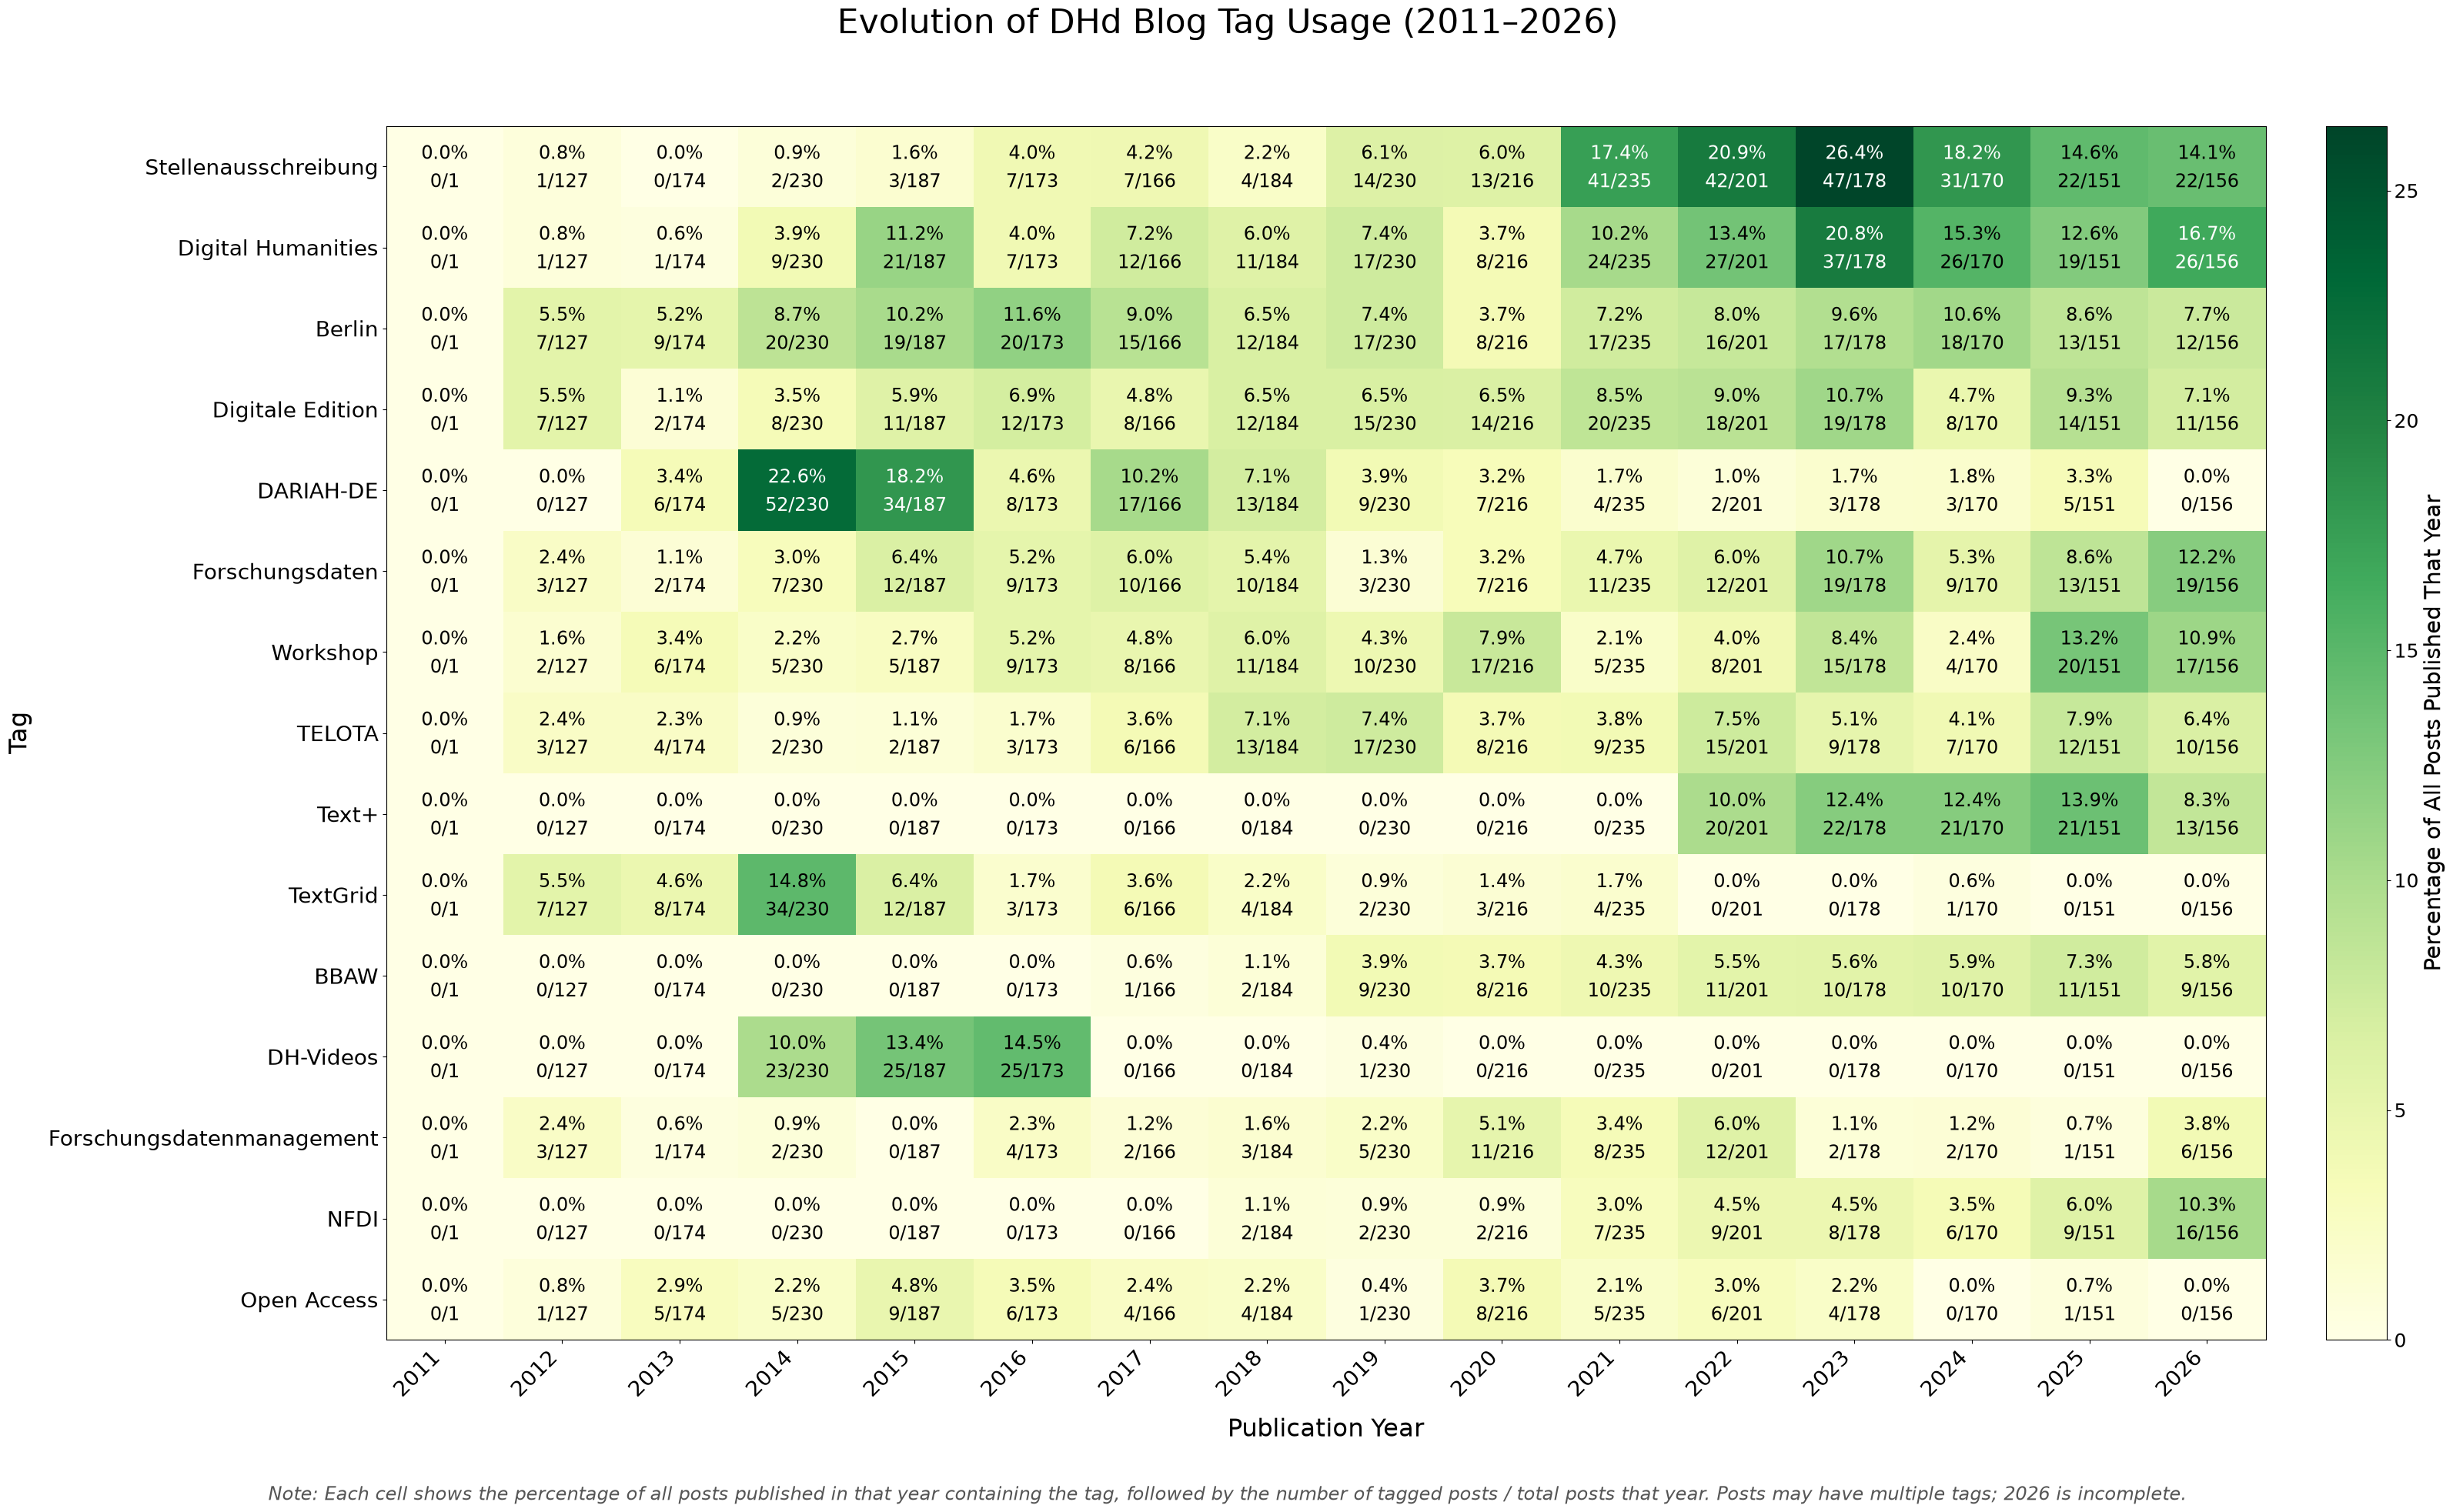

Tag usage by year (% of annual posts):


year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
tag,,,,,,,,,,,,,,,,
Stellenausschreibung,0.0,0.79,0.00,0.87,1.60,4.05,4.22,2.17,6.09,6.02,17.45,20.90,26.40,18.24,14.57,14.10
Digital Humanities,0.0,0.79,0.57,3.91,11.23,4.05,7.23,5.98,7.39,3.70,10.21,13.43,20.79,15.29,12.58,16.67
Berlin,0.0,5.51,5.17,8.70,10.16,11.56,9.04,6.52,7.39,3.70,7.23,7.96,9.55,10.59,8.61,7.69
Digitale Edition,0.0,5.51,1.15,3.48,5.88,6.94,4.82,6.52,6.52,6.48,8.51,8.96,10.67,4.71,9.27,7.05
DARIAH-DE,0.0,0.00,3.45,22.61,18.18,4.62,10.24,7.07,3.91,3.24,1.70,1.00,1.69,1.76,3.31,0.00
Forschungsdaten,0.0,2.36,1.15,3.04,6.42,5.20,6.02,5.43,1.30,3.24,4.68,5.97,10.67,5.29,8.61,12.18
Workshop,0.0,1.57,3.45,2.17,2.67,5.20,4.82,5.98,4.35,7.87,2.13,3.98,8.43,2.35,13.25,10.90
TELOTA,0.0,2.36,2.30,0.87,1.07,1.73,3.61,7.07,7.39,3.70,3.83,7.46,5.06,4.12,7.95,6.41
Text+,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,9.95,12.36,12.35,13.91,8.33


In [63]:

# ============================================================
# TAG USAGE TRENDS OVER TIME
# ============================================================
# Purpose:
# - Track the 15 most frequently used tags across years.
# - Compare tag frequency relative to annual post volume.
# - Identify emerging and declining tag usage.
# - Show percentage and actual post counts in each cell.
# ============================================================


# ------------------------------------------------------------
# 1. PREPARE TAG DATA
# ------------------------------------------------------------

tag_trend_source = analysis_df[
    ["post_id", "year", "tags"]
].dropna(subset=["year"]).copy()

tag_trend_source["year"] = (
    tag_trend_source["year"].astype(int)
)

tag_trend_source["tags"] = (
    tag_trend_source["tags"]
    .fillna("")
    .astype(str)
)

tag_trend_df = (
    tag_trend_source
    .assign(
        tag=lambda data:
        data["tags"].str.split(r"\s*\|\s*")
    )
    .explode("tag")
)

tag_trend_df["tag"] = (
    tag_trend_df["tag"]
    .fillna("")
    .str.strip()
)

tag_trend_df = tag_trend_df[
    tag_trend_df["tag"].ne("")
].drop_duplicates(
    subset=["post_id", "tag"]
)


# ------------------------------------------------------------
# 2. SELECT TOP 15 TAGS
# ------------------------------------------------------------

top_trend_tags = (
    tag_trend_df["tag"]
    .value_counts()
    .head(15)
    .index
    .tolist()
)

tag_trend_df = tag_trend_df[
    tag_trend_df["tag"].isin(top_trend_tags)
].copy()


# ------------------------------------------------------------
# 3. CALCULATE ANNUAL TAG FREQUENCY
# ------------------------------------------------------------

annual_post_totals = (
    tag_trend_source
    .groupby("year")["post_id"]
    .nunique()
)

annual_tag_counts = (
    tag_trend_df
    .groupby(["tag", "year"])["post_id"]
    .nunique()
    .unstack(fill_value=0)
)

annual_tag_counts = annual_tag_counts.reindex(
    index=top_trend_tags,
    columns=annual_post_totals.index,
    fill_value=0
)

# Percentage of all posts in each year using each tag
annual_tag_percentage = (
    annual_tag_counts
    .div(annual_post_totals, axis=1)
    .mul(100)
)


# ------------------------------------------------------------
# 4. CREATE HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(32, 20))

image = ax.imshow(
    annual_tag_percentage.values,
    aspect="auto",
    cmap="YlGn",
    vmin=0
)

ax.set_xticks(
    np.arange(len(annual_tag_percentage.columns))
)

ax.set_xticklabels(
    annual_tag_percentage.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    np.arange(len(annual_tag_percentage.index))
)

ax.set_yticklabels(
    annual_tag_percentage.index
)


# ------------------------------------------------------------
# 4.1 ADD PERCENTAGE AND POST COUNTS
# ------------------------------------------------------------

for row_index in range(len(annual_tag_percentage.index)):
    for column_index in range(len(annual_tag_percentage.columns)):

        tag = annual_tag_percentage.index[row_index]
        year = annual_tag_percentage.columns[column_index]

        # Percentage of posts containing this tag
        value = annual_tag_percentage.loc[tag, year]

        # Number of posts containing this tag
        tag_post_count = int(
            annual_tag_counts.loc[tag, year]
        )

        # Total posts published in that year
        total_post_count = int(
            annual_post_totals.loc[year]
        )

        # Show percentage and counts on separate lines
        cell_label = (
            f"{value:.1f}%\n"
            f"{tag_post_count}/{total_post_count}"
        )

        ax.text(
            column_index,
            row_index,
            cell_label,
            ha="center",
            va="center",
            fontsize=17,
            fontweight="medium",
            linespacing=1.6,
            color=(
                "black"
                if value < annual_tag_percentage.values.max() * 0.60
                else "white"
            )
        )


# ------------------------------------------------------------
# 4.2 COLORBAR
# ------------------------------------------------------------

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

colorbar.set_label(
    "Percentage of All Posts Published That Year",
    fontsize=21
)

colorbar.ax.tick_params(
    labelsize=18
)


# ------------------------------------------------------------
# 4.3 TITLE AND AXIS LABELS
# ------------------------------------------------------------

fig.suptitle(
    "Evolution of DHd Blog Tag Usage (2011–2026)",
    fontsize=32,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel(
    "Publication Year",
    fontsize=23,
    labelpad=15
)

ax.set_ylabel(
    "Tag",
    fontsize=23,
    labelpad=15
)

ax.tick_params(
    axis="both",
    labelsize=20
)


# ------------------------------------------------------------
# 4.4 FIGURE NOTE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.01,
    (
        "Note: Each cell shows the percentage of all posts "
        "published in that year containing the tag, followed "
        "by the number of tagged posts / total posts that year. "
        "Posts may have multiple tags; 2026 is incomplete."
    ),
    ha="center",
    fontsize=17,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.04, 1, 0.94]
)


# ------------------------------------------------------------
# 5. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "9_1_tag_usage_trends_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. DISPLAY SUMMARY TABLE
# ------------------------------------------------------------

print("Tag usage by year (% of annual posts):")

display(
    annual_tag_percentage.round(2)
)


## 9.2. Emerging and Declining Tags

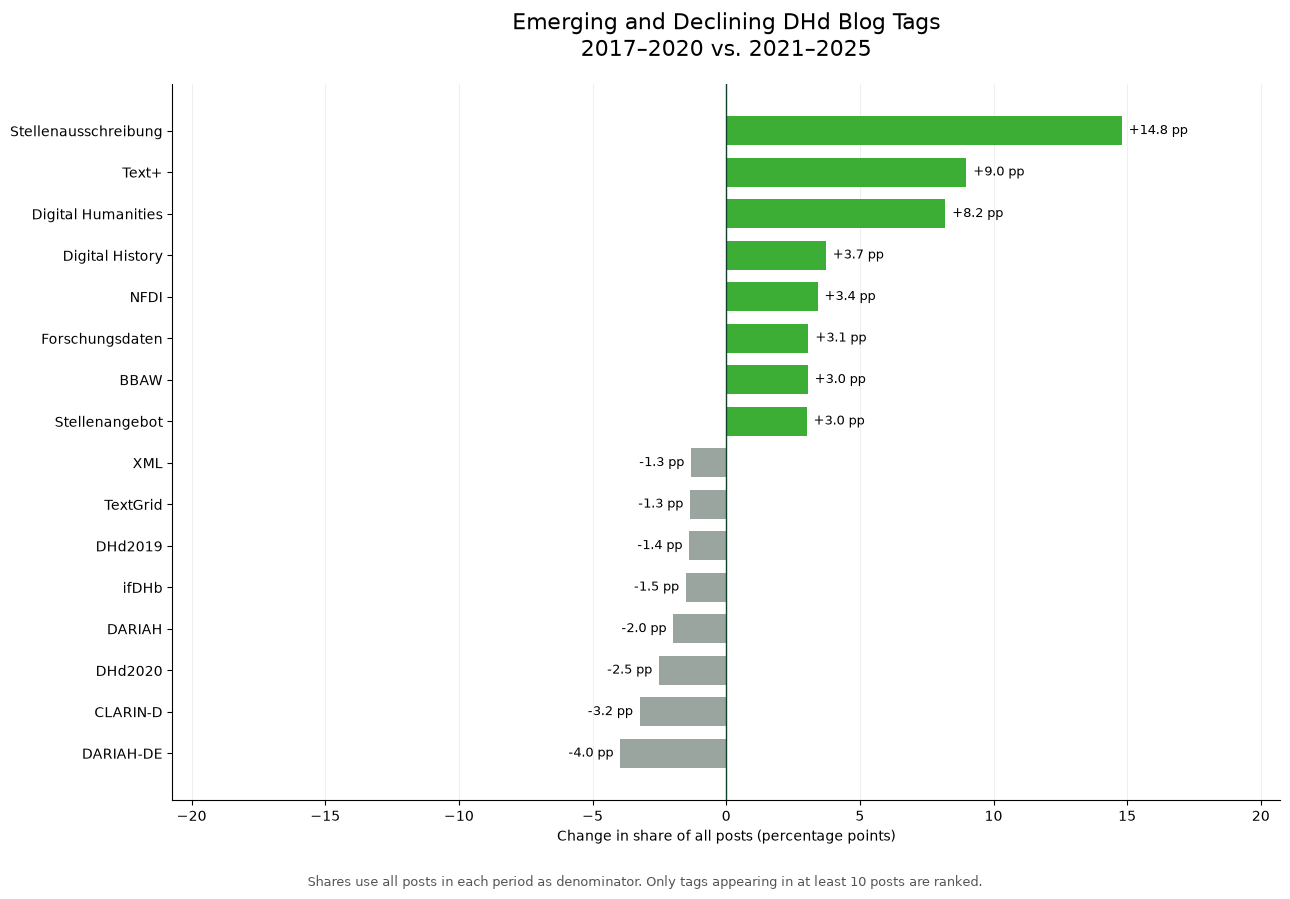

Total posts per period:


,Posts
period,
2017–2020,796
2021–2025,935



Largest changes (percentage points):


,Earlier posts,Recent posts,Earlier %,Recent %,Change (pp),Total posts
tag,,,,,,
DARIAH-DE,46,17,5.78,1.82,-3.96,63
CLARIN-D,30,5,3.77,0.53,-3.23,35
DHd2020,20,0,2.51,0.00,-2.51,20
DARIAH,20,5,2.51,0.53,-1.98,25
ifDHb,12,0,1.51,0.00,-1.51,12
DHd2019,11,0,1.38,0.00,-1.38,11
TextGrid,15,5,1.88,0.53,-1.35,20
XML,13,3,1.63,0.32,-1.31,16
Stellenangebot,5,34,0.63,3.64,3.01,39


In [43]:
# ============================================================
# 9.2 EMERGING AND DECLINING TAGS
# ============================================================

# 1. Prepare all tags (not just the top 15 from Section 9.1)
s92 = analysis_df[["post_id", "year", "tags"]].copy()
s92["year"] = pd.to_numeric(s92["year"], errors="coerce")
s92 = s92.dropna(subset=["year", "post_id"])
s92["year"] = s92["year"].astype(int)
s92 = s92[s92["year"].between(2017, 2025)].drop_duplicates("post_id")

s92["period"] = np.where(
    s92["year"] <= 2020, "2017–2020", "2021–2025"
)

t92 = s92.assign(
    tag=s92["tags"].fillna("").astype(str).str.split(r"\s*\|\s*")
).explode("tag")

t92["tag"] = t92["tag"].fillna("").str.strip()
t92 = t92[t92["tag"].ne("")].drop_duplicates(["post_id", "tag"])

periods92 = ["2017–2020", "2021–2025"]
totals92 = s92.groupby("period")["post_id"].nunique()

counts92 = (
    t92.groupby(["tag", "period"])["post_id"]
    .nunique().unstack(fill_value=0)
    .reindex(columns=periods92, fill_value=0)
)

shares92 = counts92.div(totals92, axis=1) * 100

results92 = pd.DataFrame({
    "Earlier posts": counts92[periods92[0]],
    "Recent posts": counts92[periods92[1]],
    "Earlier %": shares92[periods92[0]],
    "Recent %": shares92[periods92[1]],
})

results92["Change (pp)"] = (
    results92["Recent %"] - results92["Earlier %"]
)
results92["Total posts"] = (
    results92["Earlier posts"] + results92["Recent posts"]
)

# Minimum support prevents rare tags from dominating the ranking.
MIN_POSTS = 10
eligible92 = results92[results92["Total posts"] >= MIN_POSTS]

selected92 = pd.concat([
    eligible92.nsmallest(8, "Change (pp)"),
    eligible92.nlargest(8, "Change (pp)")
]).drop_duplicates().sort_values("Change (pp)")

# 2. Plot
GREEN = "#3DAE35"
DARK = "#123F28"
GREY = "#9AA5A0"

fig, ax = plt.subplots(figsize=(13, 9))

colors = [
    GREEN if value > 0 else GREY
    for value in selected92["Change (pp)"]
]

ax.barh(
    selected92.index,
    selected92["Change (pp)"],
    color=colors,
    height=0.7
)
ax.axvline(0, color=DARK, linewidth=1)

for y, value in enumerate(selected92["Change (pp)"]):
    ax.annotate(
        f"{value:+.1f} pp",
        (value, y),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Emerging and Declining DHd Blog Tags\n"
    "2017–2020 vs. 2021–2025",
    fontsize=16, pad=20
)
ax.set_xlabel("Change in share of all posts (percentage points)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

limit = max(abs(selected92["Change (pp)"]).max() * 1.4, 1)
ax.set_xlim(-limit, limit)

fig.text(
    0.5, 0.01,
    "Shares use all posts in each period as denominator. "
    "Only tags appearing in at least 10 posts are ranked.",
    ha="center", fontsize=9, color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(
    FIGURE_DIR / "9_2_emerging_declining_tags.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Total posts per period:")
display(totals92.to_frame("Posts"))
print("\nLargest changes (percentage points):")
display(selected92.round(2))


## 9.3. Tag Trajectories and Trend Analysis

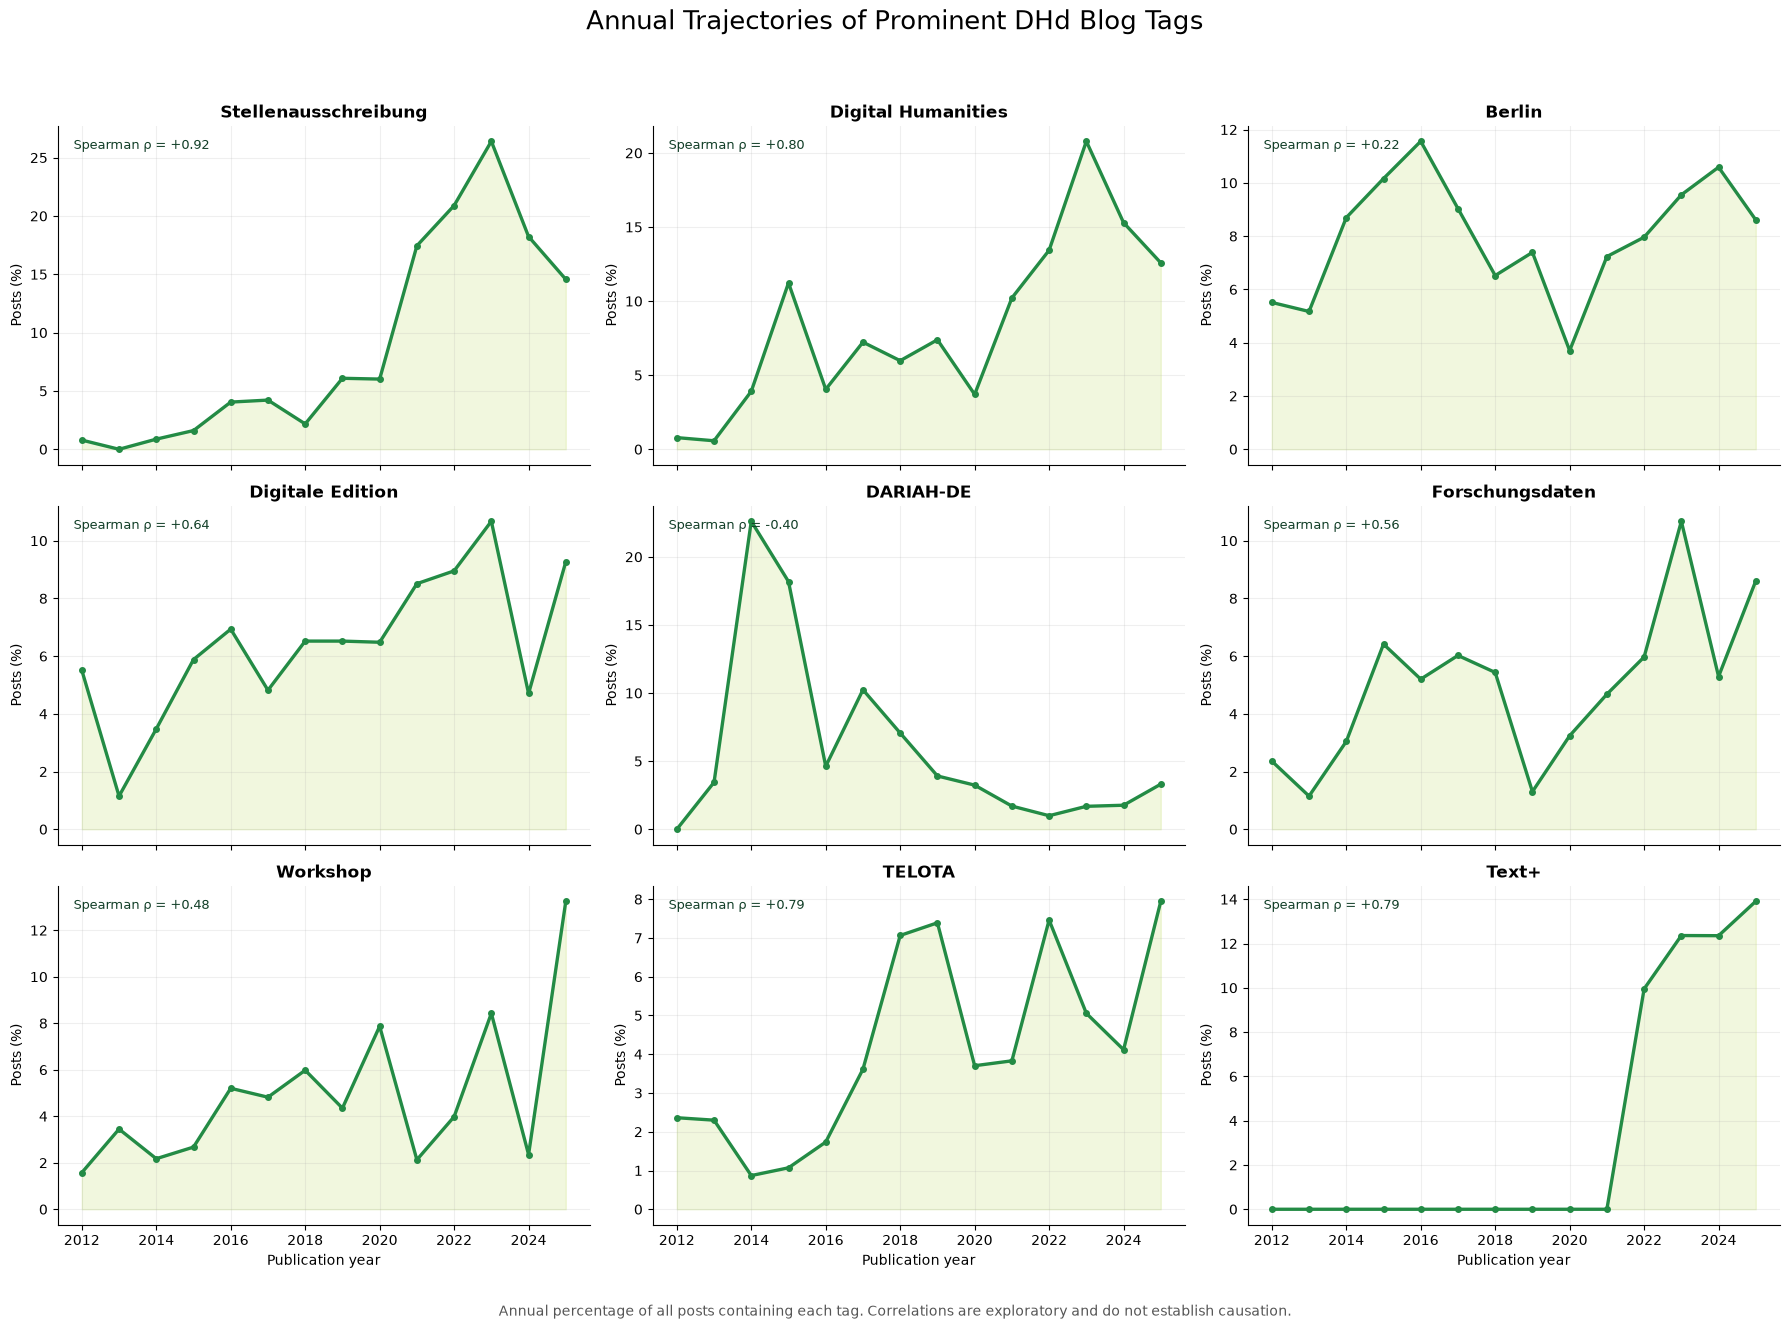

,Tag,2012–2025 posts,2012 share (%),2025 share (%),Peak year,Peak share (%),Spearman rho,p-value (exploratory)
4,DARIAH-DE,163,0.000,3.311,2014,22.609,-0.398,0.159
2,Berlin,208,5.512,8.609,2016,11.561,0.218,0.455
6,Workshop,125,1.575,13.245,2025,13.245,0.477,0.085
5,Forschungsdaten,127,2.362,8.609,2023,10.674,0.556,0.039
3,Digitale Edition,168,5.512,9.272,2023,10.674,0.638,0.014
7,TELOTA,110,2.362,7.947,2025,7.947,0.789,0.001
8,Text+,84,0.000,13.907,2025,13.907,0.793,0.001
1,Digital Humanities,220,0.787,12.583,2023,20.787,0.798,0.001
0,Stellenausschreibung,234,0.787,14.570,2023,26.404,0.921,0.000


In [44]:
# ============================================================
# 9.3 TAG TRAJECTORIES AND TREND ANALYSIS
# ============================================================

# 1. Use the top tags already selected in Section 9.1
years93 = list(range(2012, 2026))
tags93 = top_trend_tags[:9]

totals93 = (
    analysis_df[analysis_df["year"].between(2012, 2025)]
    .groupby("year")["post_id"]
    .nunique()
    .reindex(years93)
)

counts93 = annual_tag_counts.reindex(
    index=tags93, columns=years93, fill_value=0
)
shares93 = counts93.div(totals93, axis=1) * 100

# 2. Nine small-multiple charts
fig, axes = plt.subplots(
    3, 3, figsize=(18, 13),
    sharex=True, sharey=False
)

rows93 = []

for ax, tag in zip(axes.flat, tags93):
    y = shares93.loc[tag].to_numpy(dtype=float)
    x = np.array(years93)

    rho, pvalue = spearmanr(x, y)

    ax.plot(
        x, y, color="#238B45",
        linewidth=2.4, marker="o", markersize=4
    )
    ax.fill_between(x, y, color="#A4CF22", alpha=0.15)

    ax.set_title(tag, fontsize=12, fontweight="bold")
    ax.set_ylabel("Posts (%)")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

    ax.text(
        0.03, 0.96,
        f"Spearman ρ = {rho:+.2f}",
        transform=ax.transAxes,
        va="top", fontsize=9, color="#123F28"
    )

    rows93.append({
        "Tag": tag,
        "2012–2025 posts": int(counts93.loc[tag].sum()),
        "2012 share (%)": y[0],
        "2025 share (%)": y[-1],
        "Peak year": int(x[np.argmax(y)]),
        "Peak share (%)": float(np.max(y)),
        "Spearman rho": rho,
        "p-value (exploratory)": pvalue
    })

for ax in axes[-1]:
    ax.set_xlabel("Publication year")

fig.suptitle(
    "Annual Trajectories of Prominent DHd Blog Tags",
    fontsize=19, y=1.01
)

fig.text(
    0.5, 0.005,
    "Annual percentage of all posts containing each tag. "
    "Correlations are exploratory and do not establish causation.",
    ha="center", fontsize=10, color="#555555"
)

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.savefig(
    FIGURE_DIR / "9_3_tag_trajectories.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

display(
    pd.DataFrame(rows93)
    .sort_values("Spearman rho")
    .round(3)
)


## 9.4. Tag Trends by Publication Type

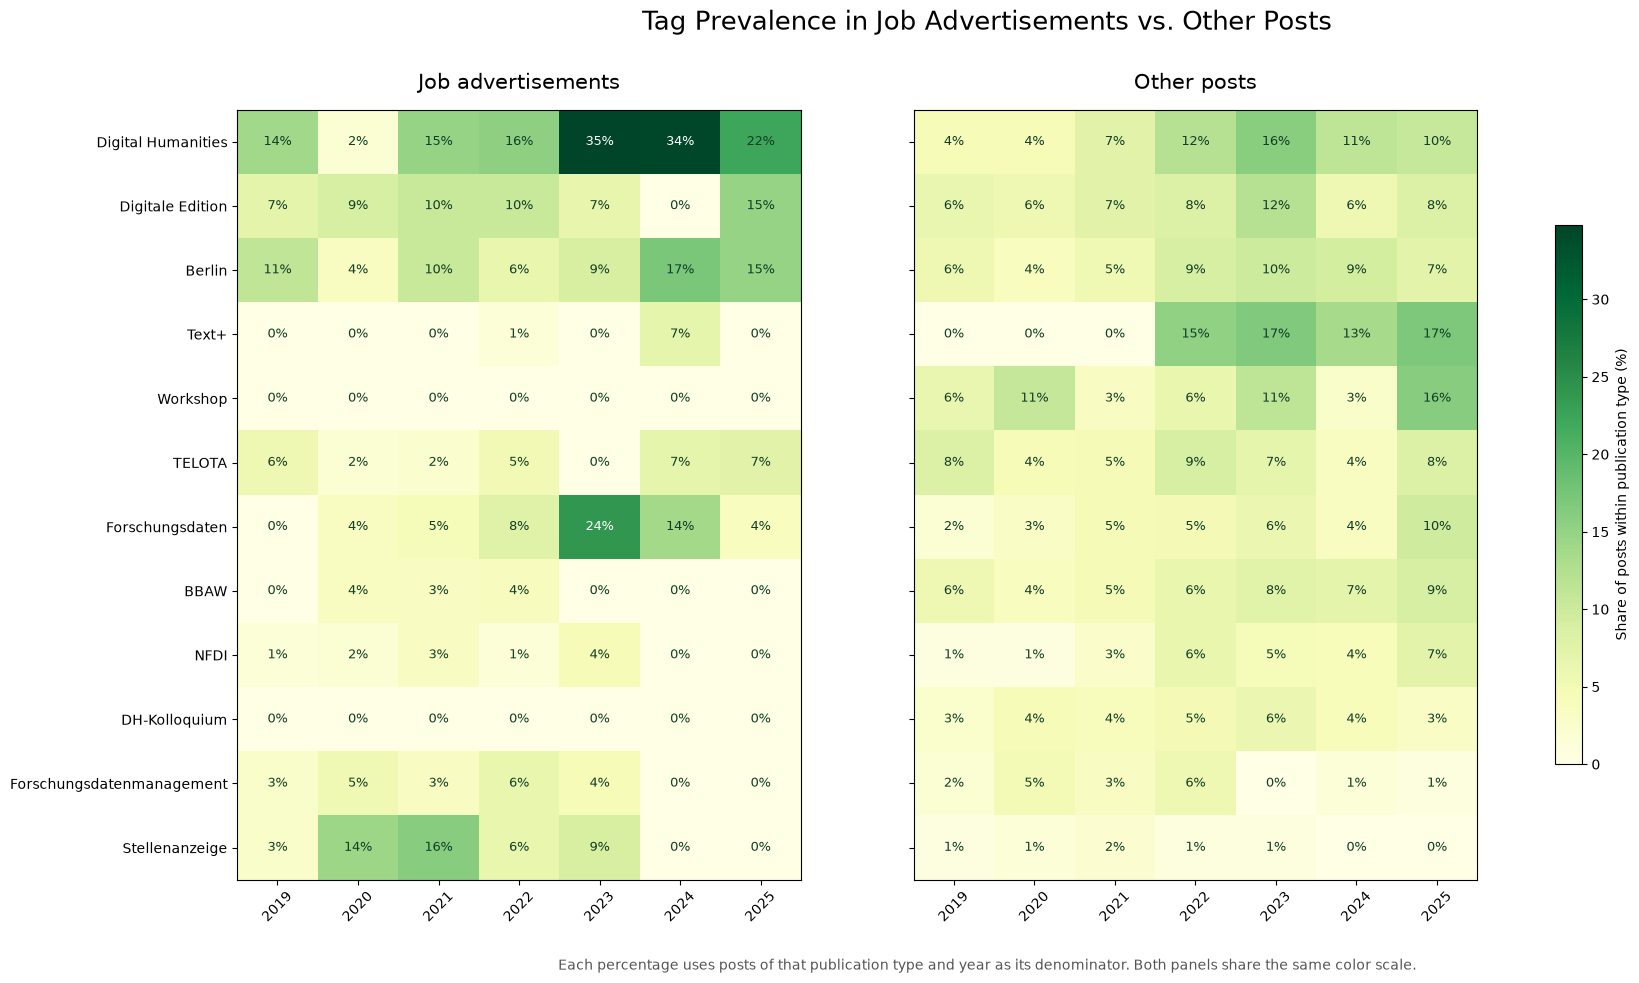

Annual post counts by publication type:


type,Job advertisements,Other posts
year,,
2019,72,158
2020,56,160
2021,87,148
2022,77,124
2023,46,132
2024,29,141
2025,27,124



Tag prevalence in other posts (%):


,2019,2020,2021,2022,2023,2024,2025
Digital Humanities,4.4,4.4,7.4,12.1,15.9,11.3,10.5
Digitale Edition,6.3,5.6,7.4,8.1,12.1,5.7,8.1
Berlin,5.7,3.8,5.4,8.9,9.8,9.2,7.3
Text+,0.0,0.0,0.0,15.3,16.7,13.5,16.9
Workshop,6.3,10.6,3.4,6.5,11.4,2.8,16.1
TELOTA,8.2,4.4,4.7,8.9,6.8,3.5,8.1
Forschungsdaten,1.9,3.1,4.7,4.8,6.1,3.5,9.7
BBAW,5.7,3.8,4.7,6.5,7.6,7.1,8.9
NFDI,0.6,0.6,2.7,6.5,4.5,4.3,7.3
DH-Kolloquium,2.5,4.4,4.1,4.8,6.1,4.3,3.2


In [45]:
# ============================================================
# 9.4 TAG TRENDS BY PUBLICATION TYPE
# ============================================================

# 1. Prepare posts and classify job advertisements
s94 = analysis_df[
    ["post_id", "year", "tags", "categories"]
].copy()

s94["year"] = pd.to_numeric(s94["year"], errors="coerce")
s94 = s94.dropna(subset=["year", "post_id"])
s94["year"] = s94["year"].astype(int)
s94 = s94[s94["year"].between(2019, 2025)]
s94 = s94.drop_duplicates("post_id")

s94["is_job_ad"] = (
    s94["categories"].fillna("").astype(str)
    .str.split(r"\s*\|\s*")
    .apply(lambda values: any(
        value.strip().casefold() == "stellenanzeigen"
        for value in values
    ))
)

s94["type"] = np.where(
    s94["is_job_ad"], "Job advertisements", "Other posts"
)

t94 = s94.assign(
    tag=s94["tags"].fillna("").astype(str).str.split(r"\s*\|\s*")
).explode("tag")

t94["tag"] = t94["tag"].fillna("").str.strip()
t94 = t94[t94["tag"].ne("")].drop_duplicates(["post_id", "tag"])

# Use a common set of tags in both heatmaps.
# Exclude the job-related tag itself to emphasize other topics.
selected94 = (
    t94[t94["tag"].str.casefold() != "stellenausschreibung"]
    ["tag"].value_counts().head(12).index.tolist()
)

years94 = list(range(2019, 2026))
types94 = ["Job advertisements", "Other posts"]

totals94 = (
    s94.groupby(["type", "year"])["post_id"]
    .nunique()
)

counts94 = (
    t94[t94["tag"].isin(selected94)]
    .groupby(["type", "tag", "year"])["post_id"]
    .nunique()
)

# 2. Plot comparable heatmaps
fig, axes = plt.subplots(
    1, 2, figsize=(20, 10),
    sharey=True
)

matrices94 = []

for publication_type in types94:
    matrix = pd.DataFrame(
        0.0, index=selected94, columns=years94
    )
    for year in years94:
        denominator = totals94.get((publication_type, year), 0)
        for tag in selected94:
            count = counts94.get(
                (publication_type, tag, year), 0
            )
            matrix.loc[tag, year] = (
                100 * count / denominator
                if denominator else np.nan
            )
    matrices94.append(matrix)

common_max94 = max(
    float(np.nanmax(m.values)) for m in matrices94
)

for ax, publication_type, matrix in zip(
    axes, types94, matrices94
):
    im = ax.imshow(
        matrix.values,
        cmap="YlGn", aspect="auto",
        vmin=0, vmax=common_max94
    )

    ax.set_title(publication_type, fontsize=15, pad=15)
    ax.set_xticks(range(len(years94)))
    ax.set_xticklabels(years94, rotation=45)
    ax.set_yticks(range(len(selected94)))
    ax.set_yticklabels(selected94)

    for i in range(len(selected94)):
        for j in range(len(years94)):
            value = matrix.iat[i, j]
            if pd.notna(value):
                ax.text(
                    j, i, f"{value:.0f}%",
                    ha="center", va="center",
                    fontsize=9,
                    color="white" if value > common_max94 * 0.65
                    else "#123F28"
                )

fig.colorbar(
    im, ax=axes, shrink=0.7,
    label="Share of posts within publication type (%)"
)

fig.suptitle(
    "Tag Prevalence in Job Advertisements vs. Other Posts",
    fontsize=19, y=0.98
)

fig.text(
    0.5, 0.02,
    "Each percentage uses posts of that publication type and year "
    "as its denominator. Both panels share the same color scale.",
    ha="center", fontsize=10, color="#555555"
)

plt.savefig(
    FIGURE_DIR / "9_4_tags_by_publication_type.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Annual post counts by publication type:")
display(
    s94.groupby(["year", "type"])["post_id"]
    .nunique().unstack(fill_value=0)
)

print("\nTag prevalence in other posts (%):")
display(matrices94[1].round(1))


## 9.5. Evolution of Tag Co-occurrence

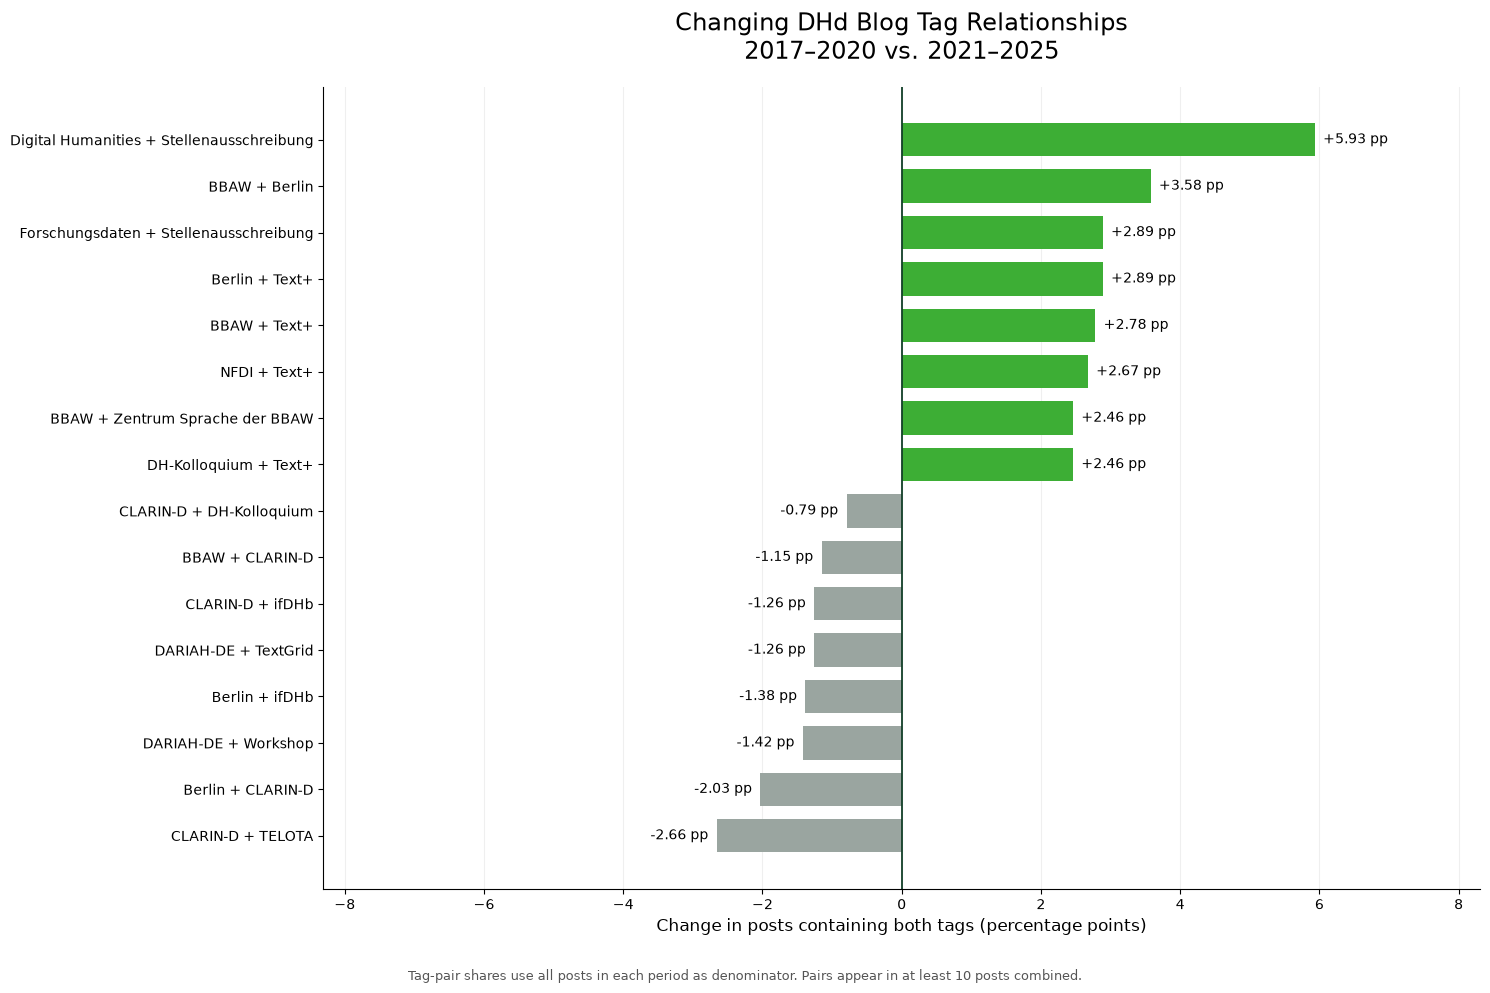

Posts per comparison period:


,Total posts
2017–2020,796
2021–2025,935



Largest increases in tag-pair prevalence:


,Tag pair,Earlier count,Recent count,Earlier %,Recent %,Change (pp)
5859,Digital Humanities + Stellenausschreibung,3,59,0.38,6.31,5.93
9061,BBAW + Berlin,9,44,1.13,4.71,3.58
1529,Forschungsdaten + Stellenausschreibung,0,27,0.00,2.89,2.89
2219,Berlin + Text+,0,27,0.00,2.89,2.89
637,BBAW + Text+,0,26,0.00,2.78,2.78
6006,NFDI + Text+,0,25,0.00,2.67,2.67
2103,BBAW + Zentrum Sprache der BBAW,0,23,0.00,2.46,2.46
3313,DH-Kolloquium + Text+,0,23,0.00,2.46,2.46



Largest decreases in tag-pair prevalence:


,Tag pair,Earlier count,Recent count,Earlier %,Recent %,Change (pp)
1394,CLARIN-D + TELOTA,22,1,2.76,0.11,-2.66
8549,Berlin + CLARIN-D,17,1,2.14,0.11,-2.03
5376,DARIAH-DE + Workshop,13,2,1.63,0.21,-1.42
7503,Berlin + ifDHb,11,0,1.38,0.00,-1.38
1952,CLARIN-D + ifDHb,10,0,1.26,0.00,-1.26
8353,DARIAH-DE + TextGrid,10,0,1.26,0.00,-1.26
6927,BBAW + CLARIN-D,10,1,1.26,0.11,-1.15
4964,CLARIN-D + DH-Kolloquium,8,2,1.01,0.21,-0.79


In [ ]:
# ============================================================
# 9.5 CHANGES IN TAG CO-OCCURRENCE
# ============================================================
# Purpose:
# - Compare tag-pair co-occurrence between 2017–2020
#   and 2021–2025.
# - Identify pairs gaining or losing prominence.
# - Rank changes using percentage points.
# - Avoid duplicated pairs from symmetric heatmaps.
# ============================================================

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

s95 = analysis_df[["post_id", "year", "tags"]].copy()

s95["year"] = pd.to_numeric(s95["year"], errors="coerce")
s95 = s95.dropna(subset=["post_id", "year"])
s95["year"] = s95["year"].astype(int)

s95 = (
    s95[s95["year"].between(2017, 2025)]
    .drop_duplicates("post_id")
    .copy()
)

s95["period"] = np.where(
    s95["year"] <= 2020, "2017–2020", "2021–2025"
)

s95["tag_set"] = s95["tags"].fillna("").astype(str).apply(
    lambda value: set(
        tag.strip()
        for tag in value.split("|")
        if tag.strip()
    )
)

periods95 = ["2017–2020", "2021–2025"]

# ------------------------------------------------------------
# 2. CALCULATE ALL TAG PAIRS
# ------------------------------------------------------------

pair_counts95 = {}
period_totals95 = {}

for period in periods95:
    subset = s95[s95["period"] == period]

    period_totals95[period] = len(subset)
    pair_counter = Counter()

    for tags in subset["tag_set"]:
        pair_counter.update(combinations(sorted(tags), 2))

    pair_counts95[period] = pair_counter

all_pairs95 = (
    set(pair_counts95[periods95[0]])
    | set(pair_counts95[periods95[1]])
)

rows95 = []

for pair in all_pairs95:
    earlier_count = pair_counts95[periods95[0]][pair]
    recent_count = pair_counts95[periods95[1]][pair]

    earlier_share = (
        100 * earlier_count / period_totals95[periods95[0]]
    )
    recent_share = (
        100 * recent_count / period_totals95[periods95[1]]
    )

    rows95.append({
        "Tag pair": " + ".join(pair),
        "Earlier count": earlier_count,
        "Recent count": recent_count,
        "Earlier %": earlier_share,
        "Recent %": recent_share,
        "Change (pp)": recent_share - earlier_share,
        "Combined count": earlier_count + recent_count
    })

pair_results95 = pd.DataFrame(rows95)

# Exclude rare pairs to avoid misleading large changes.
MIN_PAIR_POSTS95 = 10

eligible95 = pair_results95[
    pair_results95["Combined count"] >= MIN_PAIR_POSTS95
].copy()

# Select the largest positive and negative changes.
top_increases95 = eligible95.nlargest(
    8, "Change (pp)"
)

top_decreases95 = eligible95.nsmallest(
    8, "Change (pp)"
)

selected95 = (
    pd.concat([top_increases95, top_decreases95])
    .drop_duplicates(subset=["Tag pair"])
    .sort_values("Change (pp)")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. CREATE RANKED CHANGE CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 10))

changes95 = selected95["Change (pp)"].to_numpy()

colors95 = [
    "#3DAE35" if change >= 0 else "#9AA5A0"
    for change in changes95
]

ax.barh(
    selected95["Tag pair"],
    changes95,
    color=colors95,
    height=0.72
)

ax.axvline(
    0, color="#123F28", linewidth=1.3
)

for i, change in enumerate(changes95):
    ax.annotate(
        f"{change:+.2f} pp",
        (change, i),
        xytext=(6 if change >= 0 else -6, 0),
        textcoords="offset points",
        ha="left" if change >= 0 else "right",
        va="center",
        fontsize=10
    )

max_change95 = max(
    float(np.max(np.abs(changes95))), 0.5
)

ax.set_xlim(
    -max_change95 * 1.4,
    max_change95 * 1.4
)

ax.set_title(
    "Changing DHd Blog Tag Relationships\n"
    "2017–2020 vs. 2021–2025",
    fontsize=17,
    pad=20
)

ax.set_xlabel(
    "Change in posts containing both tags (percentage points)",
    fontsize=12
)

ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.015,
    "Tag-pair shares use all posts in each period as denominator. "
    "Pairs appear in at least 10 posts combined.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

# ------------------------------------------------------------
# 4. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "9_5_tag_cooccurrence_changes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. DISPLAY NUMERICAL RESULTS
# ------------------------------------------------------------

print("Posts per comparison period:")
display(
    pd.DataFrame.from_dict(
        period_totals95,
        orient="index",
        columns=["Total posts"]
    )
)

print("\nLargest increases in tag-pair prevalence:")
display(
    top_increases95.drop(columns="Combined count").round(2)
)

print("\nLargest decreases in tag-pair prevalence:")
display(
    top_decreases95.drop(columns="Combined count").round(2)
)


## 9.6. Infrastructure transition

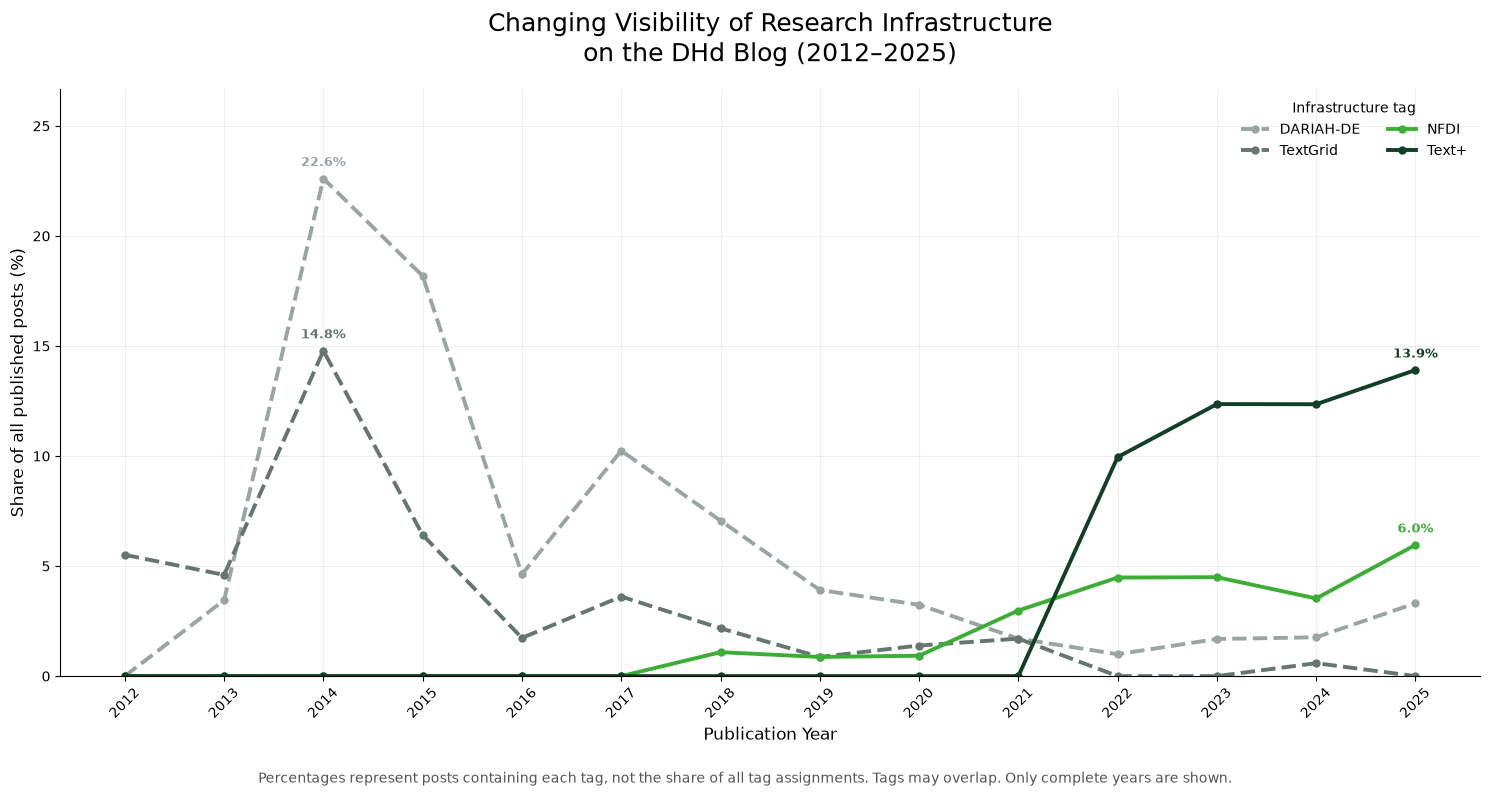

Research infrastructure tag summary:


,Tag,First observed year,Peak year,Peak share (%),Peak post count,2025 post count,2025 share (%),Total posts (2012–2025)
0,DARIAH-DE,2013,2014,22.61,52,5,3.31,163
1,TextGrid,2012,2014,14.78,34,0,0.00,84
2,NFDI,2018,2025,5.96,9,9,5.96,45
3,Text+,2022,2025,13.91,21,21,13.91,84



Early vs. recent period comparison:


,Tag,2012–2016 posts,2012–2016 %,2021–2025 posts,2021–2025 %,Change (pp)
0,DARIAH-DE,100,11.22,17,1.82,-9.41
1,TextGrid,64,7.18,5,0.53,-6.65
2,NFDI,0,0.00,39,4.17,4.17
3,Text+,0,0.00,84,8.98,8.98



Key findings:
DARIAH-DE: decreased by 9.41 percentage points between the two periods.
TextGrid: decreased by 6.65 percentage points between the two periods.
NFDI: increased by 4.17 percentage points between the two periods.
Text+: increased by 8.98 percentage points between the two periods.


In [65]:
# ============================================================
# 9.6 EVOLUTION OF RESEARCH INFRASTRUCTURE TAGS
# ============================================================
# Purpose:
# - Examine the changing visibility of infrastructure tags.
# - Compare DARIAH-DE, TextGrid, NFDI, and Text+.
# - Identify first appearances, peaks, and recent activity.
# - Distinguish tag prevalence from absolute post counts.
# ============================================================

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

infrastructure_tags96 = [
    "DARIAH-DE",
    "TextGrid",
    "NFDI",
    "Text+"
]

years96 = list(range(2012, 2026))

s96 = analysis_df[
    ["post_id", "year", "tags"]
].copy()

s96["year"] = pd.to_numeric(
    s96["year"], errors="coerce"
)

s96 = s96.dropna(
    subset=["post_id", "year"]
)

s96["year"] = s96["year"].astype(int)

s96 = (
    s96[s96["year"].between(2012, 2025)]
    .drop_duplicates("post_id")
    .copy()
)

s96["tag_set"] = s96["tags"].fillna("").astype(str).apply(
    lambda value: set(
        tag.strip()
        for tag in value.split("|")
        if tag.strip()
    )
)

# ------------------------------------------------------------
# 2. CALCULATE COUNTS AND ANNUAL PERCENTAGES
# ------------------------------------------------------------

annual_totals96 = (
    s96.groupby("year")["post_id"]
    .nunique()
    .reindex(years96, fill_value=0)
)

counts96 = pd.DataFrame(
    0,
    index=infrastructure_tags96,
    columns=years96
)

for year in years96:
    year_posts = s96[s96["year"] == year]

    for tag in infrastructure_tags96:
        counts96.loc[tag, year] = int(
            year_posts["tag_set"].apply(
                lambda tags: tag in tags
            ).sum()
        )

shares96 = (
    counts96.div(
        annual_totals96.replace(0, np.nan),
        axis=1
    ) * 100
).fillna(0)

# ------------------------------------------------------------
# 3. CREATE COMPARATIVE LINE CHART
# ------------------------------------------------------------

colors96 = {
    "DARIAH-DE": "#9AA5A0",
    "TextGrid": "#65766E",
    "NFDI": "#3DAE35",
    "Text+": "#123F28"
}

styles96 = {
    "DARIAH-DE": "--",
    "TextGrid": "--",
    "NFDI": "-",
    "Text+": "-"
}

fig, ax = plt.subplots(figsize=(15, 8))

for tag in infrastructure_tags96:
    values = shares96.loc[tag].to_numpy(dtype=float)

    ax.plot(
        years96,
        values,
        label=tag,
        color=colors96[tag],
        linestyle=styles96[tag],
        linewidth=2.8,
        marker="o",
        markersize=5
    )

    peak_index = int(np.argmax(values))
    peak_year = years96[peak_index]
    peak_share = values[peak_index]

    if peak_share > 0:
        ax.annotate(
            f"{peak_share:.1f}%",
            (peak_year, peak_share),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            color=colors96[tag],
            fontweight="bold"
        )

ax.set_title(
    "Changing Visibility of Research Infrastructure\n"
    "on the DHd Blog (2012–2025)",
    fontsize=18,
    pad=20
)

ax.set_xlabel("Publication Year", fontsize=12)

ax.set_ylabel(
    "Share of all published posts (%)",
    fontsize=12
)

ax.set_xticks(years96)
ax.tick_params(axis="x", rotation=45)

ax.set_ylim(
    0,
    max(float(shares96.max().max()) * 1.18, 5)
)

ax.legend(
    title="Infrastructure tag",
    frameon=False,
    ncol=2,
    loc="upper right"
)

ax.grid(alpha=0.2)
ax.set_axisbelow(True)

ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.015,
    "Percentages represent posts containing each tag, "
    "not the share of all tag assignments. "
    "Tags may overlap. Only complete years are shown.",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

# ------------------------------------------------------------
# 4. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "9_6_research_infrastructure_transition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. SUMMARIZE TAG HISTORIES
# ------------------------------------------------------------

summary96 = []

for tag in infrastructure_tags96:
    tag_counts = counts96.loc[tag]
    tag_shares = shares96.loc[tag]

    active_years = tag_counts[
        tag_counts > 0
    ].index.tolist()

    first_year = (
        active_years[0] if active_years else None
    )

    peak_year = int(tag_shares.idxmax())

    summary96.append({
        "Tag": tag,
        "First observed year": first_year,
        "Peak year": peak_year,
        "Peak share (%)": tag_shares.loc[peak_year],
        "Peak post count": tag_counts.loc[peak_year],
        "2025 post count": tag_counts.loc[2025],
        "2025 share (%)": tag_shares.loc[2025],
        "Total posts (2012–2025)": tag_counts.sum()
    })

summary96 = pd.DataFrame(summary96)

print("Research infrastructure tag summary:")
display(summary96.round(2))

# ------------------------------------------------------------
# 6. COMPARE EARLY AND RECENT PERIODS
# ------------------------------------------------------------

periods96 = {
    "2012–2016": (2012, 2016),
    "2021–2025": (2021, 2025)
}

period_rows96 = []

for tag in infrastructure_tags96:
    row = {"Tag": tag}

    for period_name, (start, end) in periods96.items():
        years = list(range(start, end + 1))

        tagged_posts = int(
            counts96.loc[tag, years].sum()
        )

        all_posts = int(
            annual_totals96.loc[years].sum()
        )

        row[f"{period_name} posts"] = tagged_posts
        row[f"{period_name} %"] = (
            100 * tagged_posts / all_posts
            if all_posts else 0
        )

    row["Change (pp)"] = (
        row["2021–2025 %"] - row["2012–2016 %"]
    )

    period_rows96.append(row)

period_results96 = pd.DataFrame(period_rows96)

print("\nEarly vs. recent period comparison:")
display(period_results96.round(2))

# ------------------------------------------------------------
# 7. PRINT KEY NUMERICAL FINDINGS
# ------------------------------------------------------------

print("\nKey findings:")

for _, row in period_results96.iterrows():
    direction = (
        "increased"
        if row["Change (pp)"] > 0
        else "decreased"
        if row["Change (pp)"] < 0
        else "remained unchanged"
    )

    print(
        f"{row['Tag']}: {direction} by "
        f"{abs(row['Change (pp)']):.2f} percentage points "
        f"between the two periods."
    )


## 10. Topic Trends

,topic,posts,percentage_of_all_posts
0,Research Data Management,824,29.650954
1,Cultural Heritage and Museums,784,28.211587
2,FAIR Data and Open Science,463,16.660669
3,Metadata and Data Modelling,454,16.336812
4,TEI and Text Encoding,433,15.581144
5,Digital Editions,363,13.062253
6,Text Corpora,288,10.363440
7,Linked Data and Knowledge Graphs,283,10.183519
8,NLP and Computational Linguistics,254,9.139978
9,Data Visualization,249,8.960058


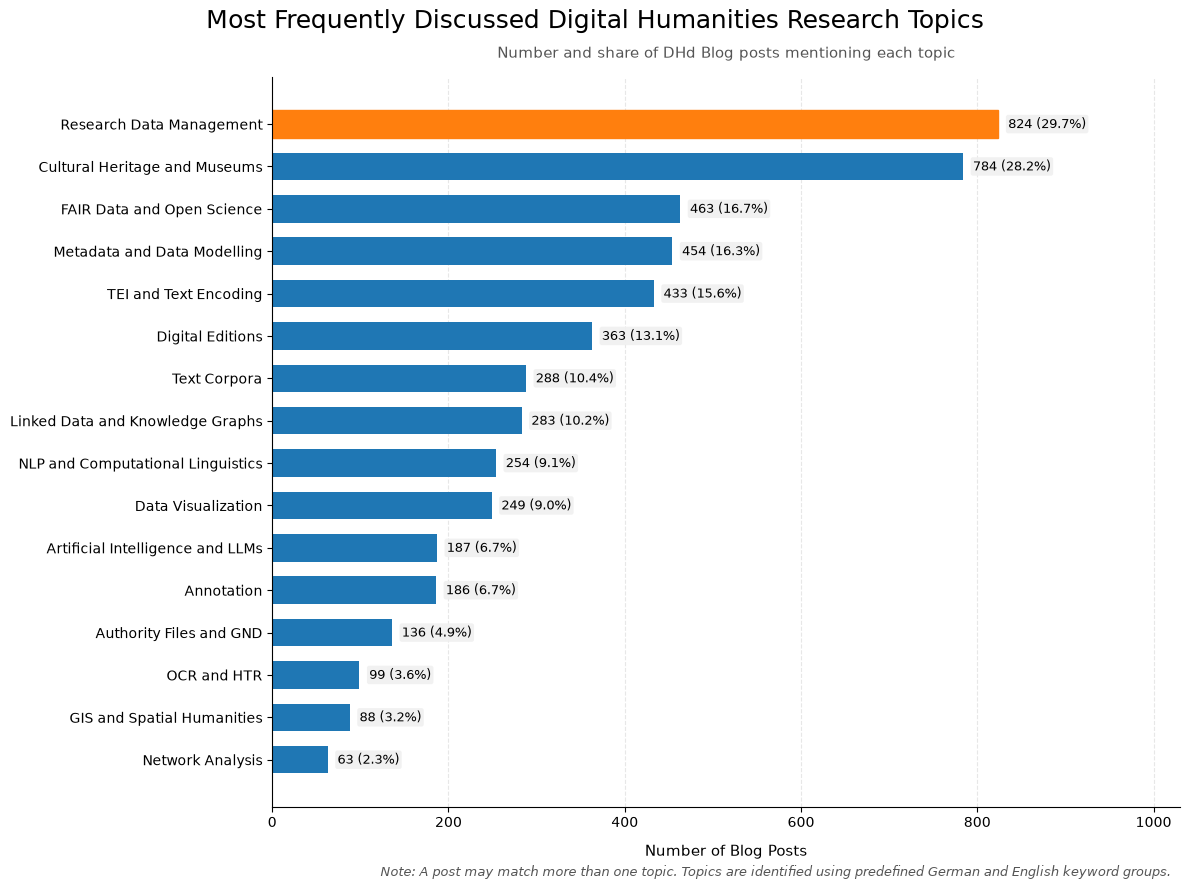

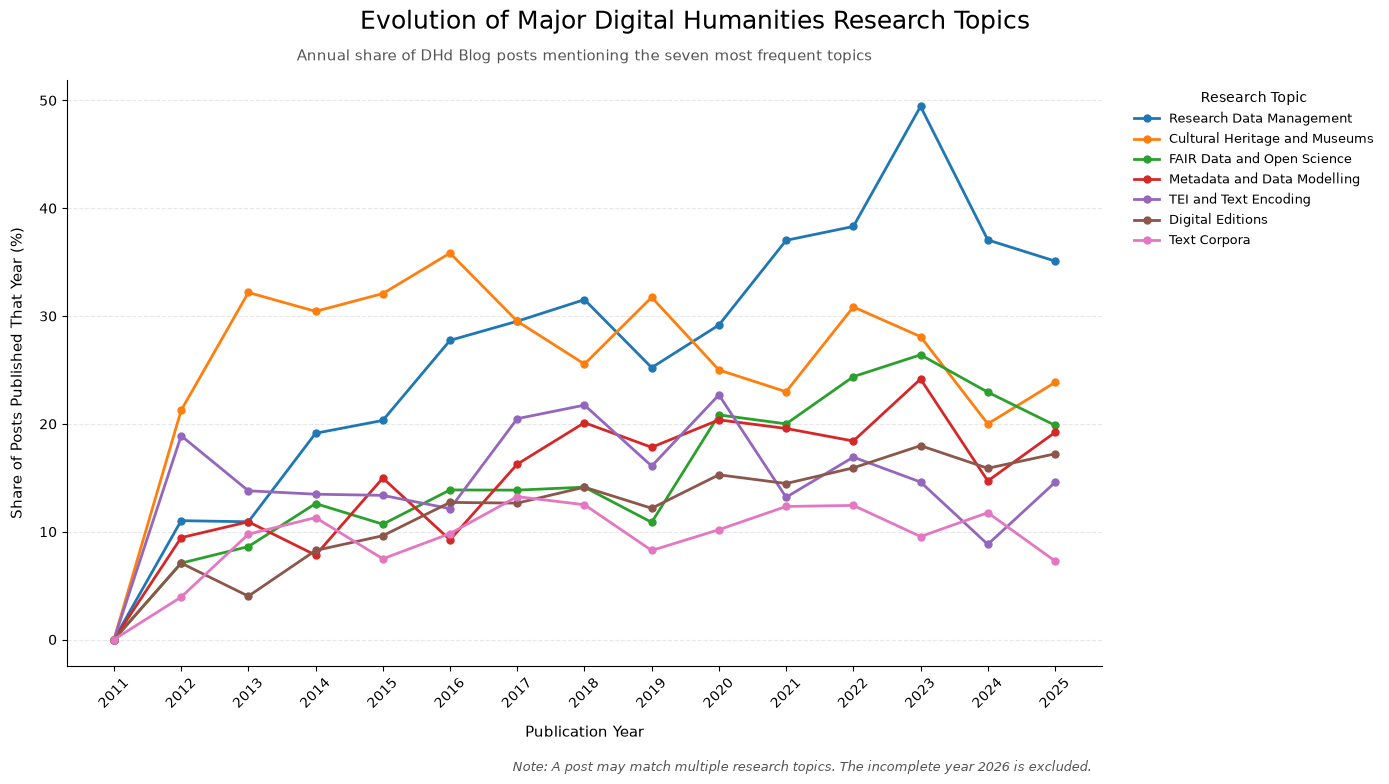

Topic counts by year:


topic,Annotation,Artificial Intelligence and LLMs,Authority Files and GND,Cultural Heritage and Museums,Data Visualization,Digital Editions,FAIR Data and Open Science,GIS and Spatial Humanities,Linked Data and Knowledge Graphs,Metadata and Data Modelling,NLP and Computational Linguistics,Network Analysis,OCR and HTR,Research Data Management,TEI and Text Encoding,Text Corpora
year,,,,,,,,,,,,,,,,
2011,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2012,7,1,3,27,7,9,9,3,10,12,4,1,1,14,24,5
2013,8,0,2,56,12,7,15,6,9,19,9,6,4,19,24,17
2014,12,4,12,70,24,19,29,6,20,18,10,3,2,44,31,26
2015,12,7,9,60,22,18,20,7,7,28,17,5,7,38,25,14
2016,9,4,7,62,23,22,24,3,13,16,15,3,3,48,21,17
2017,12,4,6,49,15,21,23,5,12,27,19,7,6,49,34,22
2018,13,9,11,47,17,26,26,21,28,37,18,5,5,58,40,23
2019,15,16,6,73,24,28,25,3,24,41,20,5,7,58,37,19


Topic shares by year (%):


topic,Annotation,Artificial Intelligence and LLMs,Authority Files and GND,Cultural Heritage and Museums,Data Visualization,Digital Editions,FAIR Data and Open Science,GIS and Spatial Humanities,Linked Data and Knowledge Graphs,Metadata and Data Modelling,NLP and Computational Linguistics,Network Analysis,OCR and HTR,Research Data Management,TEI and Text Encoding,Text Corpora
year,,,,,,,,,,,,,,,,
2011,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2012,5.5,0.8,2.4,21.3,5.5,7.1,7.1,2.4,7.9,9.4,3.1,0.8,0.8,11.0,18.9,3.9
2013,4.6,0.0,1.1,32.2,6.9,4.0,8.6,3.4,5.2,10.9,5.2,3.4,2.3,10.9,13.8,9.8
2014,5.2,1.7,5.2,30.4,10.4,8.3,12.6,2.6,8.7,7.8,4.3,1.3,0.9,19.1,13.5,11.3
2015,6.4,3.7,4.8,32.1,11.8,9.6,10.7,3.7,3.7,15.0,9.1,2.7,3.7,20.3,13.4,7.5
2016,5.2,2.3,4.0,35.8,13.3,12.7,13.9,1.7,7.5,9.2,8.7,1.7,1.7,27.7,12.1,9.8
2017,7.2,2.4,3.6,29.5,9.0,12.7,13.9,3.0,7.2,16.3,11.4,4.2,3.6,29.5,20.5,13.3
2018,7.1,4.9,6.0,25.5,9.2,14.1,14.1,11.4,15.2,20.1,9.8,2.7,2.7,31.5,21.7,12.5
2019,6.5,7.0,2.6,31.7,10.4,12.2,10.9,1.3,10.4,17.8,8.7,2.2,3.0,25.2,16.1,8.3


In [47]:
# ============================================================
# 1. DEFINE DIGITAL HUMANITIES RESEARCH TOPICS
# ============================================================

topic_keywords = {
    "Digital Editions": ["digitale edition", "digitale editionen", "digital edition", "digital editions", "scholarly edition", "scholarly editions", "editorial theory", "editionswissenschaft", "kritische edition"],
    "TEI and Text Encoding": ["tei", "text encoding initiative", "xml", "tei publisher", "exist-db", "text encoding", "markup language"],
    "Annotation": ["annotation", "annotations", "annotieren", "annotationswerkzeug", "annotationswerkzeuge", "annotation tool", "annotation tools", "webanno", "inception", "catma", "recogito"],
    "Text Corpora": ["text corpus", "text corpora", "corpus", "corpora", "korpus", "korpora", "textkorpus", "textkorpora", "corpus linguistics", "korpuslinguistik"],
    "OCR and HTR": ["ocr", "htr", "optical character recognition", "handwritten text recognition", "texterkennung", "handschriftenerkennung", "transkribus", "tesseract", "kraken", "abbyy"],
    "Research Data Management": ["research data", "research data management", "forschungsdaten", "forschungsdatenmanagement", "datenmanagement", "rdm", "data management plan", "datenmanagementplan", "repository", "repositorium", "datenrepositorium", "nfdi"],
    "FAIR Data and Open Science": ["fair data", "fair principles", "fair-prinzipien", "open science", "open data", "open access", "reproducibility", "reproduzierbarkeit"],
    "Artificial Intelligence and LLMs": ["artificial intelligence", "künstliche intelligenz", "machine learning", "maschinelles lernen", "deep learning", "neural network", "neural networks", "neuronales netz", "neuronale netze", "large language model", "large language models", "llm", "llms", "chatgpt", "generative ai", "generative künstliche intelligenz", "transformer", "transformers", "bert", "embeddings"],
    "NLP and Computational Linguistics": ["natural language processing", "nlp", "sprachverarbeitung", "computerlinguistik", "computational linguistics", "named entity recognition", "ner", "part-of-speech", "pos tagging", "sentiment analysis", "language model", "language models", "sprachmodell", "sprachmodelle", "lemmatization", "lemmatisierung", "tokenization", "tokenisierung"],
    "Linked Data and Knowledge Graphs": ["linked data", "linked open data", "lod", "rdf", "sparql", "semantic web", "knowledge graph", "knowledge graphs", "wissensgraph", "wissensgraphen", "wikidata"],
    "Authority Files and GND": ["authority file", "authority files", "normdatei", "normdateien", "normdaten", "gnd", "gemeinsame normdatei", "authority data"],
    "Metadata and Data Modelling": ["metadata", "metadaten", "data modelling", "data modeling", "datenmodellierung", "data model", "datenmodell", "ontology", "ontologies", "ontologie", "ontologien", "schema", "standardization", "standardisierung"],
    "GIS and Spatial Humanities": ["gis", "geographic information system", "geoinformationssystem", "spatial humanities", "geodaten", "mapping", "kartierung", "historical gis", "qgis", "georeferencing", "georeferenzierung", "historical maps", "historische karten"],
    "Network Analysis": ["network analysis", "netzwerkanalyse", "social network analysis", "soziale netzwerkanalyse", "graph analysis", "graphentheorie", "gephi", "network visualization", "netzwerkvisualisierung"],
    "Data Visualization": ["data visualization", "data visualisation", "datenvisualisierung", "visualization", "visualisation", "visualisierung", "dashboard", "information visualization", "informationsvisualisierung"],
    "Cultural Heritage and Museums": ["cultural heritage", "kulturerbe", "museum", "museums", "archive", "archives", "archiv", "bibliothek", "bibliotheken", "library", "libraries", "digital cultural heritage"]
}

# ============================================================
# 2. PREPARE SEARCHABLE TEXT
# ============================================================

topic_df = analysis_df.copy()

topic_df["year"] = pd.to_numeric(
    topic_df["year"],
    errors="coerce"
)

for column in ["title", "categories", "tags", "text"]:
    if column not in topic_df.columns:
        topic_df[column] = ""

    topic_df[column] = (
        topic_df[column]
        .fillna("")
        .astype(str)
    )

topic_df["search_text"] = (
    topic_df["title"] + " " +
    topic_df["categories"] + " " +
    topic_df["tags"] + " " +
    topic_df["text"]
).str.lower()

# ============================================================
# 3. CREATE TOPIC FLAGS
# ============================================================

for topic, keywords in topic_keywords.items():

    pattern = "|".join(
        rf"(?<!\w){re.escape(keyword.lower())}(?!\w)"
        for keyword in keywords
    )

    topic_df[topic] = topic_df["search_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

# ============================================================
# 4. OVERALL TOPIC FREQUENCY
# ============================================================

topic_summary_rows = []

total_posts = len(topic_df)

for topic in topic_keywords:

    topic_posts = int(topic_df[topic].sum())

    topic_summary_rows.append({
        "topic": topic,
        "posts": topic_posts,
        "percentage_of_all_posts": (
            topic_posts / total_posts * 100
            if total_posts > 0
            else 0
        )
    })

topic_summary = (
    pd.DataFrame(topic_summary_rows)
    .sort_values(
        "posts",
        ascending=False
    )
    .reset_index(drop=True)
)

display(topic_summary)

# ============================================================
# 5. FIGURE 1 — MOST FREQUENTLY DISCUSSED TOPICS
# ============================================================

ranked_topics = (
    topic_summary
    .sort_values("posts")
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    ranked_topics["topic"],
    ranked_topics["posts"],
    height=0.65
)

# Highlight most frequent topic
bars[-1].set_color("tab:orange")

for bar, posts, percentage in zip(
    bars,
    ranked_topics["posts"],
    ranked_topics["percentage_of_all_posts"]
):
    ax.annotate(
        f"{int(posts)} ({percentage:.1f}%)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Frequently Discussed Digital Humanities Research Topics",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_title(
    "Number and share of DHd Blog posts mentioning each topic",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Number of Blog Posts",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.set_xlim(
    0,
    ranked_topics["posts"].max() * 1.25
)

ax.text(
    0.99,
    -0.08,
    (
        "Note: A post may match more than one topic. "
        "Topics are identified using predefined German and English keyword groups."
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig11_most_frequent_dh_research_topics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. TOPIC COUNTS BY YEAR
# ============================================================

valid_years = sorted(
    topic_df["year"]
    .dropna()
    .astype(int)
    .unique()
)

yearly_post_totals = (
    topic_df
    .dropna(subset=["year"])
    .groupby("year")
    .size()
    .rename("total_posts")
)

topic_year_rows = []

for topic in topic_keywords:

    yearly_topic_counts = (
        topic_df.loc[topic_df[topic]]
        .groupby("year")
        .size()
    )

    for year in valid_years:

        topic_posts = int(
            yearly_topic_counts.get(year, 0)
        )

        year_total = int(
            yearly_post_totals.get(year, 0)
        )

        topic_year_rows.append({
            "year": int(year),
            "topic": topic,
            "posts": topic_posts,
            "share_of_yearly_posts": (
                topic_posts / year_total * 100
                if year_total > 0
                else 0
            )
        })

topic_year_df = pd.DataFrame(topic_year_rows)

# Exclude incomplete 2026 from trend chart
trend_df = topic_year_df[
    topic_year_df["year"] < 2026
].copy()

# Use most frequent topics only for readability
TOP_N = 7

selected_topics = (
    topic_summary
    .head(TOP_N)["topic"]
    .tolist()
)

trend_df = trend_df[
    trend_df["topic"].isin(selected_topics)
]

# ============================================================
# 7. FIGURE 2 — TOPIC TRENDS OVER TIME
# ============================================================

fig, ax = plt.subplots(figsize=(14, 8))

for topic in selected_topics:

    topic_data = (
        trend_df[
            trend_df["topic"] == topic
        ]
        .sort_values("year")
    )

    ax.plot(
        topic_data["year"],
        topic_data["share_of_yearly_posts"],
        marker="o",
        markersize=5,
        linewidth=2,
        label=topic
    )

fig.suptitle(
    "Evolution of Major Digital Humanities Research Topics",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_title(
    "Annual share of DHd Blog posts mentioning the seven most frequent topics",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Publication Year",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Share of Posts Published That Year (%)",
    fontsize=11,
    labelpad=10
)

ax.set_xticks(
    sorted(trend_df["year"].unique())
)

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Research Topic",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

ax.text(
    0.99,
    -0.16,
    (
        "Note: A post may match multiple research topics. "
        "The incomplete year 2026 is excluded."
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig12_dh_research_topic_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. DISPLAY YEARLY COUNTS AND SHARES
# ============================================================

topic_count_table = (
    topic_year_df
    .pivot(
        index="year",
        columns="topic",
        values="posts"
    )
    .fillna(0)
    .astype(int)
)

topic_share_table = (
    topic_year_df
    .pivot(
        index="year",
        columns="topic",
        values="share_of_yearly_posts"
    )
    .fillna(0)
    .round(1)
)

print("Topic counts by year:")
display(topic_count_table)

print("Topic shares by year (%):")
display(topic_share_table)


## 11. Longest Most Commented Post

In [48]:
# ============================================================
# EXTREME POSTS — PUBLICATION-STYLE TABLE
# ============================================================

extremes = []

# Detect the correct comments column
comments_column = None

if "comments" in analysis_df.columns:
    comments_column = "comments"
elif "comment_count" in analysis_df.columns:
    comments_column = "comment_count"


# ------------------------------------------------------------
# Longest post
# ------------------------------------------------------------

if "word_count" in analysis_df.columns:

    longest = analysis_df.loc[
        analysis_df["word_count"].idxmax()
    ]

    extremes.append({
        "Record": "Longest post",
        "Title": longest["title"],
        "Date": longest["publication_date"],
        "Author": longest["author"],
        "Value": f"{int(longest['word_count']):,} words",
        "URL": longest.get("url", "")
    })


# ------------------------------------------------------------
# Shortest meaningful post
# Excludes zero-word or nearly empty posts
# ------------------------------------------------------------

if "word_count" in analysis_df.columns:

    meaningful_posts = analysis_df[
        analysis_df["word_count"] >= 20
    ]

    if not meaningful_posts.empty:

        shortest = meaningful_posts.loc[
            meaningful_posts["word_count"].idxmin()
        ]

        extremes.append({
            "Record": "Shortest post",
            "Title": shortest["title"],
            "Date": shortest["publication_date"],
            "Author": shortest["author"],
            "Value": f"{int(shortest['word_count']):,} words",
            "URL": shortest.get("url", "")
        })


# ------------------------------------------------------------
# Most commented post
# ------------------------------------------------------------

if comments_column is not None:

    most_comments = analysis_df.loc[
        analysis_df[comments_column].idxmax()
    ]

    extremes.append({
        "Record": "Most commented post",
        "Title": most_comments["title"],
        "Date": most_comments["publication_date"],
        "Author": most_comments["author"],
        "Value": (
            f"{int(most_comments[comments_column]):,} comments"
        ),
        "URL": most_comments.get("url", "")
    })


# ------------------------------------------------------------
# Most tagged post
# ------------------------------------------------------------

if "tags" in analysis_df.columns:

    tag_number = (
        analysis_df["tags"]
        .fillna("")
        .str.split(r"\s*\|\s*")
        .apply(
            lambda values:
            len({
                value.strip()
                for value in values
                if value.strip()
            })
        )
    )

    most_tags = analysis_df.loc[
        tag_number.idxmax()
    ]

    extremes.append({
        "Record": "Most tagged post",
        "Title": most_tags["title"],
        "Date": most_tags["publication_date"],
        "Author": most_tags["author"],
        "Value": f"{int(tag_number.max())} tags",
        "URL": most_tags.get("url", "")
    })


# ------------------------------------------------------------
# Most categorized post
# ------------------------------------------------------------

if "categories" in analysis_df.columns:

    category_number = (
        analysis_df["categories"]
        .fillna("")
        .str.split(r"\s*\|\s*")
        .apply(
            lambda values:
            len({
                value.strip()
                for value in values
                if value.strip()
            })
        )
    )

    most_categories = analysis_df.loc[
        category_number.idxmax()
    ]

    extremes.append({
        "Record": "Most categorized post",
        "Title": most_categories["title"],
        "Date": most_categories["publication_date"],
        "Author": most_categories["author"],
        "Value": f"{int(category_number.max())} categories",
        "URL": most_categories.get("url", "")
    })


# ============================================================
# PREPARE TABLE
# ============================================================

extremes_df = pd.DataFrame(extremes)

extremes_df["Date"] = pd.to_datetime(
    extremes_df["Date"],
    errors="coerce"
).dt.strftime("%d %b %Y")

# Keep titles readable
extremes_df["Title"] = extremes_df["Title"].fillna("")
extremes_df["Author"] = extremes_df["Author"].fillna("Unknown")


# ============================================================
# STYLE TABLE
# ============================================================

styled_extremes = (
    extremes_df[
        ["Record", "Title", "Date", "Author", "Value", "URL"]
    ]
    .style
    .hide(axis="index")
    .set_caption("DHd Blog Records and Extreme Values")
    .set_properties(
        subset=["Record"],
        **{
            "font-weight": "600",
            "white-space": "nowrap"
        }
    )
    .set_properties(
        subset=["Title"],
        **{
            "text-align": "left",
            "max-width": "420px",
            "white-space": "normal"
        }
    )
    .set_properties(
        subset=["Date", "Author", "Value"],
        **{
            "white-space": "nowrap"
        }
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "400"),
                ("text-align", "left"),
                ("padding-bottom", "14px"),
                ("color", "#222222")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#eeeeee"),
                ("color", "#222222"),
                ("font-weight", "600"),
                ("text-align", "left"),
                ("padding", "10px"),
                ("border-bottom", "1px solid #cccccc")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px"),
                ("border-bottom", "1px solid #e5e5e5"),
                ("vertical-align", "top")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [
                ("background-color", "#f8f8f8")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("font-family", "DejaVu Sans, Arial, sans-serif"),
                ("font-size", "13px")
            ]
        }
    ])
)

display(styled_extremes)


Record,Title,Date,Author,Value,URL
Longest post,Die digitale Erfassung von mittelalterlichen Rechtsgeschäften – Beschreibung der semistrukturierten XML-Datenbank db_for_medieval_legal_transactions,31 Oct 2021,Korbinian Grünwald,"6,022 words",https://dhd-blog.org/index6480.html?p=16737
Shortest post,Fristverlängerung Stellenausschreibung: Wiss. Mitarbeiter/in im DFG-Projekt „GND für Kulturdaten“ am Dt. Dokumentationszentrum für Kunstgeschichte – Bildarchiv Foto Marburg,15 Mar 2018,Angela Kailus,22 words,https://dhd-blog.org/indexcefb.html?p=9538
Most commented post,Manifest für digitale Editionen,11 Mar 2022,Christiane Fritze,72 comments,https://dhd-blog.org/indexa133.html?p=17563
Most tagged post,"Stellenausschreibung für Stud. Hilfskraft (80 oder 2×40 MoStd.), Research Area 5 des Exzellenzclusters „Temporal Communities“, FU Berlin",15 Jun 2022,Bart Soethaert,21 tags,https://dhd-blog.org/index0bae.html?p=18031
Most categorized post,"Einladung zum virtuellen Digital-Humanities-Kolloquium der BBAW, 3. Juli 2020",18 Jun 2020,Christian Thomas,12 categories,https://dhd-blog.org/index7af1.html?p=13911


## 12. Most Frequent Words and Word Cloud

,word,frequency
428,universität,2736
157,sowie,2491
248,digitalen,2459
364,digitale,2231
610,data,2035
171,innen,1986
173,daten,1836
868,berlin,1683
11054,dariah,1681
1146,research,1573


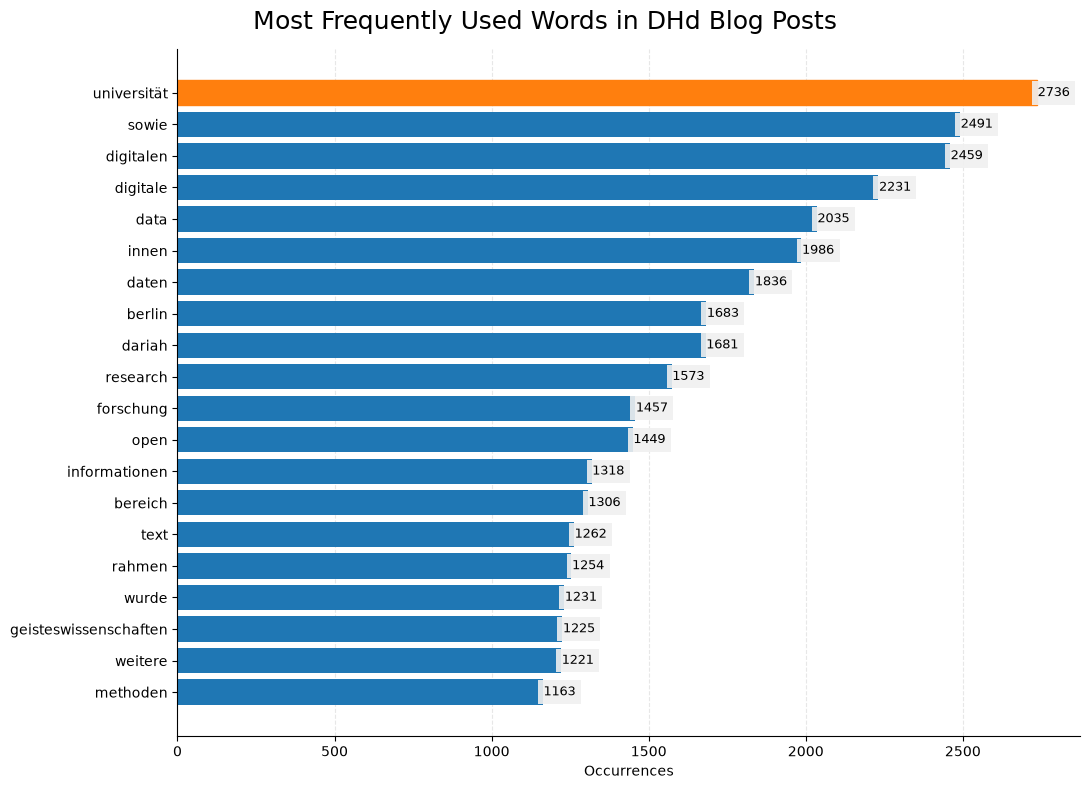

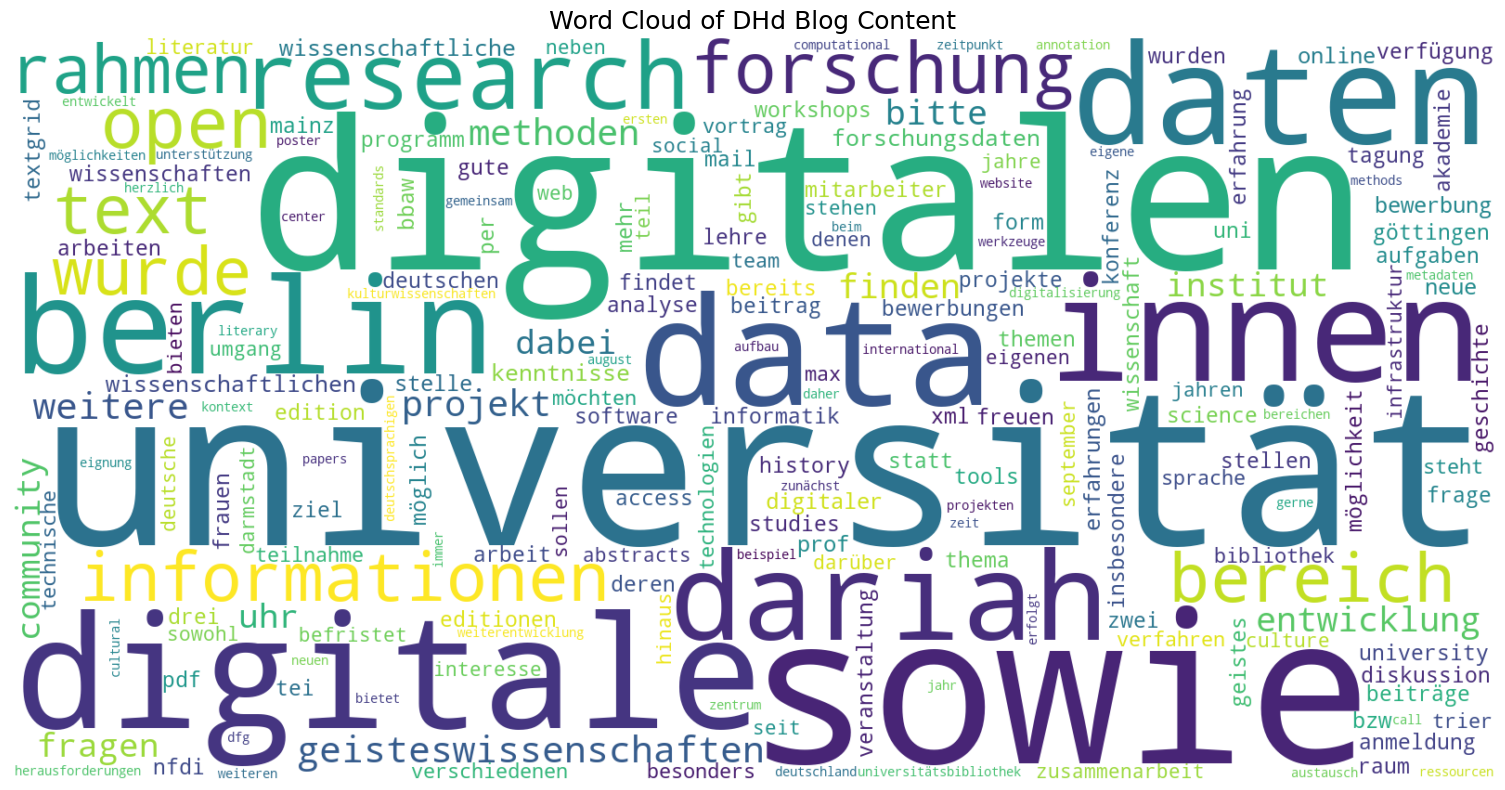

In [49]:
# ============================================================
# CLEAN TEXT + MOST FREQUENT WORDS + WORD CLOUD
# ============================================================





try:
    stopwords.words("german")
except LookupError:
    nltk.download("stopwords", quiet=True)

# ------------------------------------------------------------
# Combine all blog text
# ------------------------------------------------------------

text = (
    analysis_df["text"]
    .fillna("")
    .str.lower()
    .str.cat(sep=" ")
)

# ------------------------------------------------------------
# Remove URLs
# ------------------------------------------------------------

text = re.sub(r"http\S+", " ", text)

# ------------------------------------------------------------
# Remove HTML
# ------------------------------------------------------------

text = re.sub(r"<.*?>", " ", text)

# ------------------------------------------------------------
# Keep letters only
# ------------------------------------------------------------

text = re.sub(r"[^a-zA-ZäöüÄÖÜß ]", " ", text)

# ------------------------------------------------------------
# Tokenize
# ------------------------------------------------------------

words = text.split()

# ------------------------------------------------------------
# Stopwords
# ------------------------------------------------------------

stop_words = set(stopwords.words("english"))
stop_words.update(stopwords.words("german"))

# ------------------------------------------------------------
# Add custom stopwords
# ------------------------------------------------------------

custom_stopwords = {
    "dhd",
    "blog",
    "digital",
    "humanities",
    "https",
    "www",
    "org",
    "de",
    "com",
    "amp",
    "nbsp",
    "post",
    "posts",
    "information",
    "please",
    "using",
    "also",
    "one",
    "new",
    "can",
    "will",
    "may",
    "many",
    "within",
    "among",
    "based",
    "work",
    "project",
    "projects",
    "event",
    "events",
    "conference",
    "workshop"
}

stop_words.update(custom_stopwords)

# ------------------------------------------------------------
# Keep meaningful words
# ------------------------------------------------------------

clean_words = [
    word
    for word in words
    if (
        len(word) > 2
        and word not in stop_words
    )
]

# ------------------------------------------------------------
# Word frequencies
# ------------------------------------------------------------

word_counts = Counter(clean_words)

freq_df = (
    pd.DataFrame(
        word_counts.items(),
        columns=["word", "frequency"]
    )
    .sort_values(
        "frequency",
        ascending=False
    )
)

display(freq_df.head(30))

# ------------------------------------------------------------
# Horizontal bar chart
# ------------------------------------------------------------

top_words = (
    freq_df
    .head(20)
    .sort_values("frequency")
)

fig, ax = plt.subplots(figsize=(11,8))

bars = ax.barh(
    top_words["word"],
    top_words["frequency"]
)

bars[-1].set_color("tab:orange")

for bar in bars:

    ax.text(
        bar.get_width()+2,
        bar.get_y()+bar.get_height()/2,
        int(bar.get_width()),
        va="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Frequently Used Words in DHd Blog Posts",
    fontsize=18,
    fontweight="normal"
)

ax.set_xlabel("Occurrences")
ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# Word cloud
# ------------------------------------------------------------

wordcloud = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    max_words=200,
    collocations=False
).generate_from_frequencies(word_counts)

plt.figure(figsize=(16,8))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Word Cloud of DHd Blog Content",
    fontsize=18
)

plt.tight_layout()

plt.show()


## 13. Category by Month Heatmap

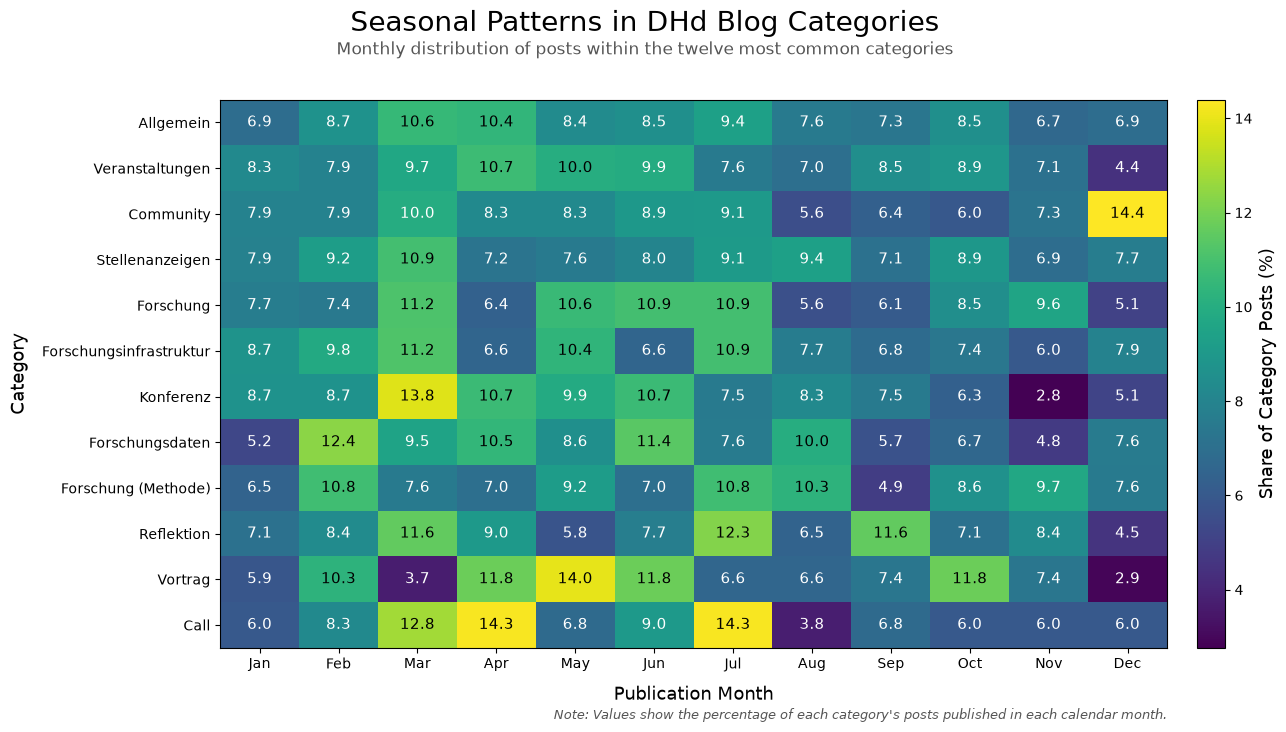

In [50]:
# ============================================================
# CATEGORY × MONTH HEATMAP
# ============================================================

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

category_month_df = (
    analysis_df[
        ["post_id", "month", "categories"]
    ]
    .copy()
)

category_month_df["categories"] = (
    category_month_df["categories"]
    .fillna("")
    .astype(str)
)

category_month_df = (
    category_month_df
    .assign(
        category=lambda data:
        data["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_month_df["category"] = (
    category_month_df["category"]
    .fillna("")
    .str.strip()
)

category_month_df = category_month_df[
    category_month_df["category"].ne("")
].copy()

category_month_df["month"] = pd.to_numeric(
    category_month_df["month"],
    errors="coerce"
)

category_month_df = category_month_df.dropna(
    subset=["month"]
)

category_month_df["month"] = (
    category_month_df["month"].astype(int)
)

# Count each post once per category
category_month_df = category_month_df.drop_duplicates(
    subset=["post_id", "category"]
)

# Keep top 12 categories
top_categories = (
    category_month_df["category"]
    .value_counts()
    .head(12)
    .index
)

category_month_df = category_month_df[
    category_month_df["category"].isin(top_categories)
]

# Raw counts
category_month_counts = (
    category_month_df
    .groupby(["category", "month"])["post_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

# Convert each row to percentages
category_month_share = (
    category_month_counts
    .div(category_month_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Sort categories by overall frequency
category_order = (
    category_month_counts
    .sum(axis=1)
    .sort_values(ascending=False)
    .index
)

category_month_share = category_month_share.loc[
    category_order
]

# Plot
fig, ax = plt.subplots(figsize=(13, 8))

image = ax.imshow(
    category_month_share.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels, fontsize=10)

ax.set_yticks(
    np.arange(len(category_month_share.index))
)

ax.set_yticklabels(
    category_month_share.index,
    fontsize=10
)

# Add values
norm = image.norm
cmap = image.cmap

for row in range(category_month_share.shape[0]):
    for column in range(category_month_share.shape[1]):

        value = category_month_share.iloc[row, column]

        # Get cell color from heatmap
        r, g, b, _ = cmap(norm(value))

        # Compute perceived brightness
        brightness = 0.299 * r + 0.587 * g + 0.114 * b

        # White text on dark cells, black text on light cells
        text_color = "white" if brightness < 0.5 else "black"

        ax.text(
            column,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=11,
            color=text_color
        )

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

colorbar.set_label(
    "Share of Category Posts (%)",
    fontsize=13
)

fig.suptitle(
    "Seasonal Patterns in DHd Blog Categories",
    fontsize=20,
    fontweight="normal",
    x=0.5,
    y=0.92,
    ha="center"
)

fig.text(
    0.5,
    0.870,
    "Monthly distribution of posts within the twelve most common categories",
    ha="center",
    va="center",
    fontsize=12,
    color="#555555"
)

ax.set_xlabel(
    "Publication Month",
    fontsize=13,
    labelpad=10
)

ax.set_ylabel(
    "Category",
    fontsize=13,
    labelpad=10
)

ax.text(
    1.0,
    -0.13,
    (
        "Note: Values show the percentage of each category's posts "
        "published in each calendar month."
    ),
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(rect=[0, 0, 1, 0.88])

plt.savefig(
    FIGURE_DIR / "category_by_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 14. Post Length × Category Boxplot

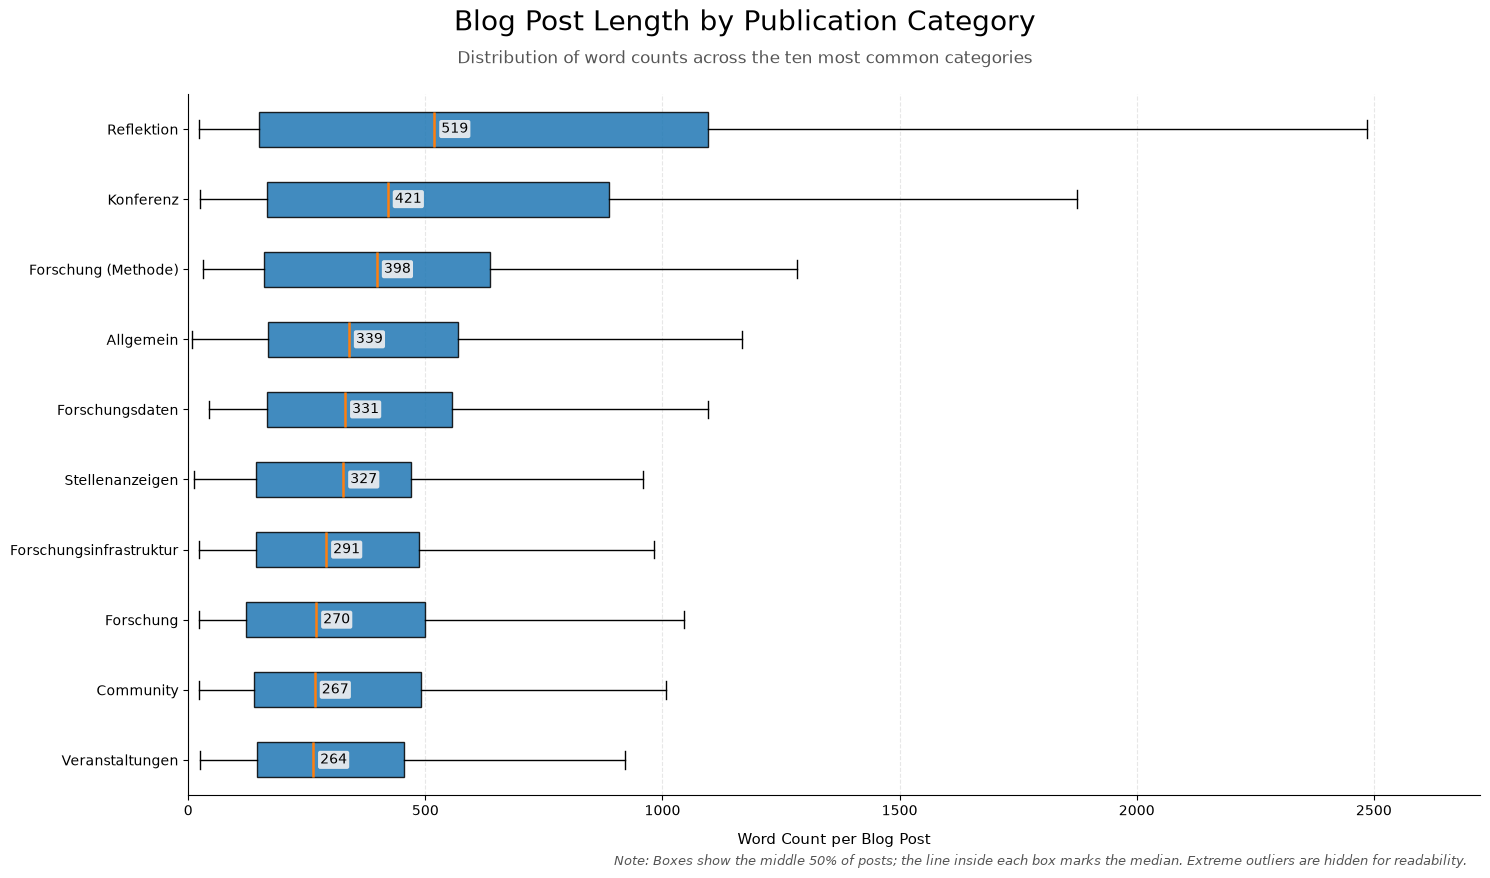

,posts,mean_words,median_words,minimum_words,maximum_words
category,,,,,
Reflektion,155,773.6,519.0,23,4393
Konferenz,253,660.3,421.0,25,4393
Forschung (Methode),185,579.4,398.0,31,6022
Allgemein,1240,467.3,339.0,8,4690
Forschungsdaten,210,522.3,331.0,43,4690
Stellenanzeigen,649,345.3,327.0,13,4171
Forschungsinfrastruktur,366,451.9,291.0,22,4690
Forschung,376,440.1,270.0,22,6022
Community,771,443.0,267.0,22,4690


In [51]:
# ============================================================
# POST LENGTH × CATEGORY BOXPLOT
# ============================================================

category_length_df = (
    analysis_df[
        ["post_id", "categories", "word_count"]
    ]
    .copy()
)

category_length_df["word_count"] = pd.to_numeric(
    category_length_df["word_count"],
    errors="coerce"
)

category_length_df["categories"] = (
    category_length_df["categories"]
    .fillna("")
    .astype(str)
)

category_length_df = (
    category_length_df
    .assign(
        category=lambda data:
        data["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_length_df["category"] = (
    category_length_df["category"]
    .fillna("")
    .str.strip()
)

category_length_df = category_length_df[
    category_length_df["category"].ne("")
].dropna(
    subset=["word_count"]
)

category_length_df = category_length_df[
    category_length_df["word_count"] > 0
].copy()

# Count each post once per category
category_length_df = category_length_df.drop_duplicates(
    subset=["post_id", "category"]
)

# Keep top 10 categories by number of posts
top_categories = (
    category_length_df["category"]
    .value_counts()
    .head(10)
    .index
)

plot_df = category_length_df[
    category_length_df["category"].isin(top_categories)
].copy()

# Order categories by median word count
category_order = (
    plot_df
    .groupby("category")["word_count"]
    .median()
    .sort_values()
    .index
)

box_data = [
    plot_df.loc[
        plot_df["category"] == category,
        "word_count"
    ].values
    for category in category_order
]

fig, ax = plt.subplots(figsize=(15, 9))

boxplot = ax.boxplot(
    box_data,
    orientation="horizontal",
    tick_labels=category_order,
    patch_artist=True,
    showfliers=False,
    medianprops={
        "linewidth": 1.8
    },
    boxprops={
        "alpha": 0.85
    },
    whiskerprops={
        "linewidth": 1
    },
    capprops={
        "linewidth": 1
    }
)

# Add median labels
for position, category in enumerate(
    category_order,
    start=1
):
    median_value = (
        plot_df.loc[
            plot_df["category"] == category,
            "word_count"
        ]
        .median()
    )

    ax.annotate(
        f"{median_value:.0f}",
        xy=(median_value, position),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# Limit display to 99th percentile
display_limit = plot_df["word_count"].quantile(0.99) * 1.08

ax.set_xlim(
    0,
    display_limit
)

fig.suptitle(
    "Blog Post Length by Publication Category",
    fontsize=20,
    fontweight="normal",
    x=0.5,
    y=0.97,
    ha="center"
)

fig.text(
    0.5,
    0.915,
    "Distribution of word counts across the ten most common categories",
    ha="center",
    va="center",
    fontsize=12,
    color="#555555"
)

ax.set_xlabel(
    "Word Count per Blog Post",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.text(
    0.99,
    -0.10,
    (
        "Note: Boxes show the middle 50% of posts; the line inside each "
        "box marks the median. Extreme outliers are hidden for readability."
    ),
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig(
    FIGURE_DIR / "word_count_by_category_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Supporting summary table
category_length_summary = (
    plot_df
    .groupby("category")["word_count"]
    .agg(
        posts="count",
        mean_words="mean",
        median_words="median",
        minimum_words="min",
        maximum_words="max"
    )
    .round(1)
    .sort_values(
        "median_words",
        ascending=False
    )
)

display(category_length_summary)


## 15. Category × Tag Relationship Heatmap

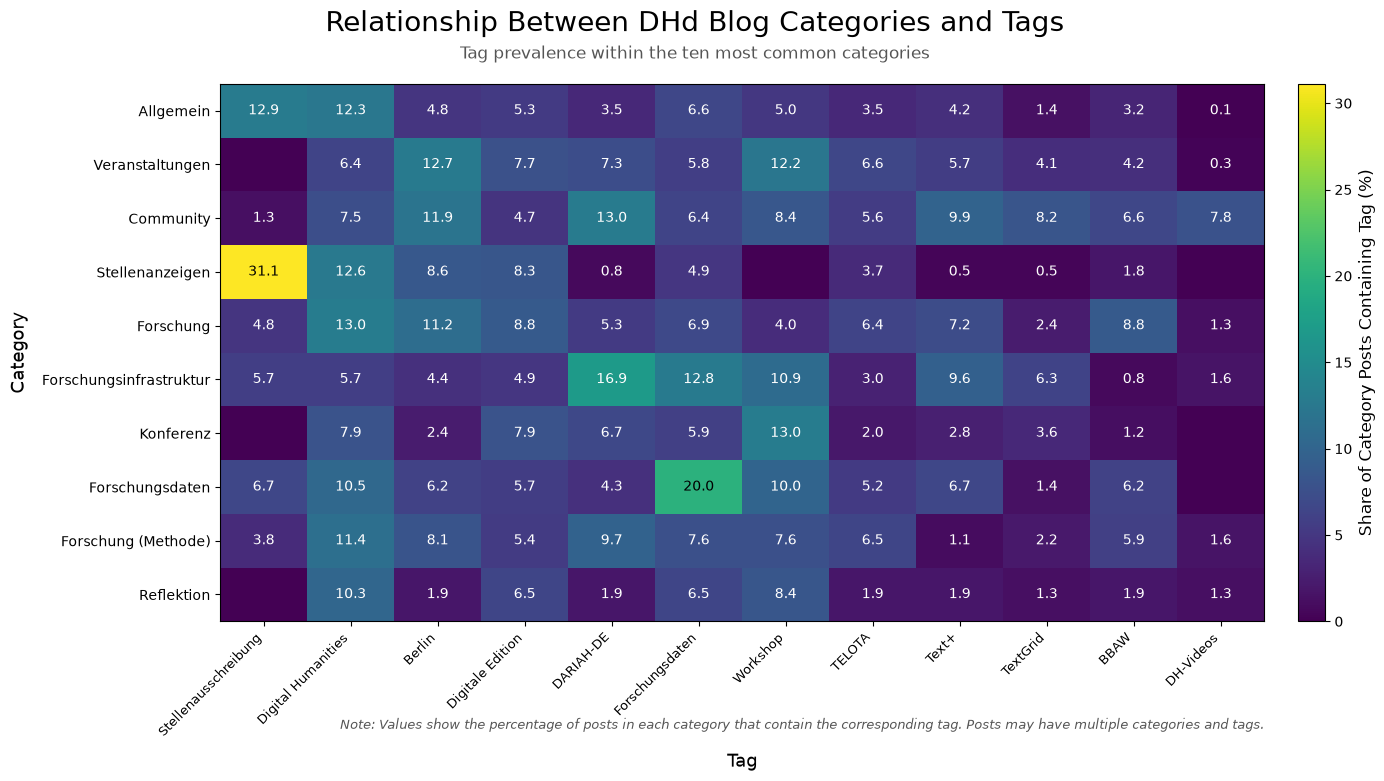

In [52]:
# ============================================================
# CATEGORY × TAG RELATIONSHIP HEATMAP
# ============================================================

relationship_df = analysis_df[
    ["post_id", "categories", "tags"]
].copy()

for column in ["categories", "tags"]:
    relationship_df[column] = (
        relationship_df[column]
        .fillna("")
        .astype(str)
    )

# Create category rows
category_rows = (
    relationship_df[
        ["post_id", "categories"]
    ]
    .assign(
        category=lambda data:
        data["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_rows["category"] = (
    category_rows["category"]
    .fillna("")
    .str.strip()
)

category_rows = category_rows[
    category_rows["category"].ne("")
].drop_duplicates(
    subset=["post_id", "category"]
)

# Create tag rows
tag_rows = (
    relationship_df[
        ["post_id", "tags"]
    ]
    .assign(
        tag=lambda data:
        data["tags"].str.split(r"\s*\|\s*")
    )
    .explode("tag")
)

tag_rows["tag"] = (
    tag_rows["tag"]
    .fillna("")
    .str.strip()
)

tag_rows = tag_rows[
    tag_rows["tag"].ne("")
].drop_duplicates(
    subset=["post_id", "tag"]
)

# Select top categories and tags
top_categories = (
    category_rows["category"]
    .value_counts()
    .head(10)
    .index
)

top_tags = (
    tag_rows["tag"]
    .value_counts()
    .head(12)
    .index
)

category_rows = category_rows[
    category_rows["category"].isin(top_categories)
]

tag_rows = tag_rows[
    tag_rows["tag"].isin(top_tags)
]

# Join categories and tags through post ID
category_tag_pairs = category_rows.merge(
    tag_rows,
    on="post_id",
    how="inner"
)

# Number of posts in every category
category_totals = (
    category_rows
    .groupby("category")["post_id"]
    .nunique()
)

# Number of posts containing each category-tag pair
category_tag_counts = (
    category_tag_pairs
    .groupby(["category", "tag"])["post_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        index=top_categories,
        columns=top_tags,
        fill_value=0
    )
)

# Convert to percentage within category
category_tag_share = (
    category_tag_counts
    .div(category_totals, axis=0)
    .mul(100)
)

# Sort categories by overall count
category_order = (
    category_totals
    .sort_values(ascending=False)
    .index
)

category_tag_share = category_tag_share.loc[
    category_order
]

fig, ax = plt.subplots(figsize=(14, 8))

image = ax.imshow(
    category_tag_share.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(category_tag_share.columns))
)

ax.set_xticklabels(
    category_tag_share.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(category_tag_share.index))
)

ax.set_yticklabels(
    category_tag_share.index,
    fontsize=10
)

# Add values
norm = image.norm
cmap = image.cmap

for row in range(category_tag_share.shape[0]):
    for column in range(category_tag_share.shape[1]):

        value = category_tag_share.iloc[row, column]

        if value > 0:

            # Get the cell color
            r, g, b, _ = cmap(norm(value))

            # Compute perceived brightness
            brightness = 0.299 * r + 0.587 * g + 0.114 * b

            # White text on dark cells, black text on light cells
            text_color = "white" if brightness < 0.5 else "black"

            ax.text(
                column,
                row,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=10,
                color=text_color
            )

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

colorbar.set_label(
    "Share of Category Posts Containing Tag (%)",
    fontsize=12
)

fig.suptitle(
    "Relationship Between DHd Blog Categories and Tags",
    fontsize=20,
    fontweight="normal",
    x=0.5,
    y=0.97,
    ha="center"
)

fig.text(
    0.5,
    0.915,
    "Tag prevalence within the ten most common categories",
    ha="center",
    va="center",
    fontsize=12,
    color="#555555"
)

ax.set_xlabel(
    "Tag",
    fontsize=13,
    labelpad=10
)

ax.set_ylabel(
    "Category",
    fontsize=13,
    labelpad=10
)

ax.text(
    1.0,
    -0.20,
    (
        "Note: Values show the percentage of posts in each category "
        "that contain the corresponding tag. Posts may have multiple "
        "categories and tags."
    ),
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    FIGURE_DIR / "category_tag_relationship_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 16. Category Co-occurence heatmap

Categories selected for the heatmap:
['Community', 'Veranstaltungen', 'Allgemein', 'Stellenanzeigen', 'Forschungsinfrastruktur', 'Konferenz', 'Forschung', 'Forschungsdaten', 'Vortrag']


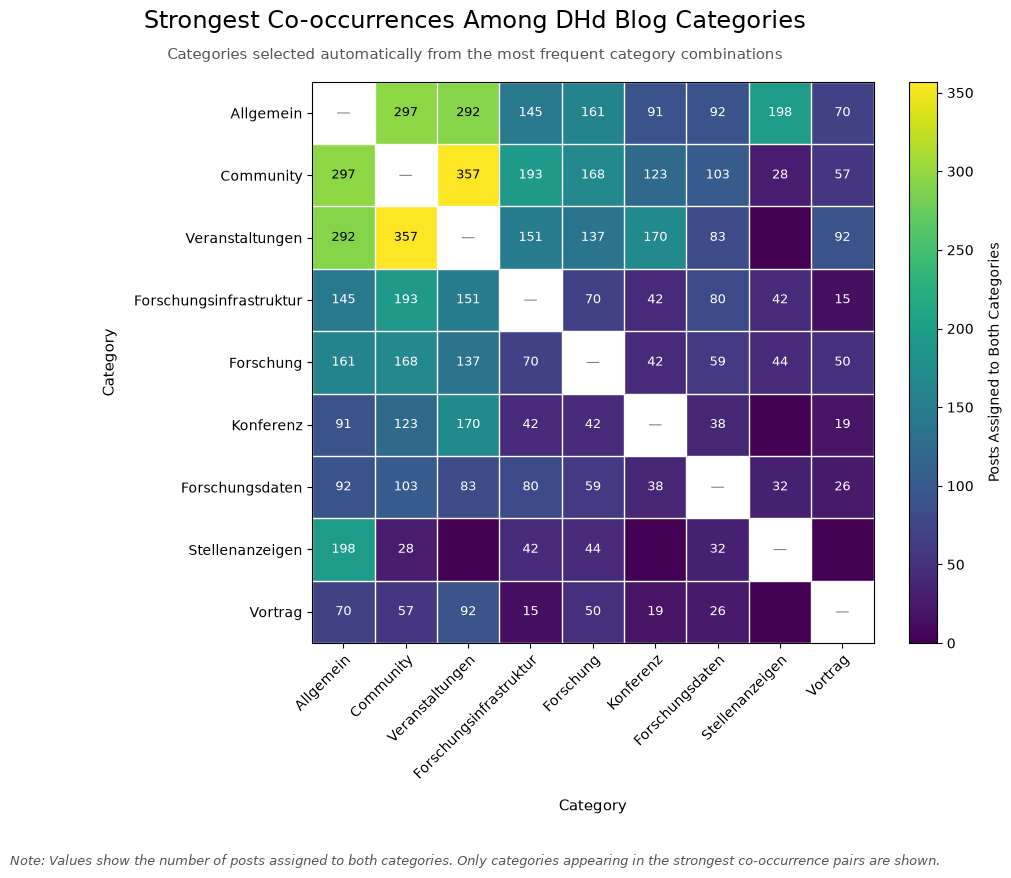

category_1,category_2,cooccurring_posts
Community,Veranstaltungen,357
Allgemein,Community,297
Allgemein,Veranstaltungen,292
Allgemein,Stellenanzeigen,198
Community,Forschungsinfrastruktur,193
Konferenz,Veranstaltungen,170
Community,Forschung,168
Allgemein,Forschung,161
Forschungsinfrastruktur,Veranstaltungen,151
Allgemein,Forschungsinfrastruktur,145


In [53]:
# ============================================================
# 1. CLEAN AND SPLIT CATEGORIES
# ============================================================

category_lists = (
    analysis_df["categories"]
    .fillna("")
    .astype(str)
    .str.split(r"\s*\|\s*")
)

clean_category_lists = []

for categories in category_lists:

    cleaned = sorted({
        category.strip()
        for category in categories
        if category.strip()
    })

    clean_category_lists.append(cleaned)


# ============================================================
# 2. COUNT CATEGORY PAIRS
# ============================================================

pair_counts = Counter()

for categories in clean_category_lists:

    for category_1, category_2 in combinations(categories, 2):
        pair_counts[(category_1, category_2)] += 1


pair_df = pd.DataFrame(
    [
        {
            "category_1": category_1,
            "category_2": category_2,
            "cooccurring_posts": count
        }
        for (category_1, category_2), count in pair_counts.items()
    ]
)

if pair_df.empty:
    raise ValueError(
        "No category co-occurrences were found. "
        "Check how categories are separated in the dataset."
    )

pair_df = (
    pair_df
    .sort_values(
        "cooccurring_posts",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 3. SELECT CATEGORIES FROM THE STRONGEST RELATIONSHIPS
# ============================================================

TOP_PAIRS = 15
MAX_CATEGORIES = 10

strongest_pairs = pair_df.head(TOP_PAIRS)

selected_categories = []

for _, row in strongest_pairs.iterrows():

    for category in [
        row["category_1"],
        row["category_2"]
    ]:

        if category not in selected_categories:
            selected_categories.append(category)

    if len(selected_categories) >= MAX_CATEGORIES:
        break

selected_categories = selected_categories[:MAX_CATEGORIES]

print("Categories selected for the heatmap:")
print(selected_categories)


# ============================================================
# 4. CREATE CO-OCCURRENCE MATRIX
# ============================================================

cooccurrence_matrix = pd.DataFrame(
    0,
    index=selected_categories,
    columns=selected_categories,
    dtype=int
)

for _, row in pair_df.iterrows():

    category_1 = row["category_1"]
    category_2 = row["category_2"]
    count = int(row["cooccurring_posts"])

    if (
        category_1 in selected_categories
        and category_2 in selected_categories
    ):

        cooccurrence_matrix.loc[
            category_1,
            category_2
        ] = count

        cooccurrence_matrix.loc[
            category_2,
            category_1
        ] = count


# Keep diagonal empty because the chart focuses on relationships
display_matrix = cooccurrence_matrix.astype(float).copy()

for category in selected_categories:
    display_matrix.loc[
        category,
        category
    ] = np.nan


# Order categories by total relationship strength
category_strength = (
    cooccurrence_matrix
    .sum(axis=1)
    .sort_values(ascending=False)
)

category_order = category_strength.index.tolist()

display_matrix = display_matrix.loc[
    category_order,
    category_order
]

cooccurrence_matrix = cooccurrence_matrix.loc[
    category_order,
    category_order
]


# ============================================================
# 5. DRAW HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

masked_values = np.ma.masked_invalid(
    display_matrix.to_numpy()
)

image = ax.imshow(
    masked_values,
    aspect="equal",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(category_order))
)

ax.set_xticklabels(
    category_order,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_yticks(
    np.arange(len(category_order))
)

ax.set_yticklabels(
    category_order,
    fontsize=10
)

maximum_value = np.nanmax(
    display_matrix.to_numpy()
)


# Add relationship counts
for row_index in range(len(category_order)):
    for column_index in range(len(category_order)):

        value = display_matrix.iloc[
            row_index,
            column_index
        ]

        if pd.notna(value) and value > 0:

            red, green, blue, alpha = image.cmap(
                image.norm(value)
            )

            luminance = (
                0.299 * red
                + 0.587 * green
                + 0.114 * blue
            )

            text_color = (
                "black"
                if luminance > 0.55
                else "white"
            )

            ax.text(
                column_index,
                row_index,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=9,
                color=text_color
            )


# Mark diagonal cells
for index in range(len(category_order)):

    ax.text(
        index,
        index,
        "—",
        ha="center",
        va="center",
        fontsize=10,
        color="#777777"
    )


# Grid lines between cells
ax.set_xticks(
    np.arange(
        -0.5,
        len(category_order),
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        len(category_order),
        1
    ),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)


# Color bar
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Posts Assigned to Both Categories",
    fontsize=10,
    labelpad=10
)


# ============================================================
# 6. TITLE AND NOTES
# ============================================================

fig.suptitle(
    "Strongest Co-occurrences Among DHd Blog Categories",
    fontsize=17,
    fontweight="normal",
    x=0.5,
    y=0.97,
    ha="center"
)

fig.text(
    0.5,
    0.920,
    "Categories selected automatically from the most frequent category combinations",
    ha="center",
    va="center",
    fontsize=11,
    color="#555555"
)

ax.set_xlabel(
    "Category",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Category",
    fontsize=11,
    labelpad=12
)

fig.text(
    0.5,
    0.02,
    (
        "Note: Values show the number of posts assigned to both categories. "
        "Only categories appearing in the strongest co-occurrence pairs "
        "are shown."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "strongest_category_cooccurrences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. DISPLAY STRONGEST RELATIONSHIPS
# ============================================================

styled_pair_df = (
    pair_df
    .head(20)
    .style
    .hide(axis="index")
    .format({
        "cooccurring_posts": "{:,.0f}"
    })
    .set_caption(
        "Strongest Category Co-occurrence Relationships"
    )
)

display(styled_pair_df)

## 17. Distribution of Categories and Tags Assigned per DHd Blog Post



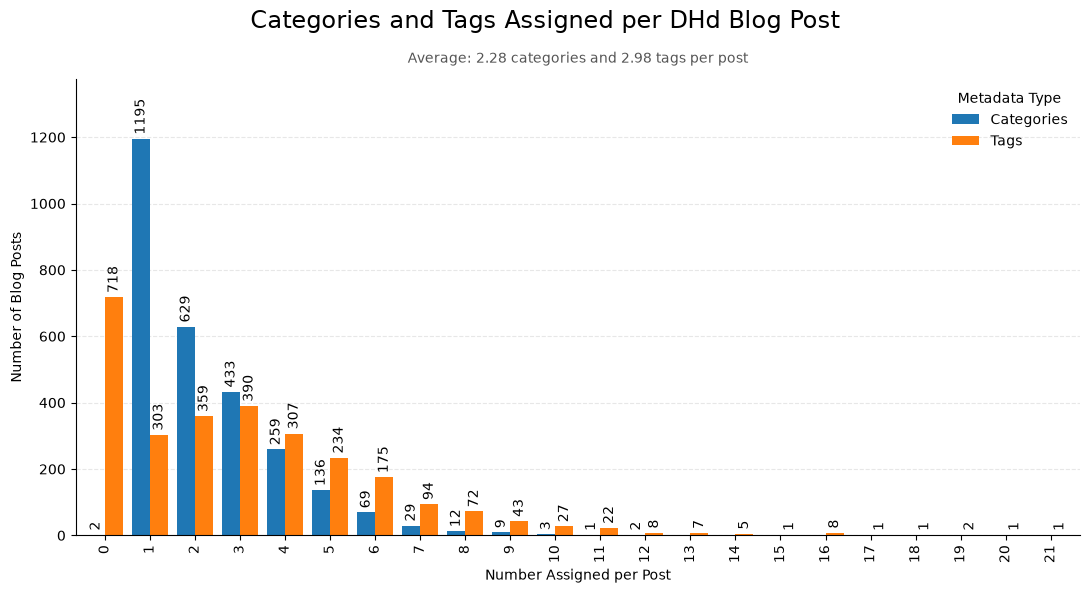

In [54]:
# Count categories and tags per post
category_count = (
    analysis_df["categories"].fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({v.strip() for v in x if v.strip()}))
)

tag_count = (
    analysis_df["tags"].fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({v.strip() for v in x if v.strip()}))
)

# Create one shared range
max_count = max(category_count.max(), tag_count.max())
count_range = range(0, max_count + 1)

comparison = pd.DataFrame({
    "Categories": category_count.value_counts().reindex(count_range, fill_value=0),
    "Tags": tag_count.value_counts().reindex(count_range, fill_value=0)
})

# Plot
fig, ax = plt.subplots(figsize=(11, 6))

comparison.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

# Vertical data labels
for container in ax.containers:
    labels = [
        f"{int(bar.get_height())}" if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3,
        rotation=90,
        fontsize=10
    )

fig.suptitle(
    "Categories and Tags Assigned per DHd Blog Post",
    fontsize=17,
    fontweight="normal"
)

ax.set_title(
    f"Average: {category_count.mean():.2f} categories and "
    f"{tag_count.mean():.2f} tags per post",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Number Assigned per Post")
ax.set_ylabel("Number of Blog Posts")

ax.legend(
    title="Metadata Type",
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Extra space for labels above bars
ax.margins(y=0.15)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "categories_and_tags_per_post.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 18. Average Number of Tags and Categories per post per Year

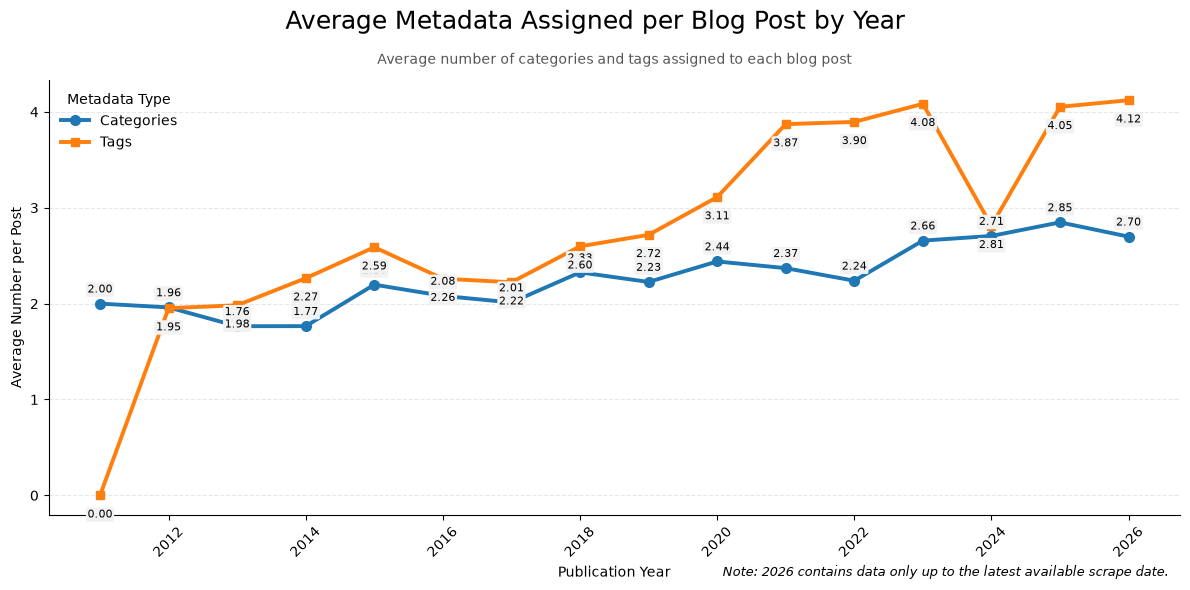

In [55]:
# ============================================================
# Average Categories & Tags per Post by Year
# ============================================================

# Categories per post
analysis_df["category_count"] = (
    analysis_df["categories"]
    .fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({c.strip() for c in x if c.strip()}))
)

# Tags per post
analysis_df["tag_count"] = (
    analysis_df["tags"]
    .fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({t.strip() for t in x if t.strip()}))
)

# Yearly averages
yearly_avg = (
    analysis_df
    .groupby("year")[["category_count", "tag_count"]]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

# Categories
ax.plot(
    yearly_avg["year"],
    yearly_avg["category_count"],
    marker="o",
    linewidth=2.8,
    markersize=7,
    label="Categories"
)

# Tags
ax.plot(
    yearly_avg["year"],
    yearly_avg["tag_count"],
    marker="s",
    linewidth=2.8,
    markersize=6,
    label="Tags"
)

# Data labels
for _, row in yearly_avg.iterrows():

    ax.annotate(
        f"{row['category_count']:.2f}",
        (row["year"], row["category_count"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

    ax.annotate(
        f"{row['tag_count']:.2f}",
        (row["year"], row["tag_count"]),
        textcoords="offset points",
        xytext=(0, -16),
        ha="center",
        fontsize=8,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

fig.suptitle(
    "Average Metadata Assigned per Blog Post by Year",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Average number of categories and tags assigned to each blog post",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Publication Year")
ax.set_ylabel("Average Number per Post")

ax.legend(
    title="Metadata Type",
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", rotation=45)

if 2026 in yearly_avg["year"].values:
    ax.text(
        0.99,
        -0.14,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "average_metadata_per_post_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 19. Number of Unique Categories per Year

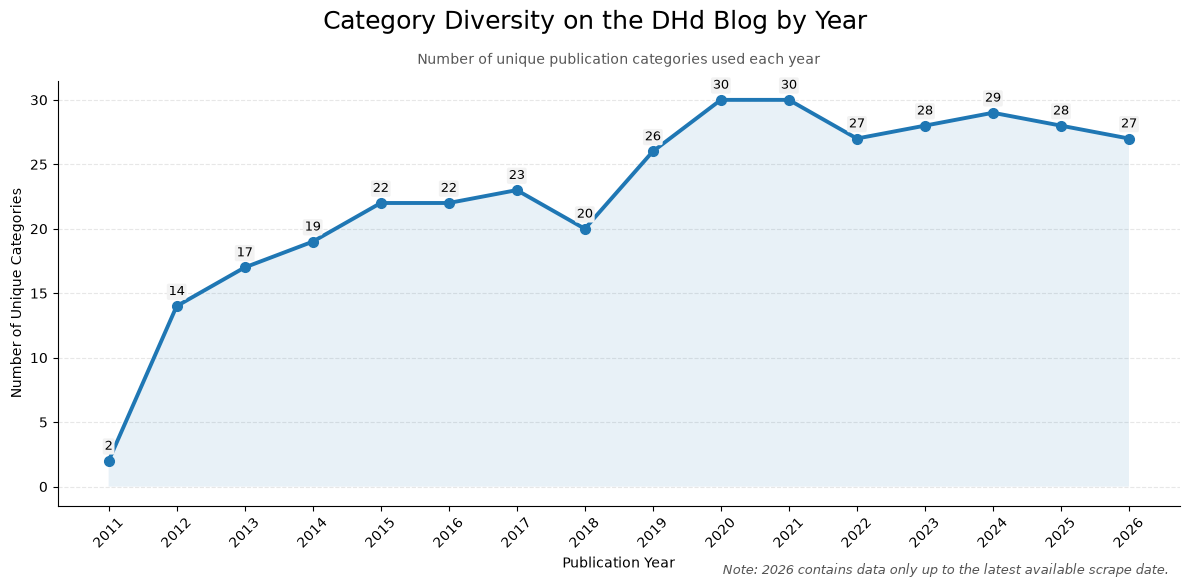

In [56]:
# Split categories into separate rows
category_year_df = (
    analysis_df[["year", "categories"]]
    .dropna(subset=["year"])
    .assign(
        category=lambda x:
        x["categories"].fillna("").str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_year_df["category"] = (
    category_year_df["category"]
    .fillna("")
    .str.strip()
)

category_year_df = category_year_df[
    category_year_df["category"] != ""
]

# Count unique categories per year
category_diversity = (
    category_year_df
    .groupby("year")["category"]
    .nunique()
    .reset_index(name="unique_categories")
)

category_diversity["year"] = (
    category_diversity["year"].astype(int)
)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    category_diversity["year"],
    category_diversity["unique_categories"],
    marker="o",
    linewidth=2.8,
    markersize=7
)

ax.fill_between(
    category_diversity["year"],
    category_diversity["unique_categories"],
    alpha=0.10
)

# Data labels
for _, row in category_diversity.iterrows():
    ax.annotate(
        f"{int(row['unique_categories'])}",
        (row["year"], row["unique_categories"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

fig.suptitle(
    "Category Diversity on the DHd Blog by Year",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Number of unique publication categories used each year",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Publication Year")
ax.set_ylabel("Number of Unique Categories")

ax.set_xticks(category_diversity["year"])
ax.tick_params(axis="x", rotation=45)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

if 2026 in category_diversity["year"].values:
    ax.text(
        0.99,
        -0.16,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic",
        color="#555555"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "category_diversity_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 20. Authors with the Longest Average Blog Posts

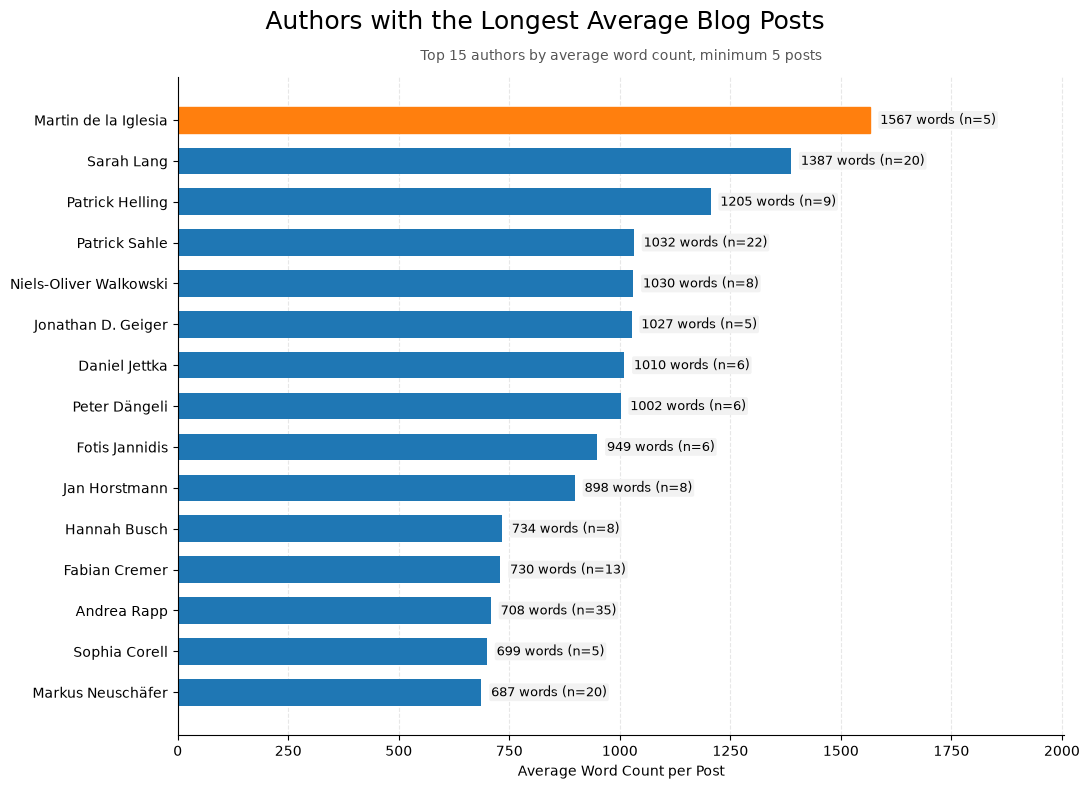

,author,posts,average_words
234,Martin de la Iglesia,5,1567.000000
317,Sarah Lang,20,1387.450000
284,Patrick Helling,9,1205.333333
285,Patrick Sahle,22,1031.863636
273,Niels-Oliver Walkowski,8,1030.375000
160,Jonathan D. Geiger,5,1026.600000
78,Daniel Jettka,6,1010.000000
290,Peter Dängeli,6,1001.666667
108,Fotis Jannidis,6,949.000000
139,Jan Horstmann,8,898.250000


In [57]:
# Prepare author statistics
author_word_stats = (
    analysis_df
    .assign(
        word_count=pd.to_numeric(
            analysis_df["word_count"],
            errors="coerce"
        )
    )
    .dropna(subset=["author", "word_count"])
    .groupby("author")
    .agg(
        posts=("word_count", "count"),
        average_words=("word_count", "mean")
    )
    .reset_index()
)

# Keep authors with at least 5 posts
MIN_POSTS = 5

top_authors = (
    author_word_stats[
        author_word_stats["posts"] >= MIN_POSTS
    ]
    .nlargest(15, "average_words")
    .sort_values("average_words")
)

# Plot
fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    top_authors["author"],
    top_authors["average_words"],
    height=0.65
)

# Highlight highest average
bars[-1].set_color("tab:orange")

# Labels: average words and number of posts
for bar, avg_words, posts in zip(
    bars,
    top_authors["average_words"],
    top_authors["posts"]
):
    ax.annotate(
        f"{avg_words:.0f} words (n={posts})",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

fig.suptitle(
    "Authors with the Longest Average Blog Posts",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    f"Top 15 authors by average word count, minimum {MIN_POSTS} posts",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Average Word Count per Post")
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(
    0,
    top_authors["average_words"].max() * 1.28
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "author_average_word_count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    top_authors.sort_values(
        "average_words",
        ascending=False
    )
)


## 21. Monthly Publishing Patterns by Category


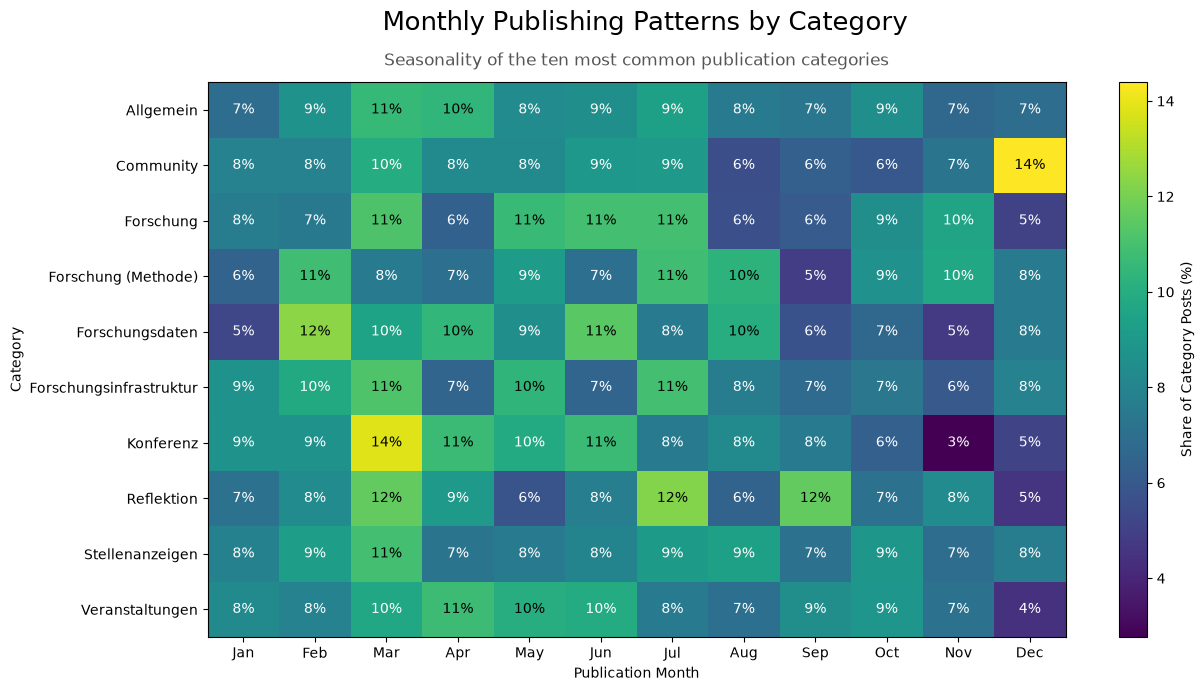

In [58]:
# ============================================================
# Monthly Publishing Patterns by Category
# ============================================================

month_labels = [
    "Jan","Feb","Mar","Apr","May","Jun",
    "Jul","Aug","Sep","Oct","Nov","Dec"
]

# Split categories
category_df = (
    analysis_df[
        ["post_id","month","categories"]
    ]
    .copy()
)

category_df["categories"] = (
    category_df["categories"]
    .fillna("")
    .str.split(r"\s*\|\s*")
)

category_df = category_df.explode("categories")

category_df["categories"] = (
    category_df["categories"]
    .str.strip()
)

category_df = category_df[
    category_df["categories"] != ""
]

# Keep Top 10 categories
top_categories = (
    category_df["categories"]
    .value_counts()
    .head(10)
    .index
)

category_df = category_df[
    category_df["categories"].isin(top_categories)
]

# Create matrix
heatmap = (
    category_df
    .groupby(["categories","month"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1,13),fill_value=0)
)

# Convert to %
heatmap = (
    heatmap
    .div(heatmap.sum(axis=1),axis=0)
    *100
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(13,7))

im = ax.imshow(
    heatmap,
    aspect="auto"
)

# Labels
ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(np.arange(len(heatmap.index)))
ax.set_yticklabels(heatmap.index)

# Cell labels
# Cell labels with automatic text color
norm = im.norm
cmap = im.cmap

for i in range(len(heatmap.index)):
    for j in range(12):

        value = heatmap.iloc[i, j]

        r, g, b, _ = cmap(norm(value))

        brightness = 0.299 * r + 0.587 * g + 0.114 * b

        text_color = "white" if brightness < 0.5 else "black"

        ax.text(
            j,
            i,
            f"{value:.0f}%",
            ha="center",
            va="center",
            fontsize=10,
            color=text_color
        )

cbar = plt.colorbar(im)
cbar.set_label(
    "Share of Category Posts (%)"
)

fig.suptitle(
    "Monthly Publishing Patterns by Category",
    fontsize=19,
    fontweight="normal"
)

ax.set_title(
    "Seasonality of the ten most common publication categories",
    fontsize=12,
    color="#555555",
    pad=12
)

ax.set_xlabel("Publication Month")
ax.set_ylabel("Category")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "monthly_category_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 22. Distribution of Digital Humanities research topics across the ten most common publication categories

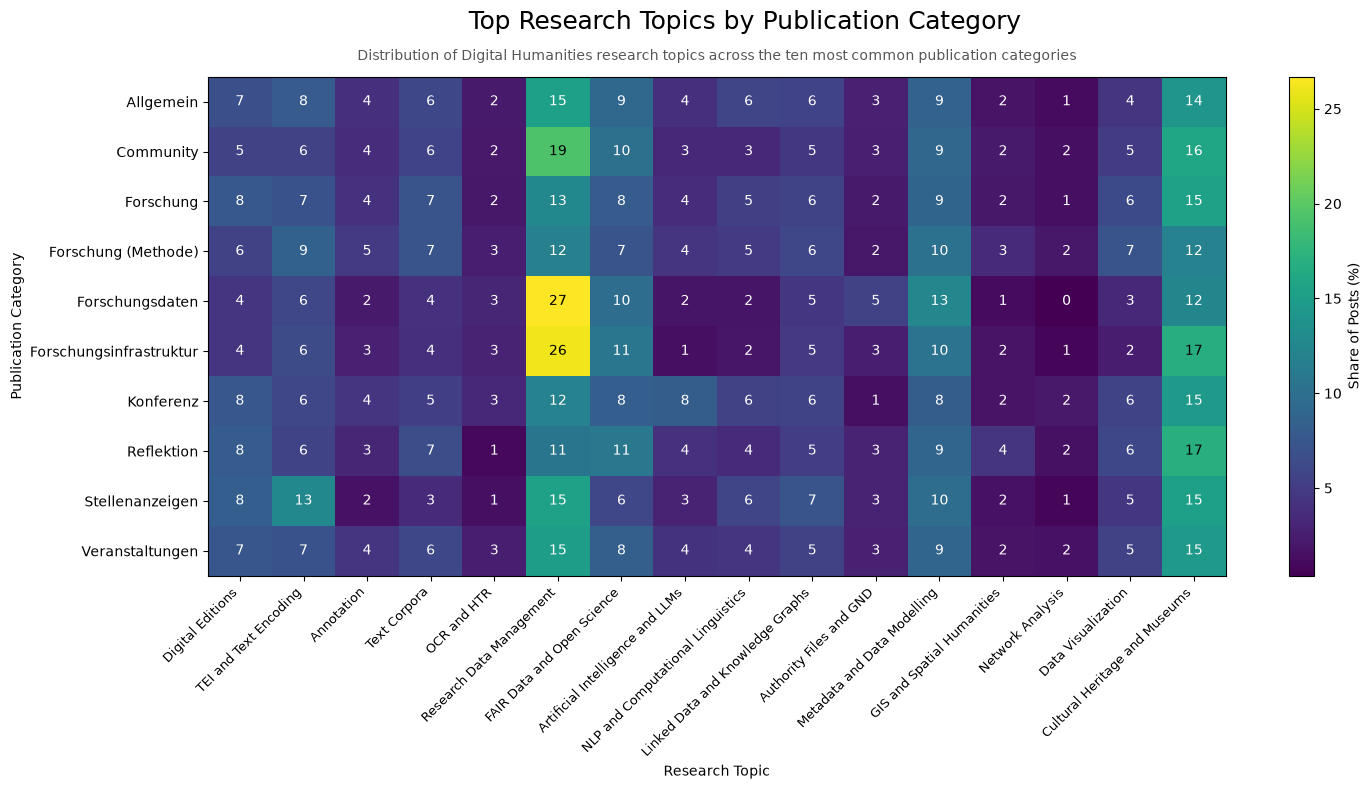

,Digital Editions,TEI and Text Encoding,Annotation,Text Corpora,OCR and HTR,Research Data Management,FAIR Data and Open Science,Artificial Intelligence and LLMs,NLP and Computational Linguistics,Linked Data and Knowledge Graphs,Authority Files and GND,Metadata and Data Modelling,GIS and Spatial Humanities,Network Analysis,Data Visualization,Cultural Heritage and Museums
Allgemein,167,197,98,151,57,375,230,97,145,141,70,213,44,29,107,349
Community,73,74,50,76,29,258,134,45,46,62,36,121,30,20,67,212
Forschung,58,53,31,55,16,96,61,28,41,44,17,67,16,11,48,117
Forschung (Methode),24,37,21,31,11,51,31,19,21,26,9,44,15,9,31,52
Forschungsdaten,23,32,12,22,17,142,52,10,10,24,29,67,6,2,18,66
Forschungsinfrastruktur,31,44,19,27,20,181,74,10,14,33,18,72,12,5,17,116
Konferenz,42,33,24,29,19,67,46,45,31,32,8,45,10,12,32,81
Reflektion,25,18,10,21,3,33,34,13,11,16,9,28,14,5,19,53
Stellenanzeigen,106,163,21,45,19,198,77,38,76,93,38,126,22,9,59,196
Veranstaltungen,113,107,68,93,40,232,127,64,66,83,42,137,27,25,84,223


In [59]:
# ============================================================
# PREPARE DATA
# ============================================================

category_topic_df = analysis_df.copy()

for col in ["categories", "title", "tags", "text"]:
    category_topic_df[col] = (
        category_topic_df[col]
        .fillna("")
        .astype(str)
    )

category_topic_df["search_text"] = (
    category_topic_df["title"] + " " +
    category_topic_df["tags"] + " " +
    category_topic_df["text"]
).str.lower()

# Split categories
category_topic_df = (
    category_topic_df
    .assign(
        category=lambda x:
        x["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_topic_df["category"] = (
    category_topic_df["category"]
    .str.strip()
)

category_topic_df = category_topic_df[
    category_topic_df["category"] != ""
]

# Keep only top 10 categories
top_categories = (
    category_topic_df["category"]
    .value_counts()
    .head(10)
    .index
)

category_topic_df = category_topic_df[
    category_topic_df["category"].isin(top_categories)
]

# ============================================================
# DETECT RESEARCH TOPICS
# ============================================================

matrix = pd.DataFrame(
    0,
    index=sorted(top_categories),
    columns=topic_keywords.keys()
)

for topic, keywords in topic_keywords.items():

    pattern = "|".join(
        rf"(?<!\w){re.escape(k.lower())}(?!\w)"
        for k in keywords
    )

    matches = category_topic_df[
        category_topic_df["search_text"].str.contains(
            pattern,
            regex=True,
            na=False
        )
    ]

    counts = (
        matches
        .groupby("category")
        .size()
    )

    for cat, value in counts.items():
        matrix.loc[cat, topic] = value

# Convert to row percentages
matrix_pct = (
    matrix
    .div(matrix.sum(axis=1), axis=0)
    * 100
).fillna(0)

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(15,8))

im = ax.imshow(
    matrix_pct.values,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(matrix_pct.columns))
)

ax.set_xticklabels(
    matrix_pct.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(matrix_pct.index))
)

ax.set_yticklabels(
    matrix_pct.index,
    fontsize=10
)

# Cell values
# Cell values
norm = im.norm
cmap = im.cmap

for i in range(matrix_pct.shape[0]):
    for j in range(matrix_pct.shape[1]):

        value = matrix_pct.iloc[i, j]

        if value > 0:

            # Get the cell color
            r, g, b, _ = cmap(norm(value))

            # Compute perceived brightness
            brightness = 0.299 * r + 0.587 * g + 0.114 * b

            # White text on dark cells, black text on light cells
            text_color = "white" if brightness < 0.5 else "black"

            ax.text(
                j,
                i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=10,
                color=text_color
            )

cbar = plt.colorbar(im)
cbar.set_label("Share of Posts (%)")

fig.suptitle(
    "Top Research Topics by Publication Category",
    fontsize=18,
    fontweight="normal"
)

ax.set_title(
    "Distribution of Digital Humanities research topics across the ten most common publication categories",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Research Topic")
ax.set_ylabel("Publication Category")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_research_topics_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(matrix.sort_index())


## 23. How frequently Digital Humanities research topics appear together in the same blog post

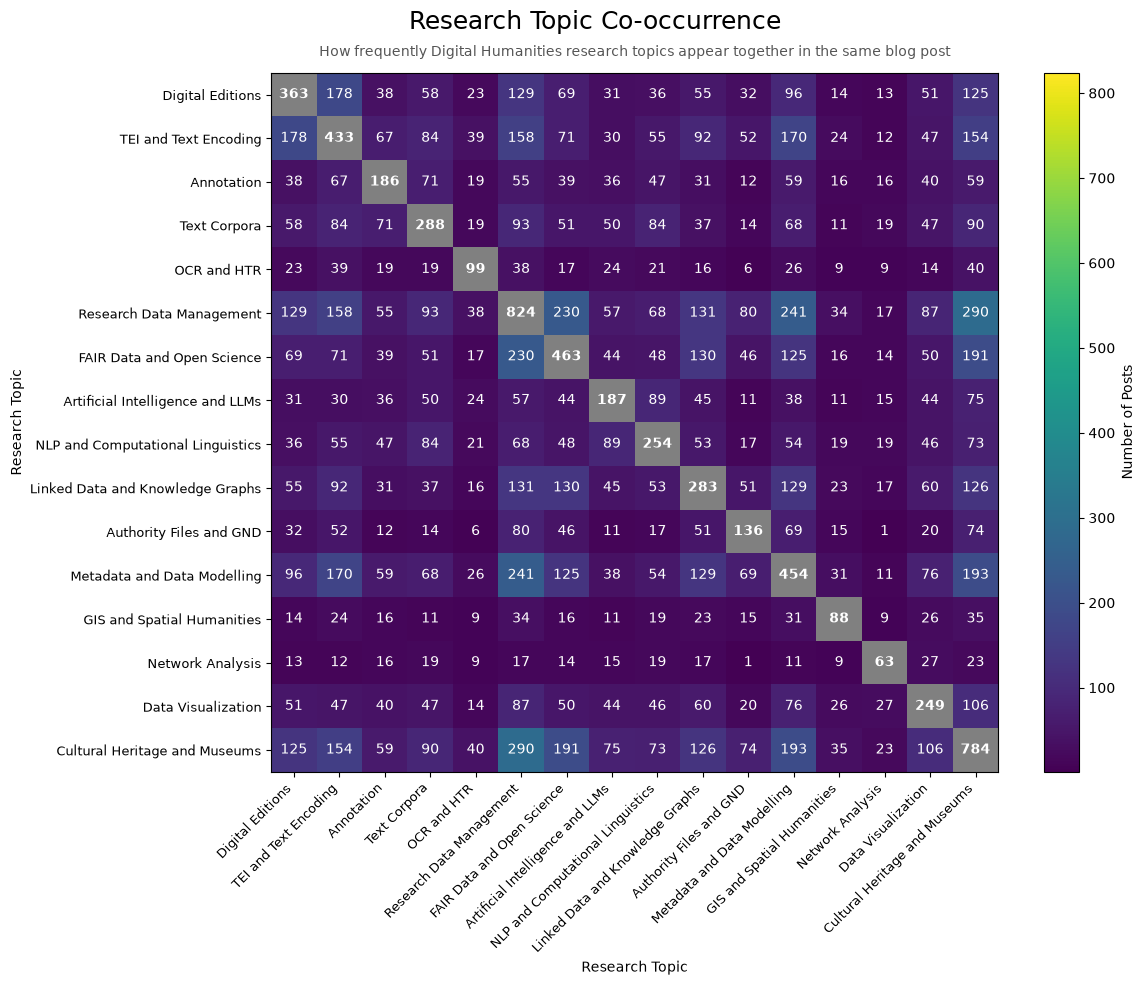

,Digital Editions,TEI and Text Encoding,Annotation,Text Corpora,OCR and HTR,Research Data Management,FAIR Data and Open Science,Artificial Intelligence and LLMs,NLP and Computational Linguistics,Linked Data and Knowledge Graphs,Authority Files and GND,Metadata and Data Modelling,GIS and Spatial Humanities,Network Analysis,Data Visualization,Cultural Heritage and Museums
Digital Editions,363,178,38,58,23,129,69,31,36,55,32,96,14,13,51,125
TEI and Text Encoding,178,433,67,84,39,158,71,30,55,92,52,170,24,12,47,154
Annotation,38,67,186,71,19,55,39,36,47,31,12,59,16,16,40,59
Text Corpora,58,84,71,288,19,93,51,50,84,37,14,68,11,19,47,90
OCR and HTR,23,39,19,19,99,38,17,24,21,16,6,26,9,9,14,40
Research Data Management,129,158,55,93,38,824,230,57,68,131,80,241,34,17,87,290
FAIR Data and Open Science,69,71,39,51,17,230,463,44,48,130,46,125,16,14,50,191
Artificial Intelligence and LLMs,31,30,36,50,24,57,44,187,89,45,11,38,11,15,44,75
NLP and Computational Linguistics,36,55,47,84,21,68,48,89,254,53,17,54,19,19,46,73
Linked Data and Knowledge Graphs,55,92,31,37,16,131,130,45,53,283,51,129,23,17,60,126


In [60]:
# ============================================================
# Research Topic Co-occurrence
# ============================================================

topic_df = analysis_df.copy()

for col in ["title", "tags", "text", "categories"]:
    topic_df[col] = (
        topic_df[col]
        .fillna("")
        .astype(str)
    )

topic_df["search_text"] = (
    topic_df["title"] + " " +
    topic_df["tags"] + " " +
    topic_df["categories"] + " " +
    topic_df["text"]
).str.lower()

# Detect topics
topic_presence = pd.DataFrame(index=topic_df.index)

for topic, keywords in topic_keywords.items():

    pattern = "|".join(
        rf"(?<!\w){re.escape(k.lower())}(?!\w)"
        for k in keywords
    )

    topic_presence[topic] = topic_df["search_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

# Co-occurrence matrix
co_matrix = (
    topic_presence.astype(int).T
    @ topic_presence.astype(int)
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(12,10))

display_matrix = co_matrix.copy()

im = ax.imshow(
    display_matrix.values,
    aspect="auto"
)

# Grey-out diagonal cells
for i in range(len(display_matrix)):
    ax.add_patch(
        Rectangle(
            (i - 0.5, i - 0.5),   # bottom-left corner
            1,                    # width
            1,                    # height
            facecolor="#808080",  # grey fill
            edgecolor="none",
            zorder=2
        )
    )

ax.set_xticks(np.arange(len(co_matrix.columns)))
ax.set_xticklabels(
    co_matrix.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(np.arange(len(co_matrix.index)))
ax.set_yticklabels(
    co_matrix.index,
    fontsize=9
)

# Values
norm = im.norm
cmap = im.cmap

for i in range(display_matrix.shape[0]):
    for j in range(display_matrix.shape[1]):

        value = display_matrix.iloc[i, j]

        if i == j:

            ax.text(
                j,
                i,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=10,
                color="white",
                fontweight="bold",
                zorder=3
            )

        else:

            r, g, b, _ = cmap(norm(value))

            brightness = (
                0.299 * r +
                0.587 * g +
                0.114 * b
            )

            text_color = "white" if brightness < 0.5 else "black"

            ax.text(
                j,
                i,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=10,
                color=text_color,
                zorder=3
            )

cbar = plt.colorbar(im)
cbar.set_label("Number of Posts")

fig.suptitle(
    "Research Topic Co-occurrence",
    fontsize=18,
    fontweight="normal"
)

ax.set_title(
    "How frequently Digital Humanities research topics appear together in the same blog post",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Research Topic")
ax.set_ylabel("Research Topic")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "research_topic_cooccurrence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(co_matrix)


## 24. Post Length × Publication Weekday

Post length by publication weekday:


,posts,mean_words,median_words,minimum_words,maximum_words
weekday,,,,,
Monday,533,446.3,320.0,8,4393
Tuesday,529,413.2,292.0,19,4690
Wednesday,534,398.5,268.0,25,4171
Thursday,519,396.2,263.0,22,4316
Friday,492,399.5,270.5,13,3413
Saturday,81,379.0,181.0,36,3875
Sunday,91,447.8,253.0,36,6022


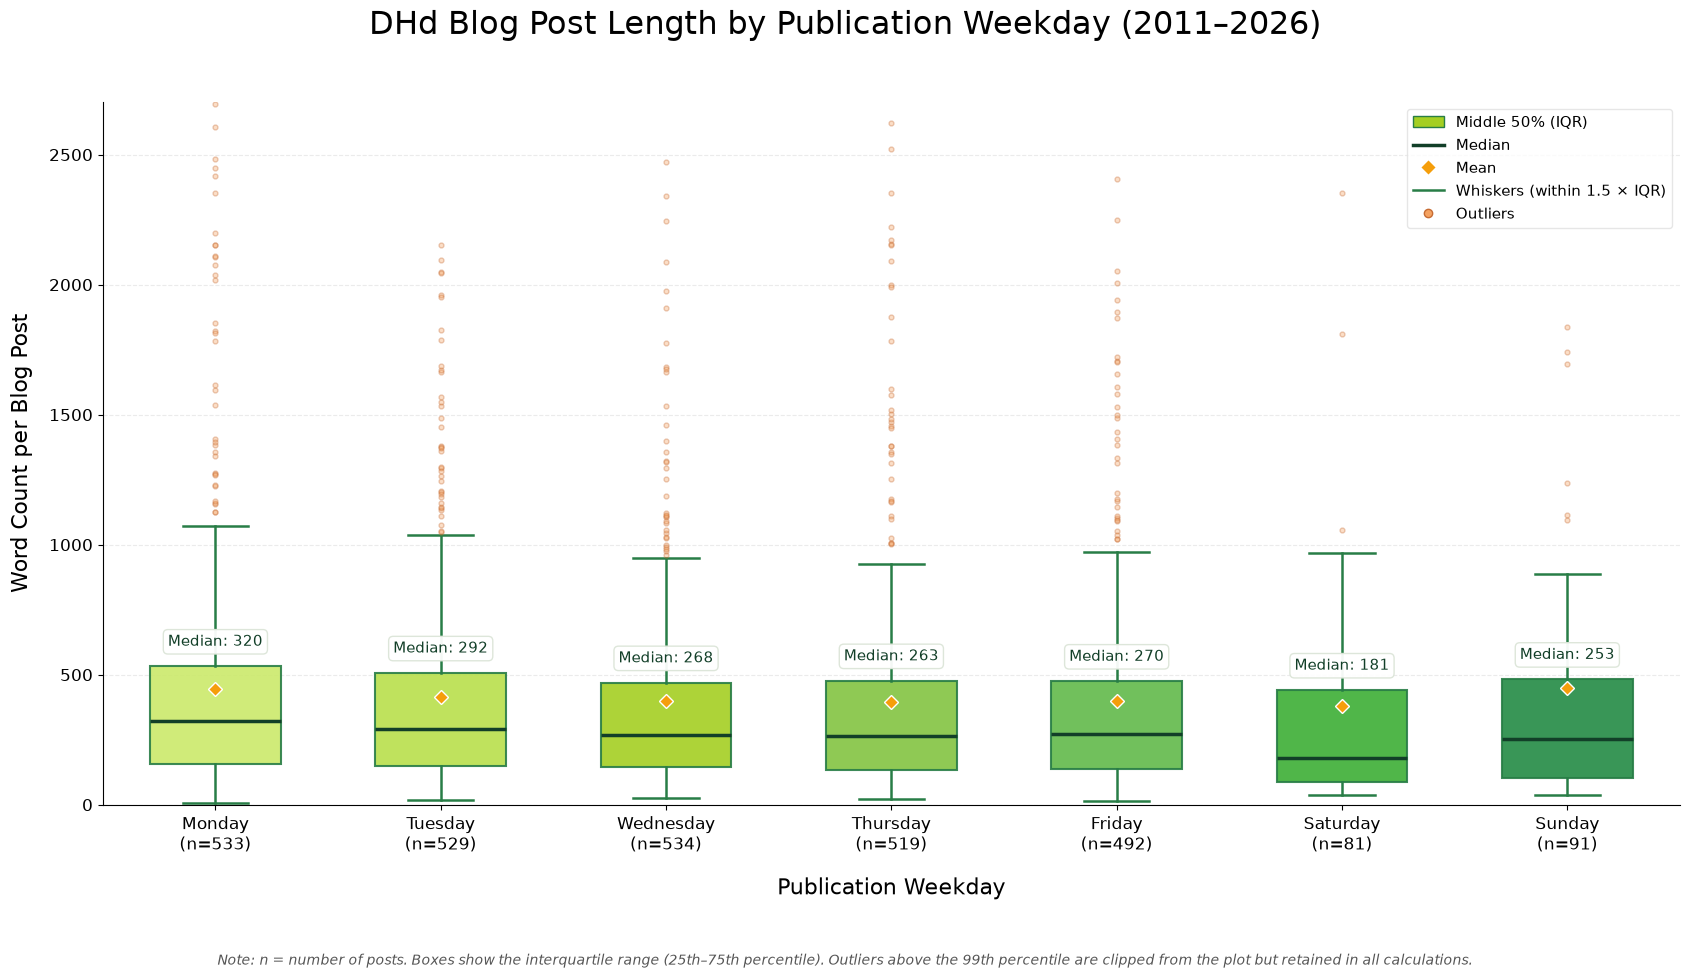


========== KRUSKAL-WALLIS TEST ==========
H statistic: 18.961
P-value: 0.00423
Result: Statistically significant differences in post-length distributions across weekdays.

========== WEEKDAY SUMMARY ==========


,posts,mean_words,median_words,minimum_words,maximum_words
weekday,,,,,
Monday,533,446.3,320.0,8,4393
Tuesday,529,413.2,292.0,19,4690
Wednesday,534,398.5,268.0,25,4171
Thursday,519,396.2,263.0,22,4316
Friday,492,399.5,270.5,13,3413
Saturday,81,379.0,181.0,36,3875
Sunday,91,447.8,253.0,36,6022


In [61]:

# ============================================================
# POST LENGTH × PUBLICATION WEEKDAY
# ============================================================
# Purpose:
# - Examine whether post length varies by publication weekday.
# - Compare median and average word counts across weekdays.
# - Display outliers and post counts.
# - Test whether differences are statistically significant.
# ============================================================


# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

weekday_length_df = analysis_df[
    ["post_id", "publication_date", "word_count"]
].copy()

weekday_length_df["publication_date"] = pd.to_datetime(
    weekday_length_df["publication_date"],
    errors="coerce"
)

weekday_length_df["word_count"] = pd.to_numeric(
    weekday_length_df["word_count"],
    errors="coerce"
)

weekday_length_df = weekday_length_df.dropna(
    subset=["publication_date", "word_count"]
)

weekday_length_df = weekday_length_df[
    weekday_length_df["word_count"] > 0
].copy()

weekday_length_df["weekday"] = (
    weekday_length_df["publication_date"]
    .dt.day_name()
)

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]


# ------------------------------------------------------------
# 2. CALCULATE SUMMARY STATISTICS
# ------------------------------------------------------------

weekday_length_summary = (
    weekday_length_df
    .groupby("weekday")["word_count"]
    .agg(
        posts="count",
        mean_words="mean",
        median_words="median",
        minimum_words="min",
        maximum_words="max"
    )
    .reindex(weekday_order)
    .round(1)
)

print("Post length by publication weekday:")

display(weekday_length_summary)


# ------------------------------------------------------------
# 3. PREPARE BOXPLOT DATA
# ------------------------------------------------------------

available_weekdays = [
    day
    for day in weekday_order
    if (
        weekday_length_df["weekday"] == day
    ).any()
]

box_data = [
    weekday_length_df.loc[
        weekday_length_df["weekday"] == day,
        "word_count"
    ].values
    for day in available_weekdays
]

# DHd-inspired green palette
box_colors = [
    "#CBE96B",
    "#B8DF4B",
    "#A4CF22",
    "#83C441",
    "#62B94A",
    "#3DAE35",
    "#238B45"
]


# ------------------------------------------------------------
# 4. CREATE BOXPLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(17, 10))

boxplot = ax.boxplot(
    box_data,
    tick_labels=available_weekdays,
    patch_artist=True,
    widths=0.58,
    showfliers=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#F59E0B",
        "markeredgecolor": "#FFFFFF",
        "markersize": 7
    },
    medianprops={
        "linewidth": 2.5,
        "color": "#123F28"
    },
    whiskerprops={
        "linewidth": 1.8,
        "color": "#287D46"
    },
    capprops={
        "linewidth": 1.8,
        "color": "#287D46"
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "#F4A261",
        "markeredgecolor": "#C66B32",
        "markersize": 3.5,
        "alpha": 0.35
    }
)

for patch, color in zip(
    boxplot["boxes"],
    box_colors
):
    patch.set_facecolor(color)
    patch.set_edgecolor("#287D46")
    patch.set_linewidth(1.5)
    patch.set_alpha(0.9)


# ------------------------------------------------------------
# 5. ADD MEDIAN AND POST COUNT LABELS
# ------------------------------------------------------------

for position, day in enumerate(
    available_weekdays,
    start=1
):

    day_values = weekday_length_df.loc[
        weekday_length_df["weekday"] == day,
        "word_count"
    ]

    median_value = day_values.median()
    post_count = len(day_values)

    # Median label above each box
    upper_quartile = day_values.quantile(0.75)

    ax.annotate(
        f"Median: {median_value:.0f}",
        xy=(position, upper_quartile),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="medium",
        color="#123F28",
        bbox=dict(
            boxstyle="round,pad=0.30",
            facecolor="#FFFFFF",
            edgecolor="#DCE5D8",
            alpha=0.95
        )
    )


# ------------------------------------------------------------
# 6. TITLE AND AXIS LABELS
# ------------------------------------------------------------

fig.suptitle(
    "DHd Blog Post Length by Publication Weekday (2011–2026)",
    fontsize=23,
    fontweight="medium",
    y=0.97
)

ax.set_xlabel(
    "Publication Weekday",
    fontsize=16,
    labelpad=16
)

ax.set_ylabel(
    "Word Count per Blog Post",
    fontsize=16,
    labelpad=12
)

# Add post counts directly beneath weekday names
weekday_labels = [
    f"{day}\n(n={len(values)})"
    for day, values in zip(
        available_weekdays,
        box_data
    )
]

ax.set_xticks(
    range(1, len(available_weekdays) + 1)
)

ax.set_xticklabels(
    weekday_labels,
    fontsize=12
)

ax.tick_params(
    axis="y",
    labelsize=12
)

# Show outliers up to 99th percentile.
# More extreme values remain in all calculations.
display_limit = (
    weekday_length_df["word_count"].quantile(0.99) * 1.15
)

ax.set_ylim(
    0,
    display_limit
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ------------------------------------------------------------
# 7. ADD LEGEND
# ------------------------------------------------------------

legend_items = [
    Patch(
        facecolor="#A4CF22",
        edgecolor="#287D46",
        label="Middle 50% (IQR)"
    ),
    Line2D(
        [0], [0],
        color="#123F28",
        linewidth=2.5,
        label="Median"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#F59E0B",
        markeredgecolor="white",
        markersize=8,
        label="Mean"
    ),
    Line2D(
        [0], [0],
        color="#287D46",
        linewidth=1.8,
        label="Whiskers (within 1.5 × IQR)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#F4A261",
        markeredgecolor="#C66B32",
        markersize=6,
        label="Outliers"
    )
]

ax.legend(
    handles=legend_items,
    loc="upper right",
    fontsize=11,
    frameon=True,
    facecolor="white",
    edgecolor="#E0E0E0"
)


# ------------------------------------------------------------
# 8. ADD FIGURE NOTE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    (
        "Note: n = number of posts. Boxes show the interquartile range "
        "(25th–75th percentile). Outliers above the 99th percentile "
        "are clipped from the plot but retained in all calculations."
    ),
    ha="center",
    fontsize=10,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.065, 1, 0.94]
)


# ------------------------------------------------------------
# 9. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "post_length_by_publication_weekday.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 10. STATISTICAL TEST
# ------------------------------------------------------------

test_groups = [
    values
    for values in box_data
    if len(values) >= 2
]

if len(test_groups) >= 2:

    statistic, p_value = kruskal(
        *test_groups
    )

    print("\n========== KRUSKAL-WALLIS TEST ==========")
    print(f"H statistic: {statistic:.3f}")
    print(f"P-value: {p_value:.5f}")

    if p_value < 0.05:
        print(
            "Result: Statistically significant differences "
            "in post-length distributions across weekdays."
        )
    else:
        print(
            "Result: No statistically significant differences "
            "in post-length distributions detected."
        )

else:
    print(
        "Insufficient weekday groups for statistical testing."
    )


# ------------------------------------------------------------
# 11. DISPLAY SUMMARY
# ------------------------------------------------------------

print("\n========== WEEKDAY SUMMARY ==========")

display(
    weekday_length_summary
)


## 25. Investigating the Publication Decline (2021–2026)

Latest publication date: 2026-10-13
Total analyzed posts: 2779

========== OVERALL DECLINE ==========
Total posts: 235 → 151
Net decline: 84 posts
Overall decline: 35.7%
Job ads: 87 → 27
Other posts: 148 → 124
Job advertisements explain 71.4% of the numerical net decline.


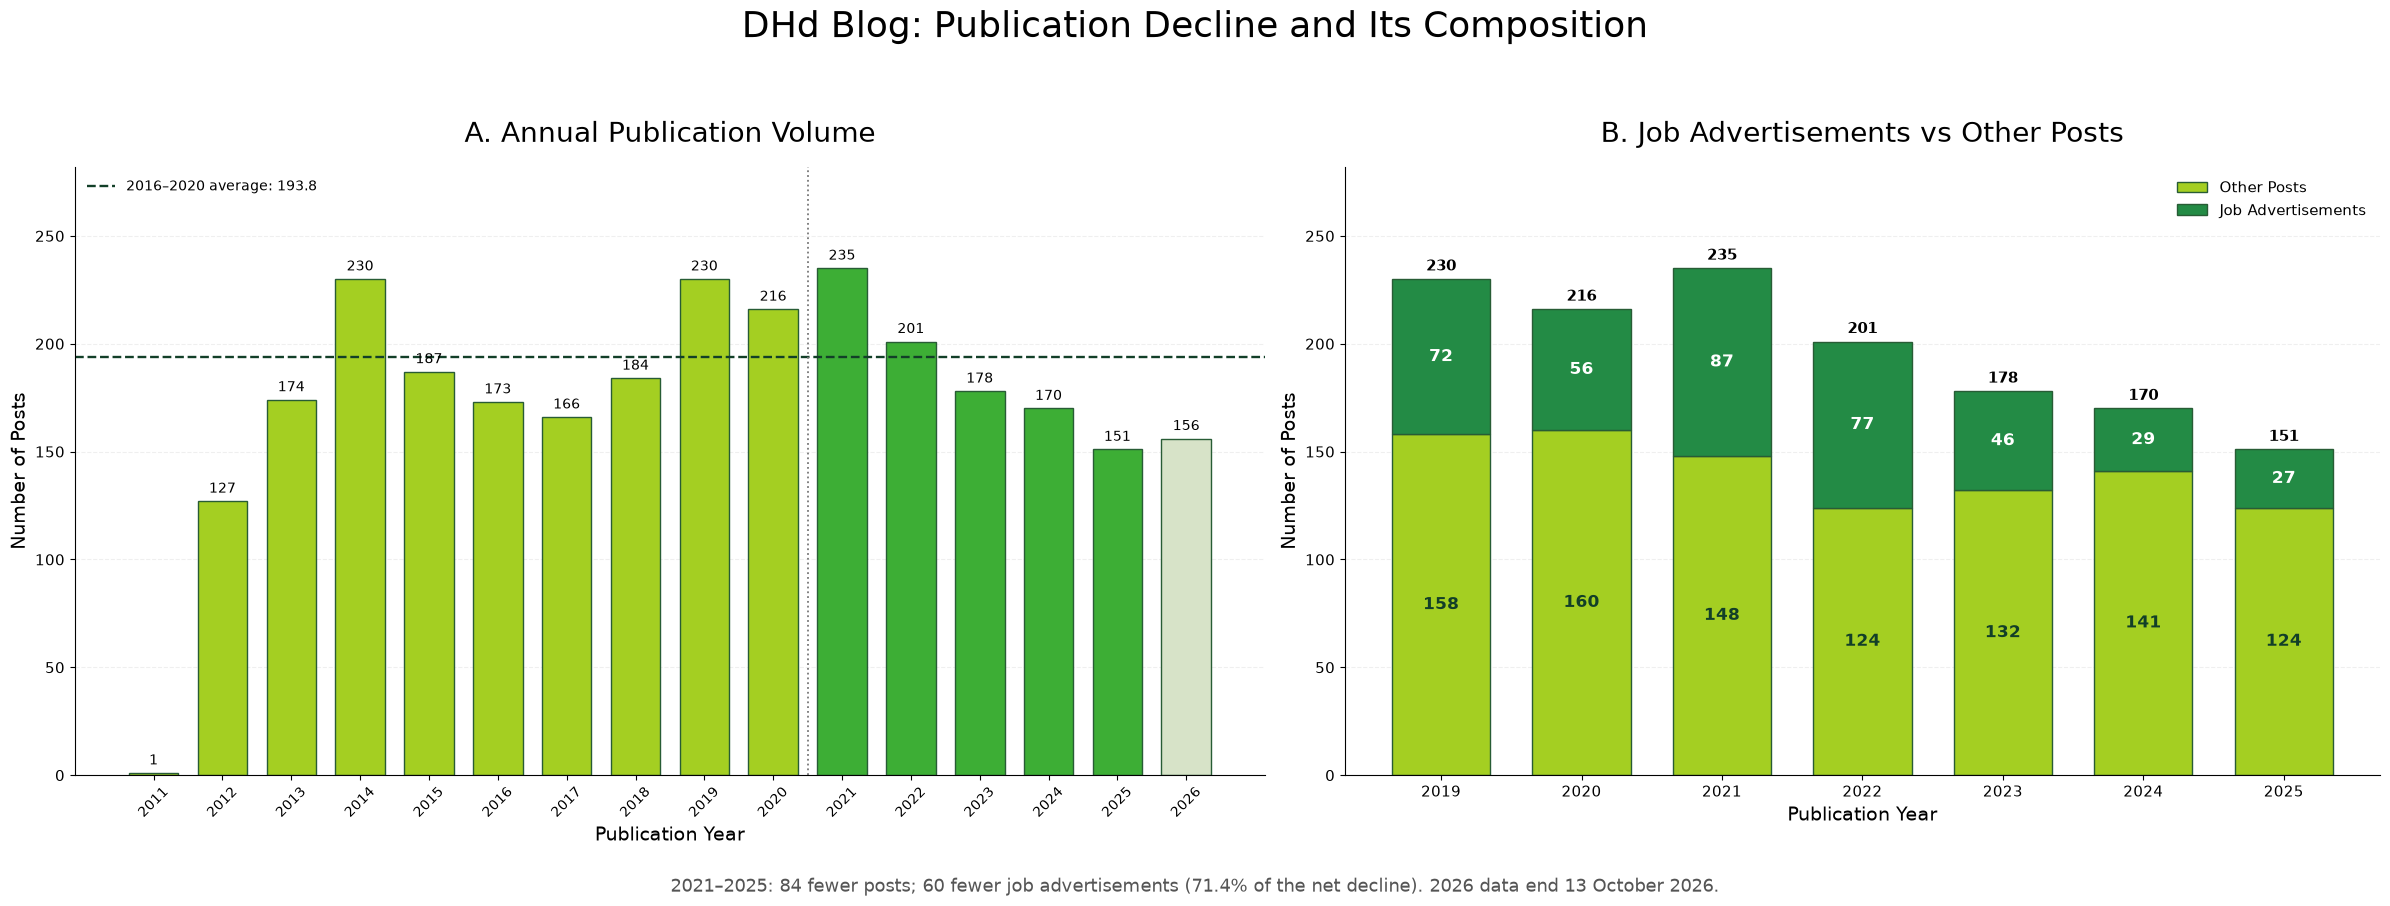


========== CATEGORY CHANGES ==========


year,2021,2025,Change
category,,,
Allgemein,105,92,-13
Stellenanzeigen,87,27,-60
Community,54,52,-2
Veranstaltungen,41,66,25
Forschungsdaten,34,14,-20
Forschungsinfrastruktur,32,18,-14
Call,28,21,-7
Forschung,25,16,-9
Konferenz,23,23,0


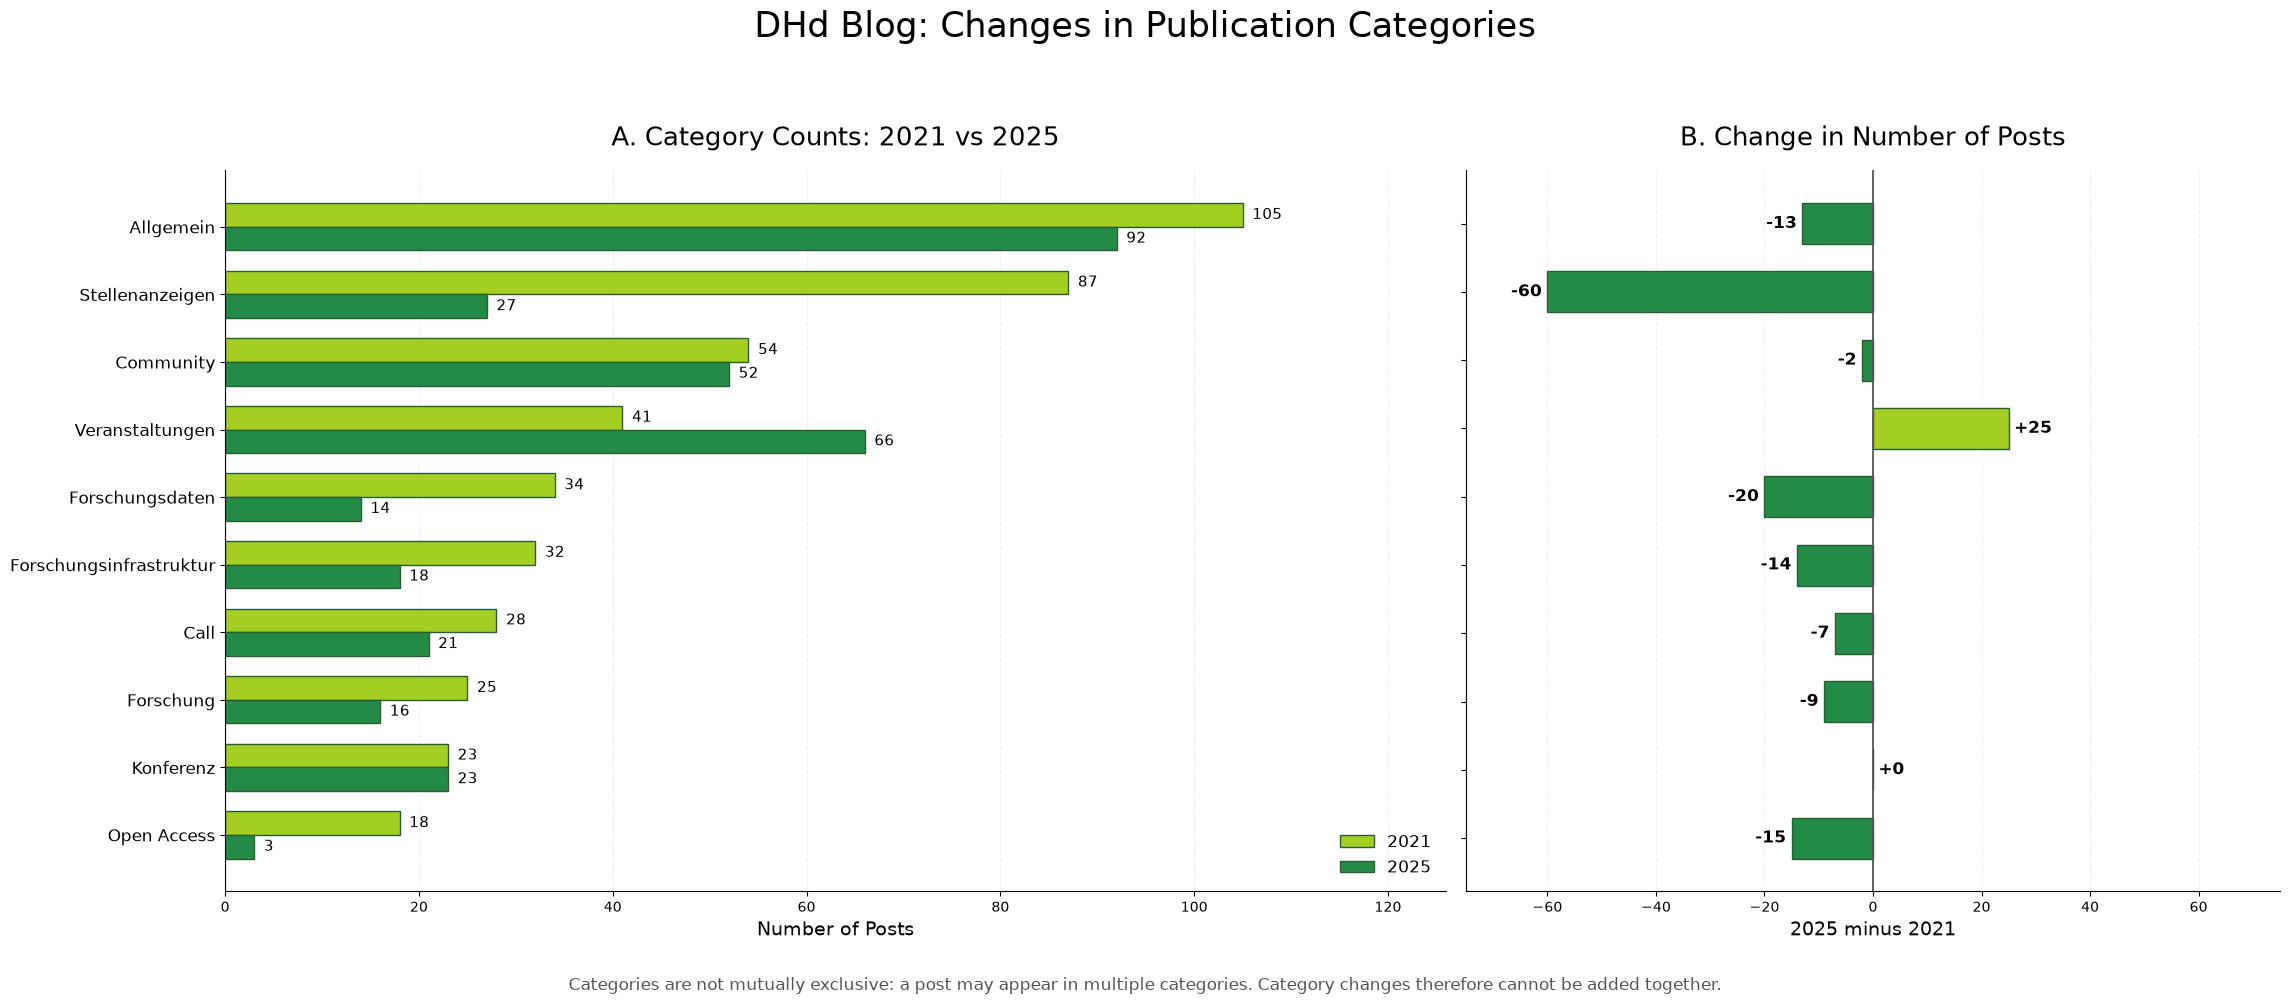


========== CONTRIBUTORS BY PUBLICATION TYPE ==========


publication_type,Job Advertisements,Other Posts
year,,
2019,30,59
2020,27,66
2021,32,60
2022,37,60
2023,26,63
2024,18,61
2025,14,60



========== CONTRIBUTOR OVERLAP ==========


,Job Only,Other Only,Both Types,Total
year,,,,
2019,13,42,17,72
2020,14,53,13,80
2021,18,46,14,78
2022,23,46,14,83
2023,16,53,10,79
2024,13,56,5,74
2025,10,56,4,70



========== 2021 VS 2025 CONTRIBUTOR CHANGE ==========
Job Advertisements: 32 → 14 (-18)
Other Posts: 60 → 60 (+0)


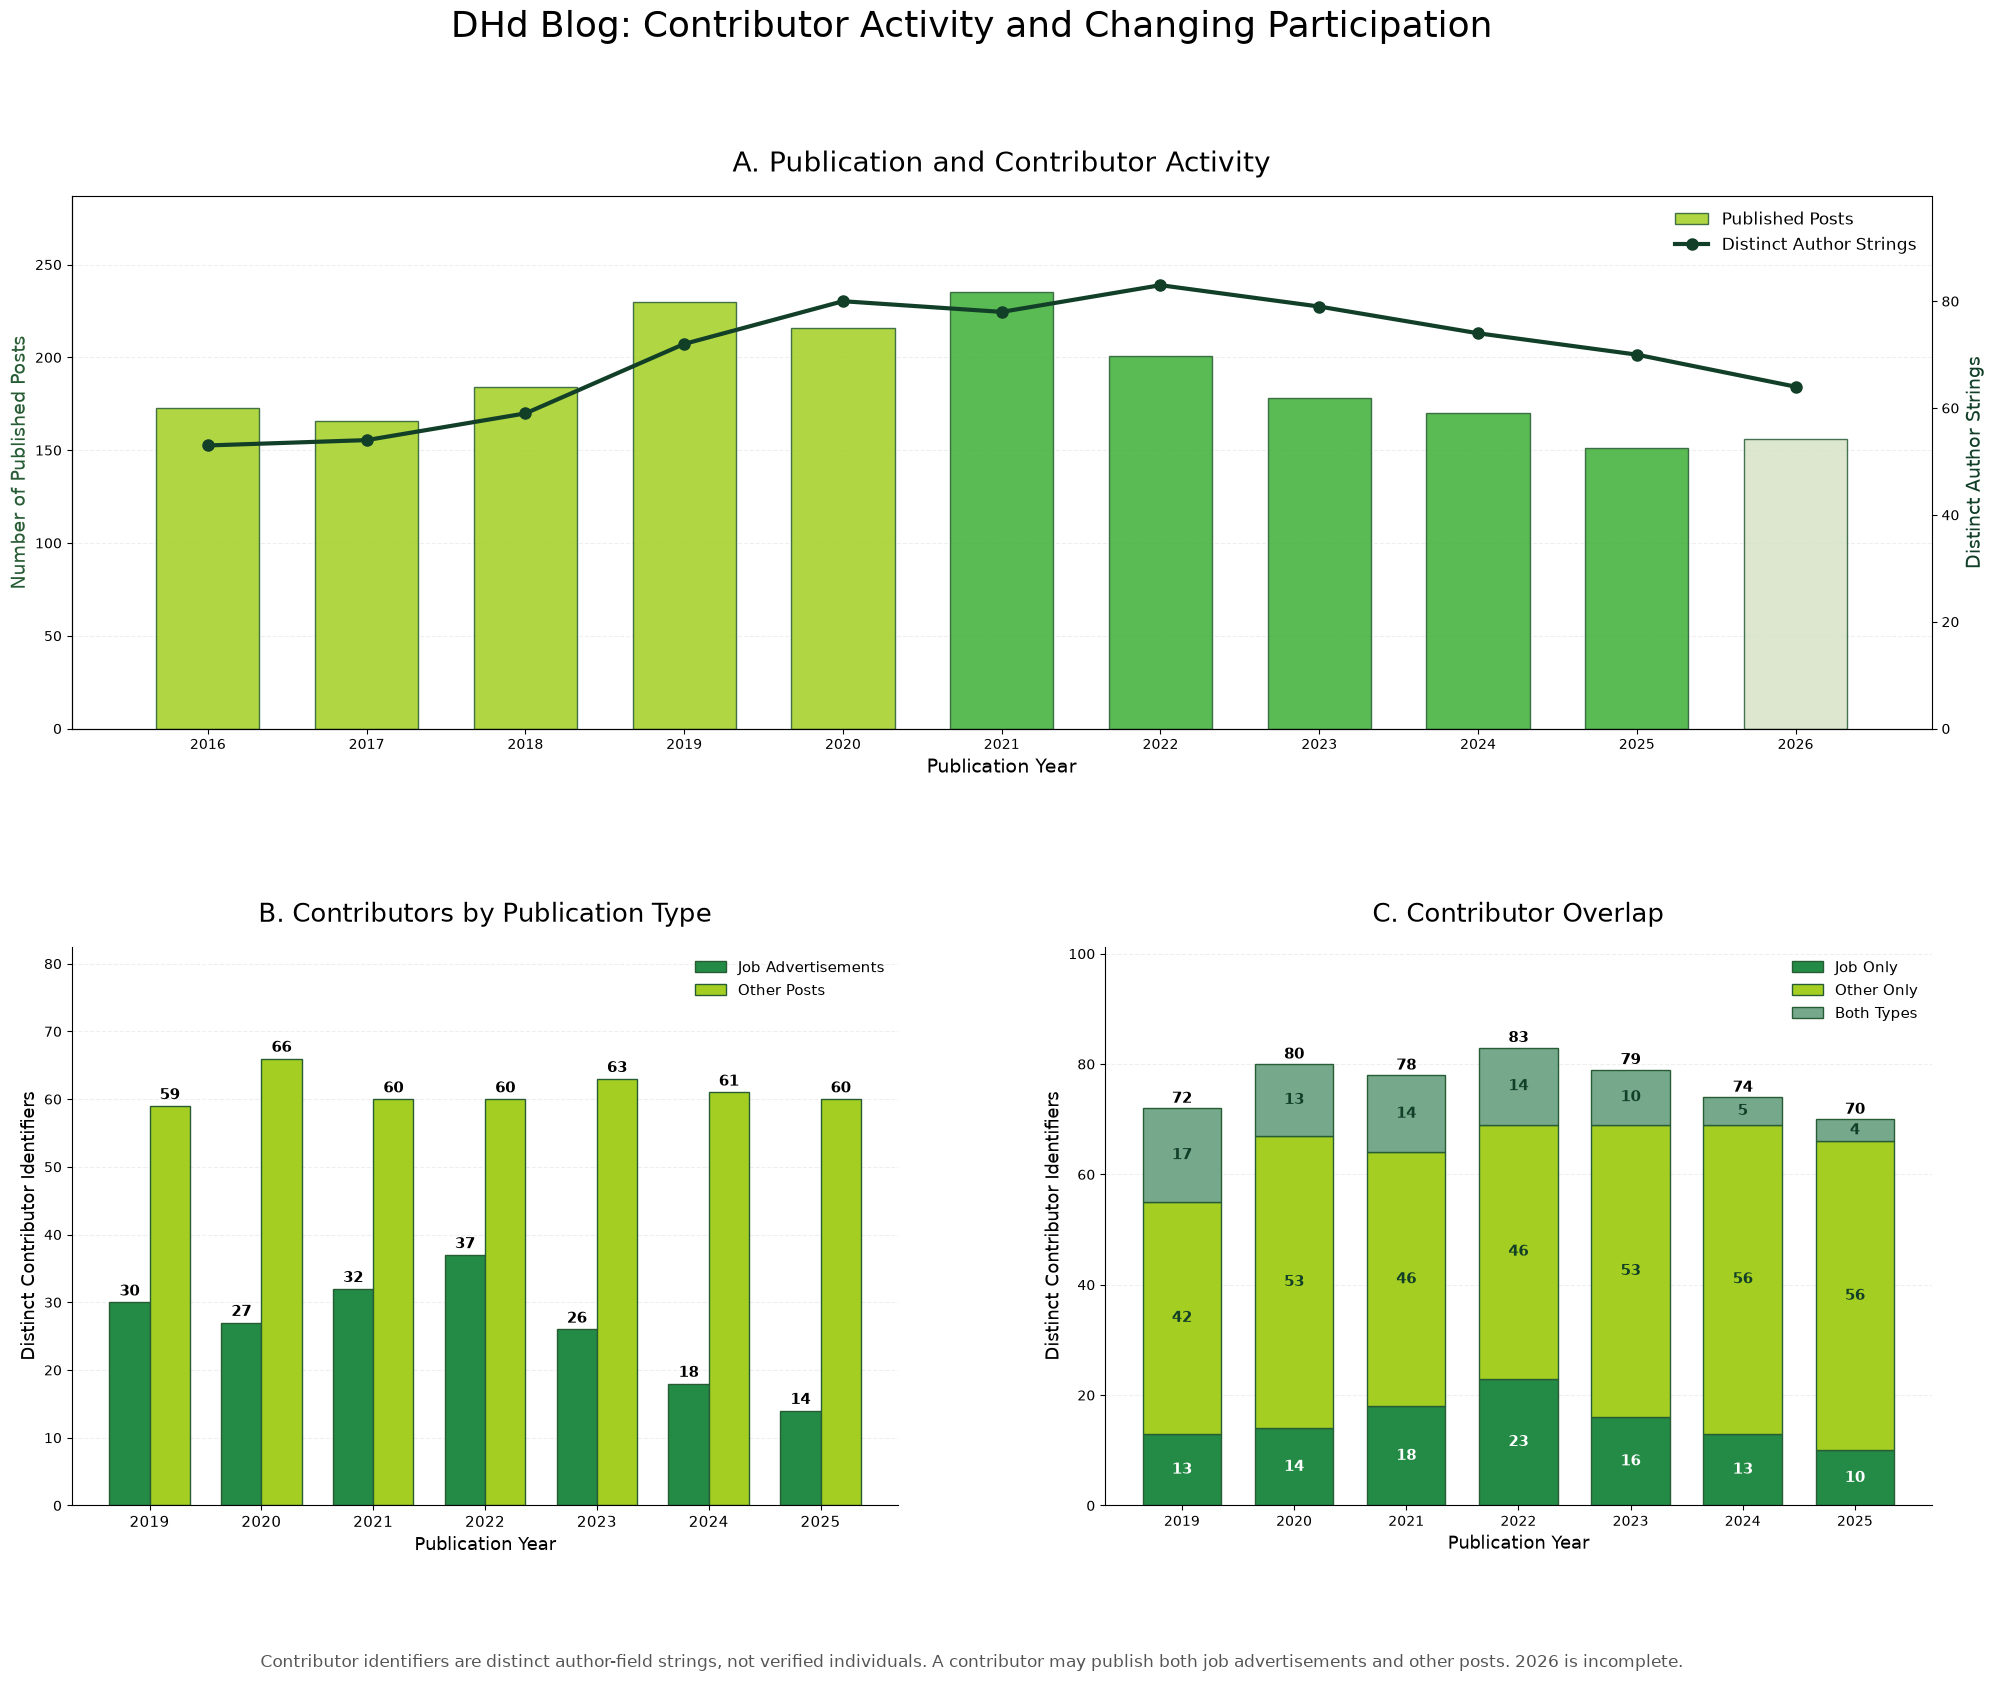


========== FINAL RESEARCH SUMMARY ==========
1. Total publications: 235 → 151 (84 fewer posts).
2. Job advertisements: 87 → 27 (60 fewer posts).
3. Other posts: 148 → 124 (24 fewer posts).
4. Job advertisements account for 71.4% of the net decline.
5. Job-advertisement contributors: 32 → 14.
6. Other-post contributors: 60 → 60.
7. Contributors publishing both types: 14 → 4.

========== FIGURES SAVED ==========
25_figure_1_publication_decline.png
25_figure_2_category_changes.png
25_figure_3_contributor_activity.png


In [62]:

# ============================================================
# 25. INVESTIGATING THE DHd BLOG PUBLICATION DECLINE
# ============================================================
# Three figures tell one connected research story:
#
# FIGURE 1: Overall decline and publication composition
# FIGURE 2: Changes in publication categories
# FIGURE 3: Contributor activity and publication types
#
# Comparison: 2021 vs 2025 (complete calendar years)
# 2026 is shown only as incomplete contextual data.
#
# Each figure contains multiple coordinated panels.
# All figures are saved AND displayed in Jupyter.
# ============================================================


# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

decline_df = analysis_df[
    ["post_id", "publication_date", "year", "categories", "author"]
].copy()

decline_df["publication_date"] = pd.to_datetime(
    decline_df["publication_date"], errors="coerce"
)

decline_df["year"] = pd.to_numeric(
    decline_df["year"], errors="coerce"
)

decline_df = decline_df.dropna(
    subset=["post_id", "publication_date", "year"]
).copy()

decline_df["year"] = decline_df["year"].astype(int)

decline_df = decline_df[
    decline_df["year"].between(2011, 2026)
].drop_duplicates(subset=["post_id"])

decline_df["categories"] = (
    decline_df["categories"].fillna("").astype(str)
)

decline_df["author"] = (
    decline_df["author"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

decline_df["is_job_ad"] = (
    decline_df["categories"]
    .str.split(r"\s*\|\s*")
    .apply(
        lambda values: any(
            value.strip().casefold() == "stellenanzeigen"
            for value in values
        )
    )
)

decline_df["publication_type"] = np.where(
    decline_df["is_job_ad"],
    "Job Advertisements",
    "Other Posts"
)

latest_date = decline_df["publication_date"].max()

GREEN_DARK = "#238B45"
GREEN_LIME = "#A4CF22"
GREEN_DEEP = "#123F28"
GREEN_MUTED = "#76A98B"
GREEN_LIGHT = "#D7E3C8"

print("Latest publication date:", latest_date.date())
print("Total analyzed posts:", decline_df["post_id"].nunique())


# ------------------------------------------------------------
# 2. CALCULATE ANNUAL PUBLICATION COUNTS
# ------------------------------------------------------------

annual_posts = (
    decline_df.groupby("year")["post_id"]
    .nunique()
    .reindex(range(2011, 2027), fill_value=0)
)

job_summary = (
    decline_df.groupby("year")
    .agg(
        total_posts=("post_id", "nunique"),
        job_posts=("is_job_ad", "sum")
    )
)

job_summary["other_posts"] = (
    job_summary["total_posts"] - job_summary["job_posts"]
)

posts_2021 = int(annual_posts.loc[2021])
posts_2025 = int(annual_posts.loc[2025])

total_decline = posts_2021 - posts_2025

jobs_2021 = int(job_summary.loc[2021, "job_posts"])
jobs_2025 = int(job_summary.loc[2025, "job_posts"])

other_2021 = int(job_summary.loc[2021, "other_posts"])
other_2025 = int(job_summary.loc[2025, "other_posts"])

job_decline = jobs_2021 - jobs_2025
other_decline = other_2021 - other_2025

job_share_of_decline = (
    100 * job_decline / total_decline
    if total_decline else np.nan
)

print("\n========== OVERALL DECLINE ==========")

print(f"Total posts: {posts_2021} → {posts_2025}")
print(f"Net decline: {total_decline} posts")
print(
    f"Overall decline: "
    f"{100 * total_decline / posts_2021:.1f}%"
)

print(f"Job ads: {jobs_2021} → {jobs_2025}")
print(f"Other posts: {other_2021} → {other_2025}")

print(
    f"Job advertisements explain "
    f"{job_share_of_decline:.1f}% "
    f"of the numerical net decline."
)


# ============================================================
# FIGURE 1: OVERALL DECLINE AND PUBLICATION COMPOSITION
# ============================================================
# Left: Annual publication volume, 2011–2026
# Right: Job advertisements vs other posts, 2019–2025
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(24, 9),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

# ------------------------------------------------------------
# 3. PANEL A: ANNUAL PUBLICATION VOLUME
# ------------------------------------------------------------

years_all = annual_posts.index.to_numpy()
values_all = annual_posts.values

colors_all = [
    GREEN_LIME if year < 2021
    else "#3DAE35" if year < 2026
    else GREEN_LIGHT
    for year in years_all
]

bars = ax1.bar(
    years_all,
    values_all,
    color=colors_all,
    edgecolor="#285C35",
    width=0.72
)

for bar, value in zip(bars, values_all):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        value + 4,
        str(int(value)),
        ha="center",
        fontsize=10
    )

baseline = annual_posts.loc[2016:2020].mean()

ax1.axhline(
    baseline,
    linestyle="--",
    color=GREEN_DEEP,
    linewidth=1.7,
    label=f"2016–2020 average: {baseline:.1f}"
)

ax1.axvline(
    2020.5,
    linestyle=":",
    color="#777777",
    linewidth=1.3
)

ax1.set_title(
    "A. Annual Publication Volume",
    fontsize=20,
    pad=18
)

ax1.set_xlabel("Publication Year", fontsize=14)
ax1.set_ylabel("Number of Posts", fontsize=14)

ax1.set_xticks(years_all)
ax1.tick_params(axis="x", rotation=45, labelsize=10)
ax1.tick_params(axis="y", labelsize=11)

ax1.set_ylim(0, values_all.max() * 1.2)

ax1.legend(fontsize=10, frameon=False, loc="upper left")

ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)


# ------------------------------------------------------------
# 4. PANEL B: JOB ADVERTISEMENTS VS OTHER POSTS
# ------------------------------------------------------------

years_recent = np.arange(2019, 2026)

job_values = job_summary.loc[
    years_recent, "job_posts"
].values

other_values = job_summary.loc[
    years_recent, "other_posts"
].values

total_values = job_summary.loc[
    years_recent, "total_posts"
].values

ax2.bar(
    years_recent,
    other_values,
    color=GREEN_LIME,
    edgecolor="#285C35",
    width=0.7,
    label="Other Posts"
)

ax2.bar(
    years_recent,
    job_values,
    bottom=other_values,
    color=GREEN_DARK,
    edgecolor="#285C35",
    width=0.7,
    label="Job Advertisements"
)

for year, other, jobs, total in zip(
    years_recent, other_values, job_values, total_values
):

    ax2.text(
        year,
        other / 2,
        str(int(other)),
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=GREEN_DEEP
    )

    if jobs > 0:
        ax2.text(
            year,
            other + jobs / 2,
            str(int(jobs)),
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white"
        )

    ax2.text(
        year,
        total + 4,
        str(int(total)),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax2.set_title(
    "B. Job Advertisements vs Other Posts",
    fontsize=20,
    pad=18
)

ax2.set_xlabel("Publication Year", fontsize=14)
ax2.set_ylabel("Number of Posts", fontsize=14)

ax2.set_xticks(years_recent)
ax2.tick_params(axis="both", labelsize=11)

ax2.set_ylim(0, total_values.max() * 1.2)

ax2.legend(
    fontsize=11,
    frameon=False,
    loc="upper right"
)

ax2.grid(axis="y", linestyle="--", alpha=0.2)
ax2.set_axisbelow(True)

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "DHd Blog: Publication Decline and Its Composition",
    fontsize=26,
    y=0.99
)

fig.text(
    0.5, 0.01,
    (
        f"2021–2025: {total_decline} fewer posts; "
        f"{job_decline} fewer job advertisements "
        f"({job_share_of_decline:.1f}% of the net decline). "
        f"2026 data end {latest_date.strftime('%d %B %Y')}."
    ),
    ha="center",
    fontsize=13,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 0.94])

plt.savefig(
    FIGURE_DIR / "25_figure_1_publication_decline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. CALCULATE CATEGORY COUNTS
# ------------------------------------------------------------

category_df = decline_df[
    ["post_id", "year", "categories"]
].copy()

category_df["category"] = (
    category_df["categories"]
    .str.split(r"\s*\|\s*")
)

category_df = category_df.explode("category")

category_df["category"] = (
    category_df["category"]
    .fillna("")
    .str.strip()
)

category_df = category_df[
    category_df["category"].ne("")
].drop_duplicates(
    subset=["post_id", "category"]
)

category_compare = (
    category_df[
        category_df["year"].isin([2021, 2025])
    ]
    .groupby(["category", "year"])["post_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=[2021, 2025], fill_value=0)
)

top_categories = (
    category_compare[2021]
    .sort_values(ascending=False)
    .head(10)
    .index
)

category_compare = category_compare.loc[
    top_categories
].copy()

category_compare["Change"] = (
    category_compare[2025] - category_compare[2021]
)

print("\n========== CATEGORY CHANGES ==========")

display(category_compare)


# ============================================================
# FIGURE 2: WHICH PUBLICATION CATEGORIES CHANGED?
# ============================================================
# Left: Absolute counts in 2021 vs 2025
# Right: Net change in each category
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(23, 10),
    gridspec_kw={"width_ratios": [1.35, 0.9]}
)

positions = np.arange(len(category_compare))
bar_width = 0.35

# ------------------------------------------------------------
# 6. PANEL A: CATEGORY COUNTS
# ------------------------------------------------------------

bars_2021 = ax1.barh(
    positions - bar_width / 2,
    category_compare[2021],
    height=bar_width,
    color=GREEN_LIME,
    edgecolor="#285C35",
    label="2021"
)

bars_2025 = ax1.barh(
    positions + bar_width / 2,
    category_compare[2025],
    height=bar_width,
    color=GREEN_DARK,
    edgecolor="#285C35",
    label="2025"
)

for bars in [bars_2021, bars_2025]:
    for bar in bars:
        ax1.text(
            bar.get_width() + 1,
            bar.get_y() + bar.get_height() / 2,
            str(int(bar.get_width())),
            va="center",
            fontsize=11
        )

ax1.set_yticks(positions)
ax1.set_yticklabels(category_compare.index, fontsize=12)

ax1.invert_yaxis()

ax1.set_title(
    "A. Category Counts: 2021 vs 2025",
    fontsize=19,
    pad=18
)

ax1.set_xlabel("Number of Posts", fontsize=14)

ax1.set_xlim(
    0,
    category_compare[[2021, 2025]].to_numpy().max() * 1.2
)

ax1.legend(fontsize=12, frameon=False, loc="lower right")
ax1.grid(axis="x", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)


# ------------------------------------------------------------
# 7. PANEL B: NET CHANGE BY CATEGORY
# ------------------------------------------------------------

changes = category_compare["Change"].values

change_colors = [
    GREEN_DARK if value < 0 else GREEN_LIME
    for value in changes
]

ax2.barh(
    positions,
    changes,
    color=change_colors,
    edgecolor="#285C35",
    height=0.6
)

ax2.axvline(0, color="#555555", linewidth=1.3)

for pos, value in zip(positions, changes):

    ax2.text(
        value - 1 if value < 0 else value + 1,
        pos,
        f"{value:+d}",
        va="center",
        ha="right" if value < 0 else "left",
        fontsize=12,
        fontweight="bold"
    )

ax2.set_yticks(positions)
ax2.set_yticklabels([])

ax2.invert_yaxis()

ax2.set_title(
    "B. Change in Number of Posts",
    fontsize=19,
    pad=18
)

ax2.set_xlabel("2025 minus 2021", fontsize=14)

change_limit = max(abs(changes.min()), abs(changes.max())) * 1.25

ax2.set_xlim(-change_limit, change_limit)

ax2.grid(axis="x", linestyle="--", alpha=0.2)
ax2.set_axisbelow(True)

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "DHd Blog: Changes in Publication Categories",
    fontsize=25,
    y=0.99
)

fig.text(
    0.5, 0.01,
    (
        "Categories are not mutually exclusive: "
        "a post may appear in multiple categories. "
        "Category changes therefore cannot be added together."
    ),
    ha="center",
    fontsize=12,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 0.94])

plt.savefig(
    FIGURE_DIR / "25_figure_2_category_changes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. CALCULATE CONTRIBUTOR ACTIVITY
# ------------------------------------------------------------

author_df = decline_df[
    decline_df["author"].ne("")
].copy()

annual_authors = (
    author_df
    .groupby("year")["author"]
    .nunique()
    .reindex(range(2011, 2027), fill_value=0)
)

contributor_counts = (
    author_df[
        author_df["year"].between(2019, 2025)
    ]
    .groupby(["year", "publication_type"])["author"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        index=range(2019, 2026),
        columns=["Job Advertisements", "Other Posts"],
        fill_value=0
    )
)

overlap_records = []

for year in range(2019, 2026):

    year_df = author_df[
        author_df["year"] == year
    ]

    job_authors = set(
        year_df.loc[
            year_df["is_job_ad"], "author"
        ]
    )

    other_authors = set(
        year_df.loc[
            ~year_df["is_job_ad"], "author"
        ]
    )

    overlap_records.append({
        "year": year,
        "Job Only": len(job_authors - other_authors),
        "Other Only": len(other_authors - job_authors),
        "Both Types": len(job_authors & other_authors),
        "Total": len(job_authors | other_authors)
    })

overlap_df = pd.DataFrame(
    overlap_records
).set_index("year")

print("\n========== CONTRIBUTORS BY PUBLICATION TYPE ==========")

display(contributor_counts)

print("\n========== CONTRIBUTOR OVERLAP ==========")

display(overlap_df)

print("\n========== 2021 VS 2025 CONTRIBUTOR CHANGE ==========")

for publication_type in [
    "Job Advertisements", "Other Posts"
]:

    before = contributor_counts.loc[
        2021, publication_type
    ]

    after = contributor_counts.loc[
        2025, publication_type
    ]

    print(
        f"{publication_type}: "
        f"{before} → {after} ({after - before:+d})"
    )


# ============================================================
# FIGURE 3: CONTRIBUTOR ACTIVITY AND COMPOSITION
# ============================================================
# A. Total annual contributors and posts
# B. Contributors by publication type
# C. Contributor overlap
# ============================================================

fig = plt.figure(figsize=(24, 17))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1, 1.05],
    hspace=0.4,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])


# ------------------------------------------------------------
# 9. PANEL A: ANNUAL POSTS AND CONTRIBUTOR IDENTIFIERS
# ------------------------------------------------------------

recent_years = list(range(2016, 2027))

posts_recent = annual_posts.loc[recent_years]
authors_recent = annual_authors.loc[recent_years]

bars = ax1.bar(
    recent_years,
    posts_recent,
    width=0.65,
    color=[
        GREEN_LIME if year < 2021
        else "#3DAE35" if year < 2026
        else GREEN_LIGHT
        for year in recent_years
    ],
    edgecolor="#285C35",
    alpha=0.85,
    label="Published Posts"
)

ax1.set_title(
    "A. Publication and Contributor Activity",
    fontsize=20,
    pad=18
)

ax1.set_xlabel("Publication Year", fontsize=14)

ax1.set_ylabel(
    "Number of Published Posts",
    fontsize=14,
    color="#285C35"
)

ax1.set_xticks(recent_years)
ax1.set_ylim(0, posts_recent.max() * 1.22)

ax1_right = ax1.twinx()

line = ax1_right.plot(
    recent_years,
    authors_recent,
    color=GREEN_DEEP,
    marker="o",
    linewidth=3,
    markersize=8,
    label="Distinct Author Strings"
)

ax1_right.set_ylabel(
    "Distinct Author Strings",
    fontsize=14,
    color=GREEN_DEEP
)

ax1_right.set_ylim(0, authors_recent.max() * 1.2)

ax1.legend(
    [bars, line[0]],
    ["Published Posts", "Distinct Author Strings"],
    loc="upper right",
    fontsize=12,
    frameon=False
)

ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)


# ------------------------------------------------------------
# 10. PANEL B: CONTRIBUTORS BY PUBLICATION TYPE
# ------------------------------------------------------------

years = np.arange(2019, 2026)
x = np.arange(len(years))
width = 0.36

job_contributors = contributor_counts[
    "Job Advertisements"
].values

other_contributors = contributor_counts[
    "Other Posts"
].values

bars_jobs = ax2.bar(
    x - width / 2,
    job_contributors,
    width=width,
    color=GREEN_DARK,
    edgecolor="#285C35",
    label="Job Advertisements"
)

bars_other = ax2.bar(
    x + width / 2,
    other_contributors,
    width=width,
    color=GREEN_LIME,
    edgecolor="#285C35",
    label="Other Posts"
)

for bars_group in [bars_jobs, bars_other]:
    for bar in bars_group:
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            str(int(bar.get_height())),
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

ax2.set_title(
    "B. Contributors by Publication Type",
    fontsize=19,
    pad=18
)

ax2.set_xlabel("Publication Year", fontsize=13)
ax2.set_ylabel("Distinct Contributor Identifiers", fontsize=13)

ax2.set_xticks(x)
ax2.set_xticklabels(years, fontsize=11)

ax2.set_ylim(0, max(other_contributors) * 1.25)

ax2.legend(
    fontsize=11,
    frameon=False,
    loc="upper right"
)

ax2.grid(axis="y", linestyle="--", alpha=0.2)
ax2.set_axisbelow(True)


# ------------------------------------------------------------
# 11. PANEL C: CONTRIBUTOR OVERLAP
# ------------------------------------------------------------

job_only = overlap_df["Job Only"].values
other_only = overlap_df["Other Only"].values
both_types = overlap_df["Both Types"].values

ax3.bar(
    years,
    job_only,
    color=GREEN_DARK,
    edgecolor="#285C35",
    width=0.7,
    label="Job Only"
)

ax3.bar(
    years,
    other_only,
    bottom=job_only,
    color=GREEN_LIME,
    edgecolor="#285C35",
    width=0.7,
    label="Other Only"
)

ax3.bar(
    years,
    both_types,
    bottom=job_only + other_only,
    color=GREEN_MUTED,
    edgecolor="#285C35",
    width=0.7,
    label="Both Types"
)

for i, year in enumerate(years):

    segments = [
        (job_only[i], 0, "white"),
        (other_only[i], job_only[i], GREEN_DEEP),
        (
            both_types[i],
            job_only[i] + other_only[i],
            GREEN_DEEP
        )
    ]

    for value, bottom, text_color in segments:

        if value > 0:

            ax3.text(
                year,
                bottom + value / 2,
                str(int(value)),
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=text_color
            )

    ax3.text(
        year,
        overlap_df.loc[year, "Total"] + 1,
        str(int(overlap_df.loc[year, "Total"])),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax3.set_title(
    "C. Contributor Overlap",
    fontsize=19,
    pad=18
)

ax3.set_xlabel("Publication Year", fontsize=13)
ax3.set_ylabel("Distinct Contributor Identifiers", fontsize=13)

ax3.set_xticks(years)
ax3.set_ylim(0, overlap_df["Total"].max() * 1.22)

ax3.legend(
    fontsize=11,
    frameon=False,
    loc="upper right"
)

ax3.grid(axis="y", linestyle="--", alpha=0.2)
ax3.set_axisbelow(True)


# ------------------------------------------------------------
# 12. FORMAT FIGURE 3
# ------------------------------------------------------------

for ax in [ax1, ax2, ax3]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "DHd Blog: Contributor Activity and Changing Participation",
    fontsize=26,
    y=0.99
)

fig.text(
    0.5, 0.015,
    (
        "Contributor identifiers are distinct author-field strings, "
        "not verified individuals. A contributor may publish both "
        "job advertisements and other posts. 2026 is incomplete."
    ),
    ha="center",
    fontsize=12,
    color="#555555"
)

plt.savefig(
    FIGURE_DIR / "25_figure_3_contributor_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 13. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n========== FINAL RESEARCH SUMMARY ==========")

print(
    f"1. Total publications: {posts_2021} → {posts_2025} "
    f"({total_decline} fewer posts)."
)

print(
    f"2. Job advertisements: {jobs_2021} → {jobs_2025} "
    f"({job_decline} fewer posts)."
)

print(
    f"3. Other posts: {other_2021} → {other_2025} "
    f"({other_decline} fewer posts)."
)

print(
    f"4. Job advertisements account for "
    f"{job_share_of_decline:.1f}% of the net decline."
)

print(
    "5. Job-advertisement contributors: "
    f"{contributor_counts.loc[2021, 'Job Advertisements']} → "
    f"{contributor_counts.loc[2025, 'Job Advertisements']}."
)

print(
    "6. Other-post contributors: "
    f"{contributor_counts.loc[2021, 'Other Posts']} → "
    f"{contributor_counts.loc[2025, 'Other Posts']}."
)

print(
    "7. Contributors publishing both types: "
    f"{overlap_df.loc[2021, 'Both Types']} → "
    f"{overlap_df.loc[2025, 'Both Types']}."
)

print("\n========== FIGURES SAVED ==========")

print("25_figure_1_publication_decline.png")
print("25_figure_2_category_changes.png")
print("25_figure_3_contributor_activity.png")

